# Original sniper strategy — repaired 50 SOL run

**October 10, 2026, 16:00–17:00 UTC (19:00–20:00 Kyiv) launches only.**
50 SOL starting wallet; unchanged original strategy and 5% entry/exit slippage.
Native conditional protocol replay carries our reserve impact forward and
preserves observed counterpart sell fractions. Verified external token transfers
retain their fixed historical amounts and conserve inventory.

**Realized net PnL: −3.289255885 SOL**, including nine failed-entry fees.
28 positions closed: 14 profitable and 14 losing. One position remains unresolved
with **1.207495000 SOL** cash cost, so final portfolio PnL is unknown. Assigning
zero recovery to that position gives **−4.496750885 SOL**; that is a stress scenario.

Seven previously unresolved positions are now closed, including UP at
**+0.551637313 SOL**. The last position has a verified historical transfer whose
fixed amount exceeds its sender's counterfactual inventory after our intervention.
It has no invented exit or assigned terminal loss.

This notebook reads preserved local results, traces and source evidence. It
does not query production, collect data, trade or run the backtest when reopened.
Its dedicated full-trace replay exactly matches the repaired result's positions,
fills, ledger and entire summary. Earlier notebooks remain preserved separately.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/backtest').is_dir())
sys.path.insert(0, str(ROOT/'notebooks'))
import sniper_repaired_review as review
from IPython.display import Markdown, display
summary = review.load()
display(summary)

,sample,starting_wallet_SOL,slippage_percent,signals,buys,profitable,losing,unresolved,failed_entries,realized_net_PnL_SOL,unresolved_cost_SOL,final_portfolio_PnL_SOL,zero_recovery_stress_SOL
0,2026-10-10 16:00–17:00 UTC launches,50,5,38,29,14,14,1,9,-3.289256,1.207495,None,-4.496751


## Entry and exit rules

An early reference buyer spends at least 1 SOL during the first two launch slots.
The strategy requires positive modeled inventory and unrecovered fee-adjusted
cost. It sizes the buy using the original formula so our 5% net target is below
that buyer's break-even by the configured epsilon. The entry logs record the
actual reference wallet, token inventory, cash cost, creator-fee credit, thresholds,
size, reserves, quoted token output and minimum accepted output.

Orders fill one slot after the decision. Exit is triggered by quoted net PnL
meeting the 5% target, or the 300-second timeout; execution remains subject to
liquidity and 5% minimum-output tolerance. Each token includes the recorded exit
evaluation and actual fill. A failed entry never becomes a losing position:
only its submitted execution fee is charged.

Creator income is modeled event-time accrual for the reference buyer's break-even
calculation. Another wallet's developer fees are not our trading profit. Network
charges and rent are configured scenarios; tips are zero.

In [2]:
display(review.pd.DataFrame([{'parameter':k, 'value':v}
                           for k,v in review.RESULT['summary']['policy'].items()]))

,parameter,value
0,account_rent_lamports,2039280
1,account_rent_refund_lamports,2039280
2,bankroll_lamports,50000000000
3,confirmation_net_lamports,0
4,confirmation_new_buyers,0
5,confirmation_slots,0
6,counterpart_sell_fraction,1
7,creator_fee_credit_enabled,1
8,early_slots,2
9,entry_delay_slots,1


## PnL and cash by slot

The first curve books completed positions and failed-entry fees. The second
shows cash movement, including capital still spent on the unresolved position.
Neither curve assigns a market value to open tokens.

findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


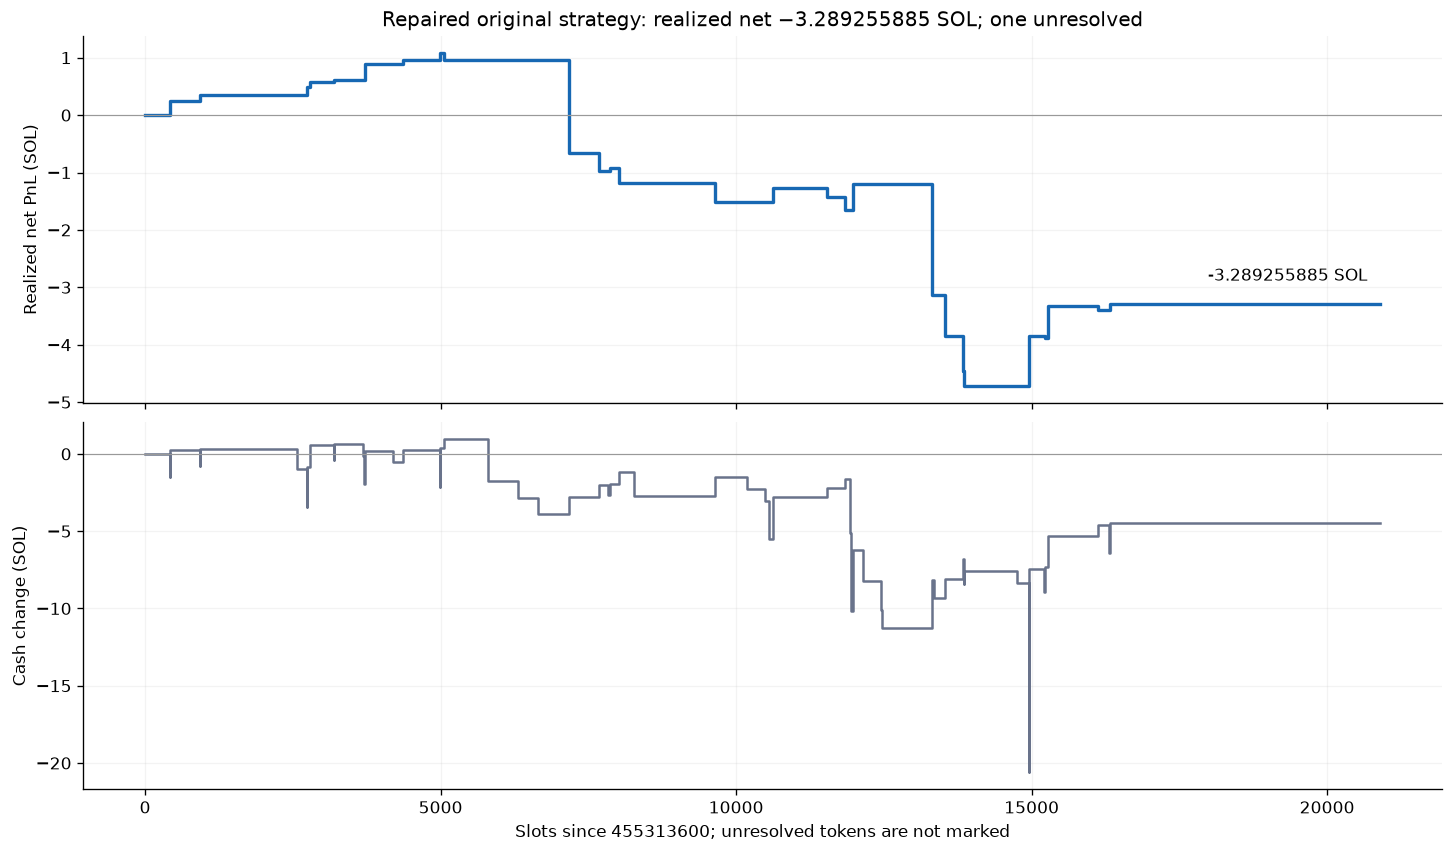

,token,slot,utc,event,pnl_SOL,cumulative_pnl_SOL
0,NEZARA,455314026,2026-10-10T16:01:33+00:00,Position closed,0.246999,0.246999
1,henry,455314535,2026-10-10T16:03:26+00:00,Position closed,0.096347,0.343346
2,p-,455316088,2026-10-10T16:09:09+00:00,Failed entry fee,-0.000105,0.343241
4,Snoopy,455316338,2026-10-10T16:10:03+00:00,Position closed,0.153791,0.497032
3,VYRNO,455316387,2026-10-10T16:10:14+00:00,Position closed,0.074792,0.571824
5,DDAVE,455316802,2026-10-10T16:11:47+00:00,Position closed,0.047471,0.619294
7,DOG,455317328,2026-10-10T16:13:42+00:00,Position closed,0.268833,0.888127
8,PKMON,455317959,2026-10-10T16:16:00+00:00,Position closed,0.076934,0.965061
9,CATS,455318589,2026-10-10T16:18:19+00:00,Position closed,0.119166,1.084227
6,BRIMHUB,455318652,2026-10-10T16:18:33+00:00,Position closed,-0.129694,0.954534


In [3]:
review.pnl_chart()
display(review.EVENTS[['token','slot','utc','event','pnl_SOL','cumulative_pnl_SOL']])

## Every signal: actual simulated entry and exit

All 38 signals remain visible, including nine submitted failed entries. A missing
exit on the unresolved position is intentional. Full metadata is available in
the CSV/JSON exports described at the bottom.

In [4]:
columns = ['token','group','reason','signal_slot','entry_slot','entry_utc',
           'exit_slot','exit_utc','entry_SOL','exit_receipt_SOL','net_pnl_SOL',
           'open_cost_SOL','failed_execution_fees_SOL','gmgn_url']
review.linked_table(review.ENTRY_EXIT[columns])

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,gmgn_url
NEZARA,Profitable,TARGET,455314019,455314020,2026-10-10T16:01:32+00:00,455314026,2026-10-10T16:01:33+00:00,1.515875680,1.762874808,0.246999128,0.000000000,0.000000000,GMGN
henry,Profitable,TARGET,455314523,455314524,2026-10-10T16:03:23+00:00,455314535,2026-10-10T16:03:26+00:00,1.056564320,1.152911352,0.096347032,0.000000000,0.000000000,GMGN
p-,Entry failed,MINIMUM_OUTPUT_NOT_MET,455316087,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN
VYRNO,Profitable,TARGET,455316172,455316173,2026-10-10T16:09:27+00:00,455316387,2026-10-10T16:10:14+00:00,1.341706280,1.416497914,0.074791634,0.000000000,0.000000000,GMGN
Snoopy,Profitable,TARGET,455316333,455316334,2026-10-10T16:10:02+00:00,455316338,2026-10-10T16:10:03+00:00,2.465210856,2.619001599,0.153790743,0.000000000,0.000000000,GMGN
DDAVE,Profitable,TARGET,455316796,455316797,2026-10-10T16:11:46+00:00,455316802,2026-10-10T16:11:47+00:00,0.937811180,0.985281853,0.047470673,0.000000000,0.000000000,GMGN
BRIMHUB,Unprofitable,TIMEOUT,455317286,455317287,2026-10-10T16:13:33+00:00,455318652,2026-10-10T16:18:33+00:00,0.728648094,0.598954546,-0.129693548,0.000000000,0.000000000,GMGN
DOG,Profitable,TARGET,455317311,455317312,2026-10-10T16:13:39+00:00,455317328,2026-10-10T16:13:42+00:00,1.823553338,2.092386051,0.268832713,0.000000000,0.000000000,GMGN
PKMON,Profitable,TARGET,455317791,455317792,2026-10-10T16:15:23+00:00,455317959,2026-10-10T16:16:00+00:00,0.675999373,0.752933628,0.076934255,0.000000000,0.000000000,GMGN
CATS,Profitable,TARGET,455318585,455318586,2026-10-10T16:18:18+00:00,455318589,2026-10-10T16:18:19+00:00,2.381423333,2.500589282,0.119165949,0.000000000,0.000000000,GMGN


## Reading each token chart

- Green upward triangles are actual simulated buy fills; red downward triangles
  are actual simulated sell fills. Vertical lines show signal, buy and sell slots.
- Purple is observed historical marginal curve price; orange shows replayed
  state at strategy evaluations. Marker heights are average curve execution prices,
  excluding external fees, so they can differ from the marginal-price curves.
- Real SOL reserves distinguish executable liquidity from virtual pricing reserves.
- Exit quote PnL and the target show why the strategy scheduled a sale; the diamond
  shows the eventual closed net result after the one-slot delay and costs.
- The last panel shows the selected reference buyer's modeled inventory at
  evaluations. This is **not complete holder coverage**. Transfers and full
  holder history outside the recovered evidence remain unproven.

The tables below each chart retain the entry signal, exit evaluation, costs,
thresholds, creator, reference buyer, order notifications and any replay conflicts.
The default log table shows entry candidates, all order notifications and the last
eight exit checks. Every evaluation is retained in the per-token decisions CSV;
use the inspector at the bottom to display all rows for a selected token.

## Profitable positions — 14

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,gmgn_url
NEZARA,Profitable,TARGET,455314019,455314020,2026-10-10T16:01:32+00:00,455314026,2026-10-10T16:01:33+00:00,1.515875680,1.762874808,0.246999128,0.000000000,0.000000000,GMGN
henry,Profitable,TARGET,455314523,455314524,2026-10-10T16:03:23+00:00,455314535,2026-10-10T16:03:26+00:00,1.056564320,1.152911352,0.096347032,0.000000000,0.000000000,GMGN
VYRNO,Profitable,TARGET,455316172,455316173,2026-10-10T16:09:27+00:00,455316387,2026-10-10T16:10:14+00:00,1.341706280,1.416497914,0.074791634,0.000000000,0.000000000,GMGN
Snoopy,Profitable,TARGET,455316333,455316334,2026-10-10T16:10:02+00:00,455316338,2026-10-10T16:10:03+00:00,2.465210856,2.619001599,0.153790743,0.000000000,0.000000000,GMGN
DDAVE,Profitable,TARGET,455316796,455316797,2026-10-10T16:11:46+00:00,455316802,2026-10-10T16:11:47+00:00,0.937811180,0.985281853,0.047470673,0.000000000,0.000000000,GMGN
DOG,Profitable,TARGET,455317311,455317312,2026-10-10T16:13:39+00:00,455317328,2026-10-10T16:13:42+00:00,1.823553338,2.092386051,0.268832713,0.000000000,0.000000000,GMGN
PKMON,Profitable,TARGET,455317791,455317792,2026-10-10T16:15:23+00:00,455317959,2026-10-10T16:16:00+00:00,0.675999373,0.752933628,0.076934255,0.000000000,0.000000000,GMGN
CATS,Profitable,TARGET,455318585,455318586,2026-10-10T16:18:18+00:00,455318589,2026-10-10T16:18:19+00:00,2.381423333,2.500589282,0.119165949,0.000000000,0.000000000,GMGN
QCHESHIRE,Profitable,TARGET,455321426,455321427,2026-10-10T16:28:42+00:00,455321469,2026-10-10T16:28:51+00:00,0.663845420,0.715690377,0.051844957,0.000000000,0.000000000,GMGN
BETDRONE,Profitable,TARGET,455324158,455324159,2026-10-10T16:38:40+00:00,455324229,2026-10-10T16:38:55+00:00,2.515411085,2.747921528,0.232510443,0.000000000,0.000000000,GMGN


---

findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


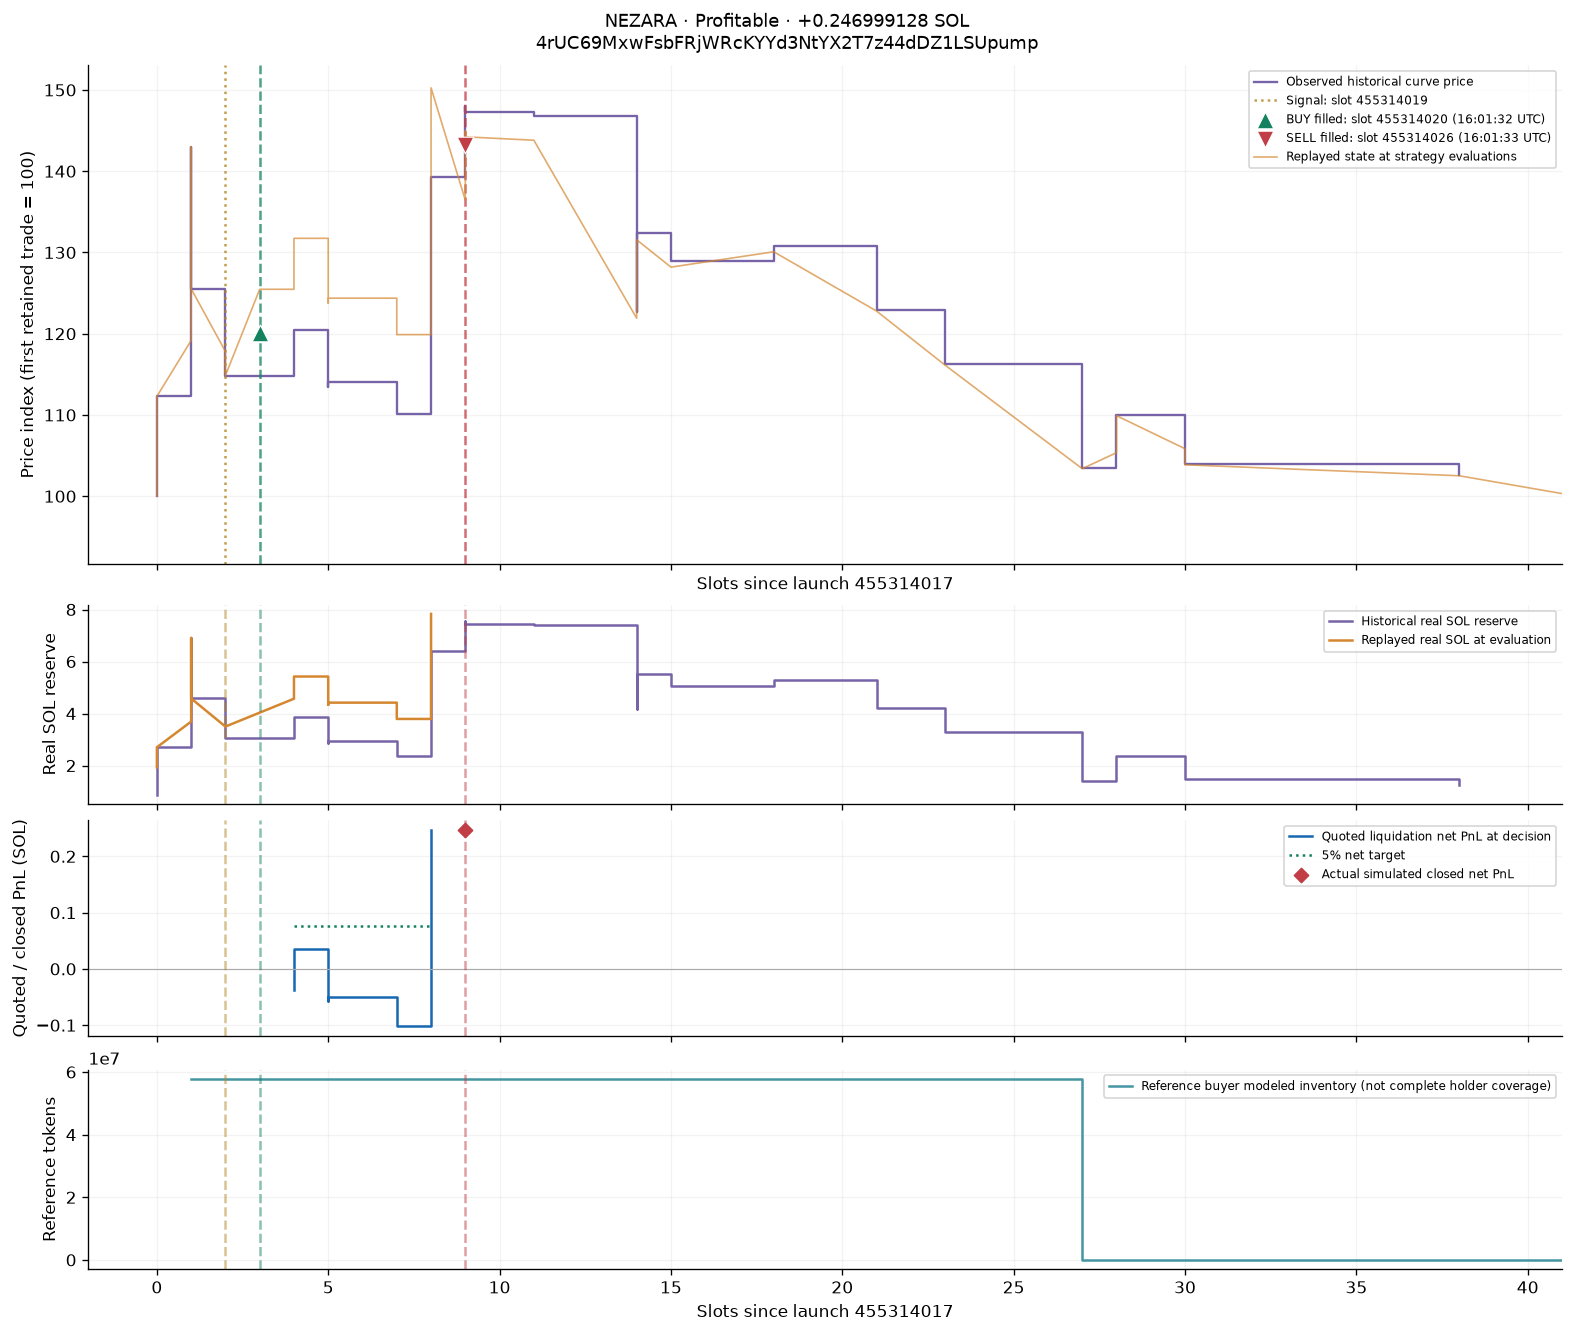

[GMGN token](https://gmgn.ai/sol/token/4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump) · [Reference buyer](https://gmgn.ai/sol/address/DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH) · [Creator](https://gmgn.ai/sol/address/GSReLD7g4WX7wrJw2hehNTULirCN1kk2NRDSGMAuvKGz)

,field,recorded_value
0,signal_slot,455314019
1,entry_slot,455314020
2,exit_signal_slot,455314025
3,exit_slot,455314026
4,reason,TARGET
5,budget_lamports,1513731400
6,entry_cash_sol,1.515875680
7,closed_pnl_sol,0.246999128
8,sniper_trading_cash_cost_sol,2.201685000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump
symbol,NEZARA
boundary_ordinal,1955558821015322639
slot,455314019
time,1791648091
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,3
virtual_sol,33500201110


**Exit decision**

,recorded_value
mint,4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump
symbol,NEZARA
boundary_ordinal,1955558846785127209
slot,455314025
time,1791648093
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,3
virtual_sol,37832595193


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558821015322639,455314019,1791648091,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,3,33500201110,960889754091751,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,,57885754160601,2201685000,2201685000,0,,,,,,,,,BUY,6bb53f76198a11da3f53ed0fff042e63f1b738d91a6fdbd7733fc568e9dbe168,[],0,,,,,
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558825310289920,455314020,1791648092,ORDER_FILLED,PENDING_BUY,SIGNAL,3,34570439150,931142351653512,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,,57885754160601,2201685000,2201685000,0,,,,,,,,,BUY,6bb53f76198a11da3f53ed0fff042e63f1b738d91a6fdbd7733fc568e9dbe168,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558833900224638,455314022,1791648092,EXIT_EVALUATION,OPEN,HOLDING,3,34380150427,936296078128512,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,4380150427,57885754160601,2201685000,2201685000,0,,,,,,,,,,,,,-53446527,75691820,False,1478982151,0
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558833900224959,455314022,1791648092,EXIT_EVALUATION,OPEN,HOLDING,3,34419656599,935221416826653,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,4419656599,57885754160601,2201685000,2201685000,0,,,,,,,,,,,,,-50160452,75691820,False,1482309822,0
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558838195191808,455314023,1791648092,EXIT_EVALUATION,OPEN,HOLDING,3,34419656599,935221416826653,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,4419656599,57885754160601,2201685000,2201685000,0,,,,,,,,,,,,,-50160452,75691820,False,1482309822,0
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558842490159104,455314024,1791648093,EXIT_EVALUATION,OPEN,HOLDING,3,34419656599,935221416826653,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,4419656599,57885754160601,2201685000,2201685000,0,,,,,,,,,,,,,-50160452,75691820,False,1482309822,0
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558842490159926,455314024,1791648093,EXIT_EVALUATION,OPEN,HOLDING,3,33793089023,952561631451799,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,3793089023,57885754160601,2201685000,2201685000,0,,,,,,,,,,,,,-101861043,75691820,False,1429954793,0
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558846785126400,455314025,1791648093,EXIT_EVALUATION,OPEN,HOLDING,3,33793089023,952561631451799,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,3793089023,57885754160601,2201685000,2201685000,0,,,,,,,,,,,,,-101861043,75691820,False,1429954793,0
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558846785126924,455314025,1791648093,EXIT_EVALUATION,OPEN,HOLDING,3,34770866800,925775023027915,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,4770866800,57885754160601,2201685000,2201685000,0,,,,,,,,,,,,,-20792025,75691820,False,1512050002,0
4rUC69MxwFsbFRjWRcKYYd3NtYX2T7z44dDZ1LSUpump,NEZARA,1955558846785127209,455314025,1791648093,EXIT_EVALUATION,OPEN,HOLDING,3,37832595193,850853605181106,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,7832595193,57885754160601,2201685000,2201685000,0,,,,,,,,,,,,,246999128,75691820,False,1783230915,0


---

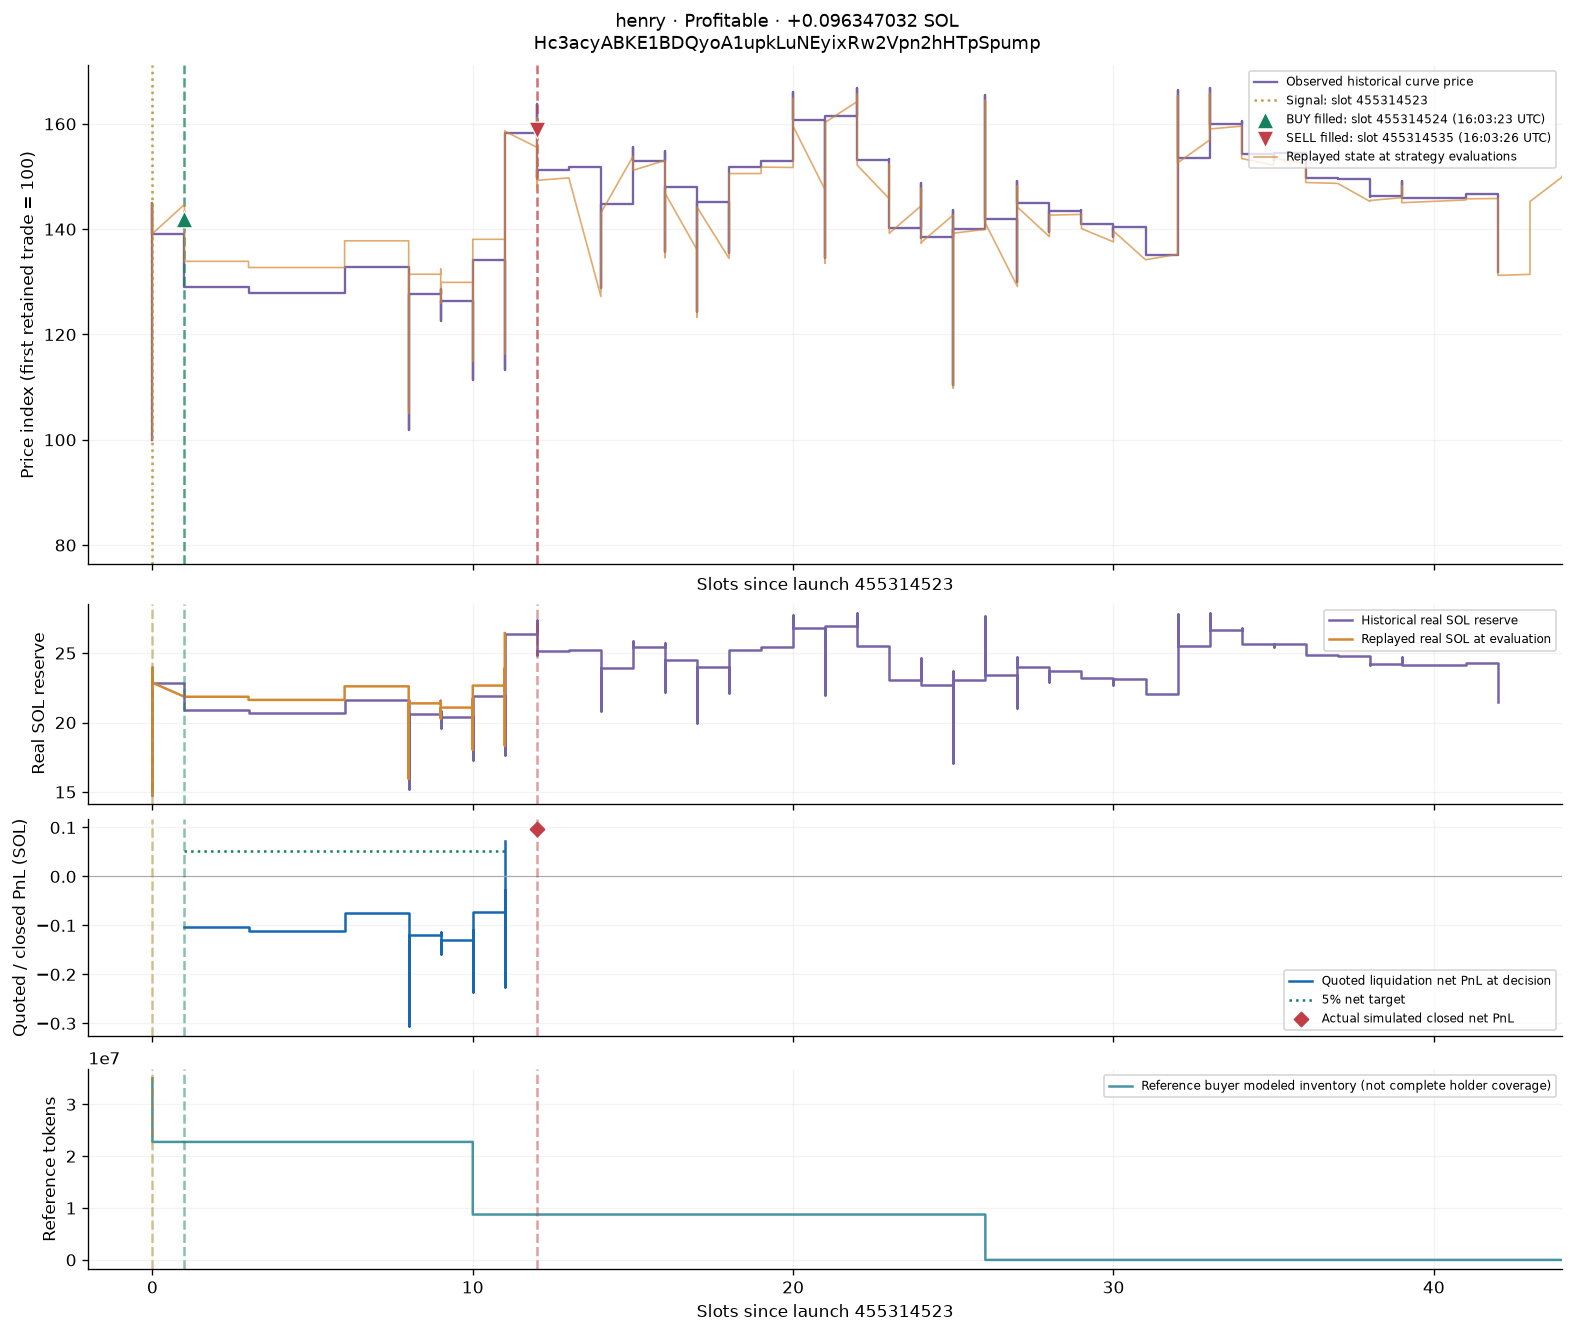

[GMGN token](https://gmgn.ai/sol/token/Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump) · [Reference buyer](https://gmgn.ai/sol/address/9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw) · [Creator](https://gmgn.ai/sol/address/HgwzjC3J1pNVwXfvgEd3Tm2Ez7FqfHkb4iiSeZNEW2gn)

,field,recorded_value
0,signal_slot,455314523
1,entry_slot,455314524
2,exit_signal_slot,455314534
3,exit_slot,455314535
4,reason,TARGET
5,budget_lamports,1054420040
6,entry_cash_sol,1.056564320
7,closed_pnl_sol,0.096347032
8,sniper_trading_cash_cost_sol,2.102423686
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump
symbol,henry
boundary_ordinal,1955560985678840864
slot,455314523
time,1791648203
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,5
virtual_sol,52865193160


**Exit decision**

...

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955560985678840864,455314523,1791648203,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,5,52865193160,608907261666062,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,22750948896935,2102423686,2102423686,0,,,,,,,,,BUY,8e1688f549865d60e844220e6dc783c373bcc2bfc82d7027f21983c24be79d86,[],0,,,,,
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955560989973807104,455314524,1791648203,ORDER_FILLED,PENDING_BUY,SIGNAL,5,53906595668,597143997060249,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,22750948896935,2102423686,2102423686,0,,,,,,,,,BUY,8e1688f549865d60e844220e6dc783c373bcc2bfc82d7027f21983c24be79d86,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955561032923481608,455314534,1791648206,EXIT_EVALUATION,OPEN,HOLDING,5,52283025465,615687400181461,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,22283025465,8750364960375,1090413380,1090413380,0,,,,,,,,,,,,,-86695256,52726252,False,980187124,0
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955561032923481647,455314534,1791648206,EXIT_EVALUATION,OPEN,HOLDING,5,52283026276,615687390639217,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,22283026276,8750364960375,1090413380,1090413380,0,,,,,,,,,,,,,-86695226,52726252,False,980187154,0
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955561032923481780,455314534,1791648206,EXIT_EVALUATION,OPEN,HOLDING,5,52640345541,611508144407606,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,22640345541,8750364960375,1090413380,1090413380,0,,,,,,,,,,,,,-73545356,52726252,False,993503479,0
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955561032923481781,455314534,1791648206,EXIT_EVALUATION,OPEN,HOLDING,5,53002582488,607328898175995,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,23002582488,8750364960375,1090413380,1090413380,0,,,,,,,,,,,,,-60125674,52726252,False,1007093030,0
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955561032923481784,455314534,1791648206,EXIT_EVALUATION,OPEN,HOLDING,5,54105887612,594944495764161,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,24105887612,8750364960375,1090413380,1090413380,0,,,,,,,,,,,,,-18701147,52726252,False,1049041918,0
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955561032923481832,455314534,1791648206,EXIT_EVALUATION,OPEN,HOLDING,5,55105887612,584148108645438,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,25105887612,8750364960375,1090413380,1090413380,0,,,,,,,,,,,,,19560437,52726252,False,1087787826,0
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955561032923481841,455314534,1791648206,EXIT_EVALUATION,OPEN,HOLDING,5,55787795756,577007920605877,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,25787795756,8750364960375,1090413380,1090413380,0,,,,,,,,,,,,,46041215,52726252,False,1114603804,0
Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,henry,1955561032923481844,455314534,1791648206,EXIT_EVALUATION,OPEN,HOLDING,5,56438175401,570358623329183,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,26438175401,8750364960375,1090413380,1090413380,0,,,,,,,,,,,,,71591958,52726252,False,1140477973,0


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,Hc3acyABKE1BDQyoA1upkLuNEyixRw2Vpn2hHTpSpump,1955563330730983430,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


---

findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


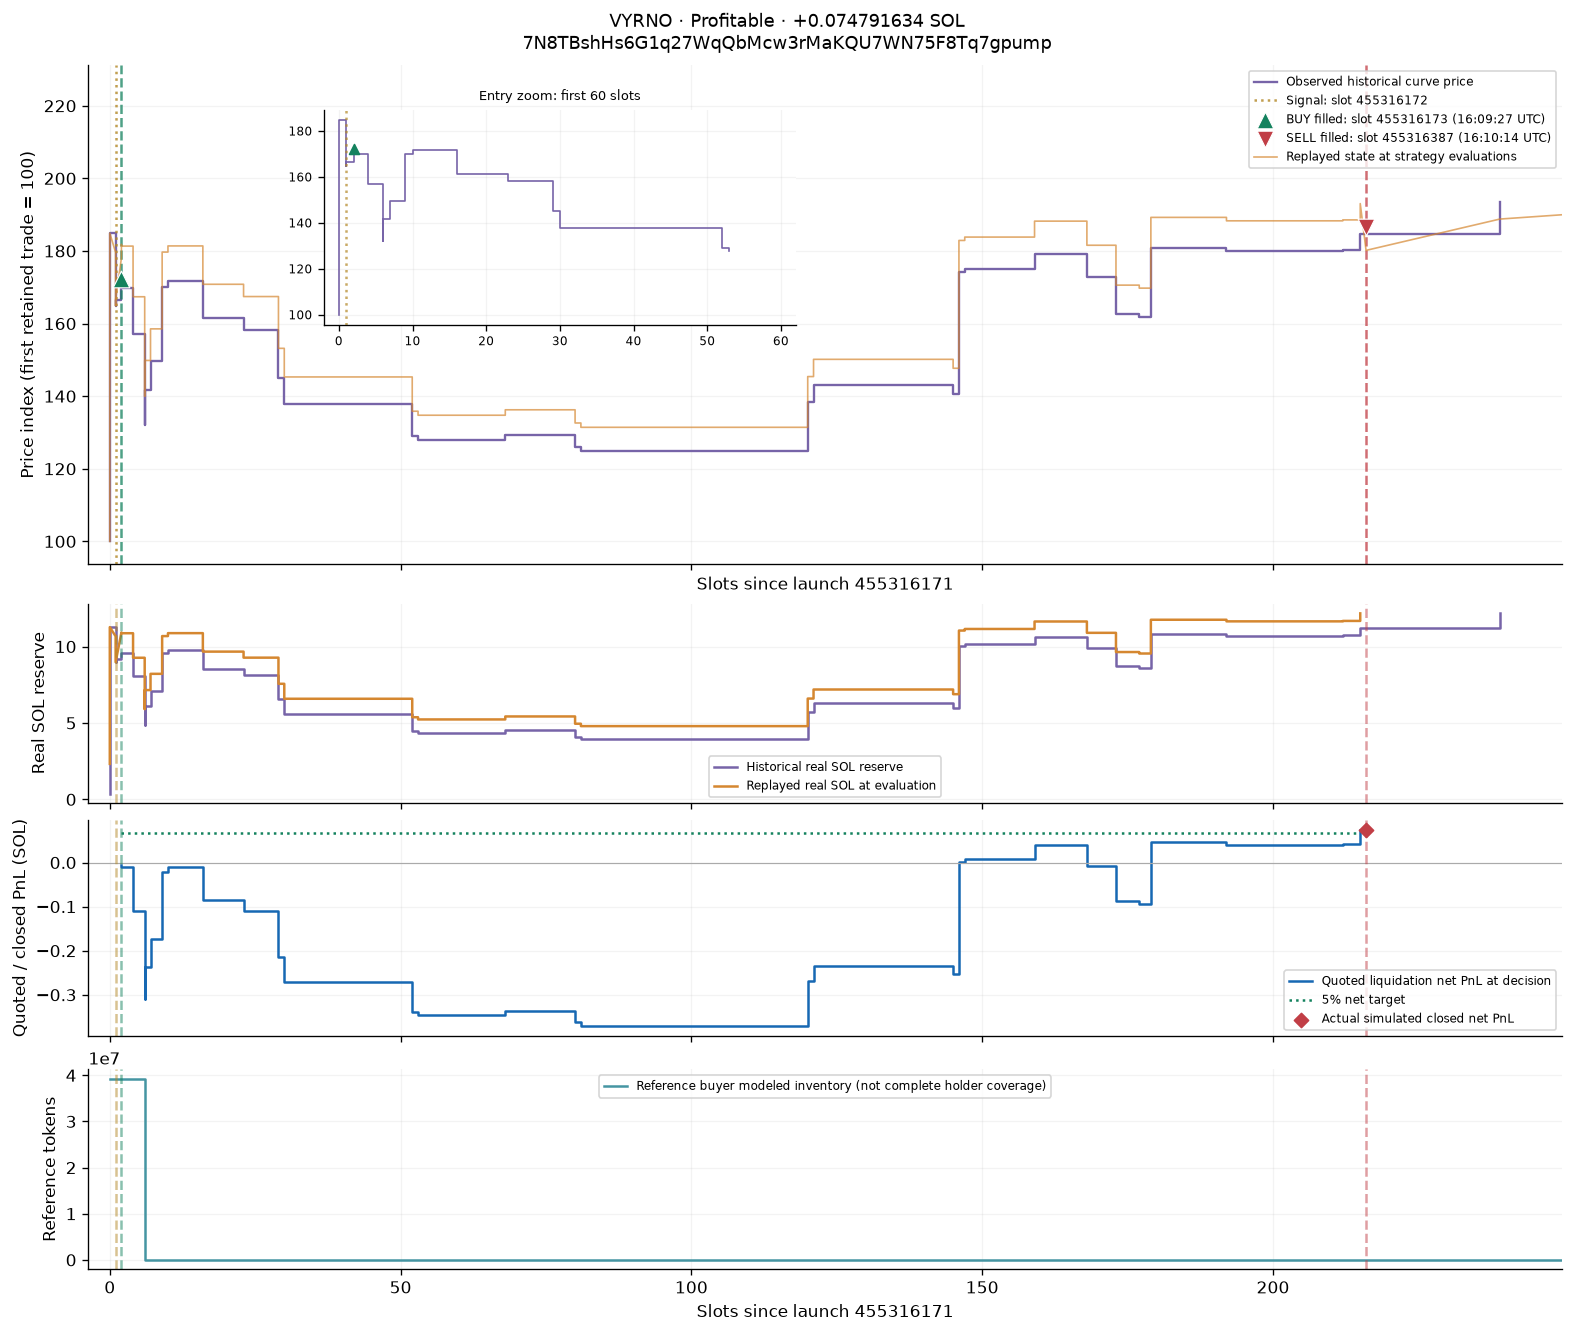

[GMGN token](https://gmgn.ai/sol/token/7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump) · [Reference buyer](https://gmgn.ai/sol/address/DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ) · [Creator](https://gmgn.ai/sol/address/4HqhYNYokbLbSDrztm3wUhyjxdFs3v1VgawG7hfLTJw4)

,field,recorded_value
0,signal_slot,455316172
1,entry_slot,455316173
2,exit_signal_slot,455316386
3,exit_slot,455316387
4,reason,TARGET
5,budget_lamports,1339562000
6,entry_cash_sol,1.341706280
7,closed_pnl_sol,0.074791634
8,sniper_trading_cash_cost_sol,2.008905000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump
symbol,VYRNO
boundary_ordinal,1955568068079911875
slot,455316172
time,1791648567
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,5
virtual_sol,38978686551


**Exit decision**

...

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568068079911875,455316172,1791648567,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,5,38978686551,825835933791095,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,,39306016675269,2008905000,2008905000,0,,,,,,,,,BUY,970d876308755b3875e1fd64ad6db436c55a4f5ee73a6b6f0f609bd2e5aafcde,[],0,,,,,
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568072374878208,455316173,1791648567,ORDER_FILLED,PENDING_BUY,SIGNAL,5,40499241611,794829698704010,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,,39306016675269,2008905000,2008905000,0,,,,,,,,,BUY,970d876308755b3875e1fd64ad6db436c55a4f5ee73a6b6f0f609bd2e5aafcde,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568965728075776,455316381,1791648612,EXIT_EVALUATION,OPEN,HOLDING,5,41647484454,772915830363768,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,11647484454,0,382780723,382780723,0,,,,,,,,,,,,,40569668,66983350,False,1397814349,0
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568970023043072,455316382,1791648613,EXIT_EVALUATION,OPEN,HOLDING,5,41647484454,772915830363768,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,11647484454,0,382780723,382780723,0,,,,,,,,,,,,,40569668,66983350,False,1397814349,0
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568974318010368,455316383,1791648613,EXIT_EVALUATION,OPEN,HOLDING,5,41647484454,772915830363768,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,11647484454,0,382780723,382780723,0,,,,,,,,,,,,,40569668,66983350,False,1397814349,0
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568974318010382,455316383,1791648613,EXIT_EVALUATION,OPEN,HOLDING,5,41675633274,772393782677702,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,11675633274,0,382780723,382780723,0,,,,,,,,,,,,,42404843,66983350,False,1399672754,0
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568978612977664,455316384,1791648613,EXIT_EVALUATION,OPEN,HOLDING,5,41675633274,772393782677702,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,11675633274,0,382780723,382780723,0,,,,,,,,,,,,,42404843,66983350,False,1399672754,0
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568982907944960,455316385,1791648613,EXIT_EVALUATION,OPEN,HOLDING,5,41675633274,772393782677702,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,11675633274,0,382780723,382780723,0,,,,,,,,,,,,,42404843,66983350,False,1399672754,0
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568987202912256,455316386,1791648614,EXIT_EVALUATION,OPEN,HOLDING,5,41675633274,772393782677702,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,11675633274,0,382780723,382780723,0,,,,,,,,,,,,,42404843,66983350,False,1399672754,0
7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,VYRNO,1955568987202912327,455316386,1791648614,EXIT_EVALUATION,OPEN,HOLDING,5,42169460433,763348634301387,DVDiUa47uEUYLaVTHfHAuBLf43gPBvok3JdyFPd7nEBZ,,12169460433,0,382780723,382780723,0,,,,,,,,,,,,,74791634,66983350,False,1432469504,0


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,7N8TBshHs6G1q27WqQbMcw3rMaKQU7WN75F8Tq7gpump,1955573140436287684,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


---

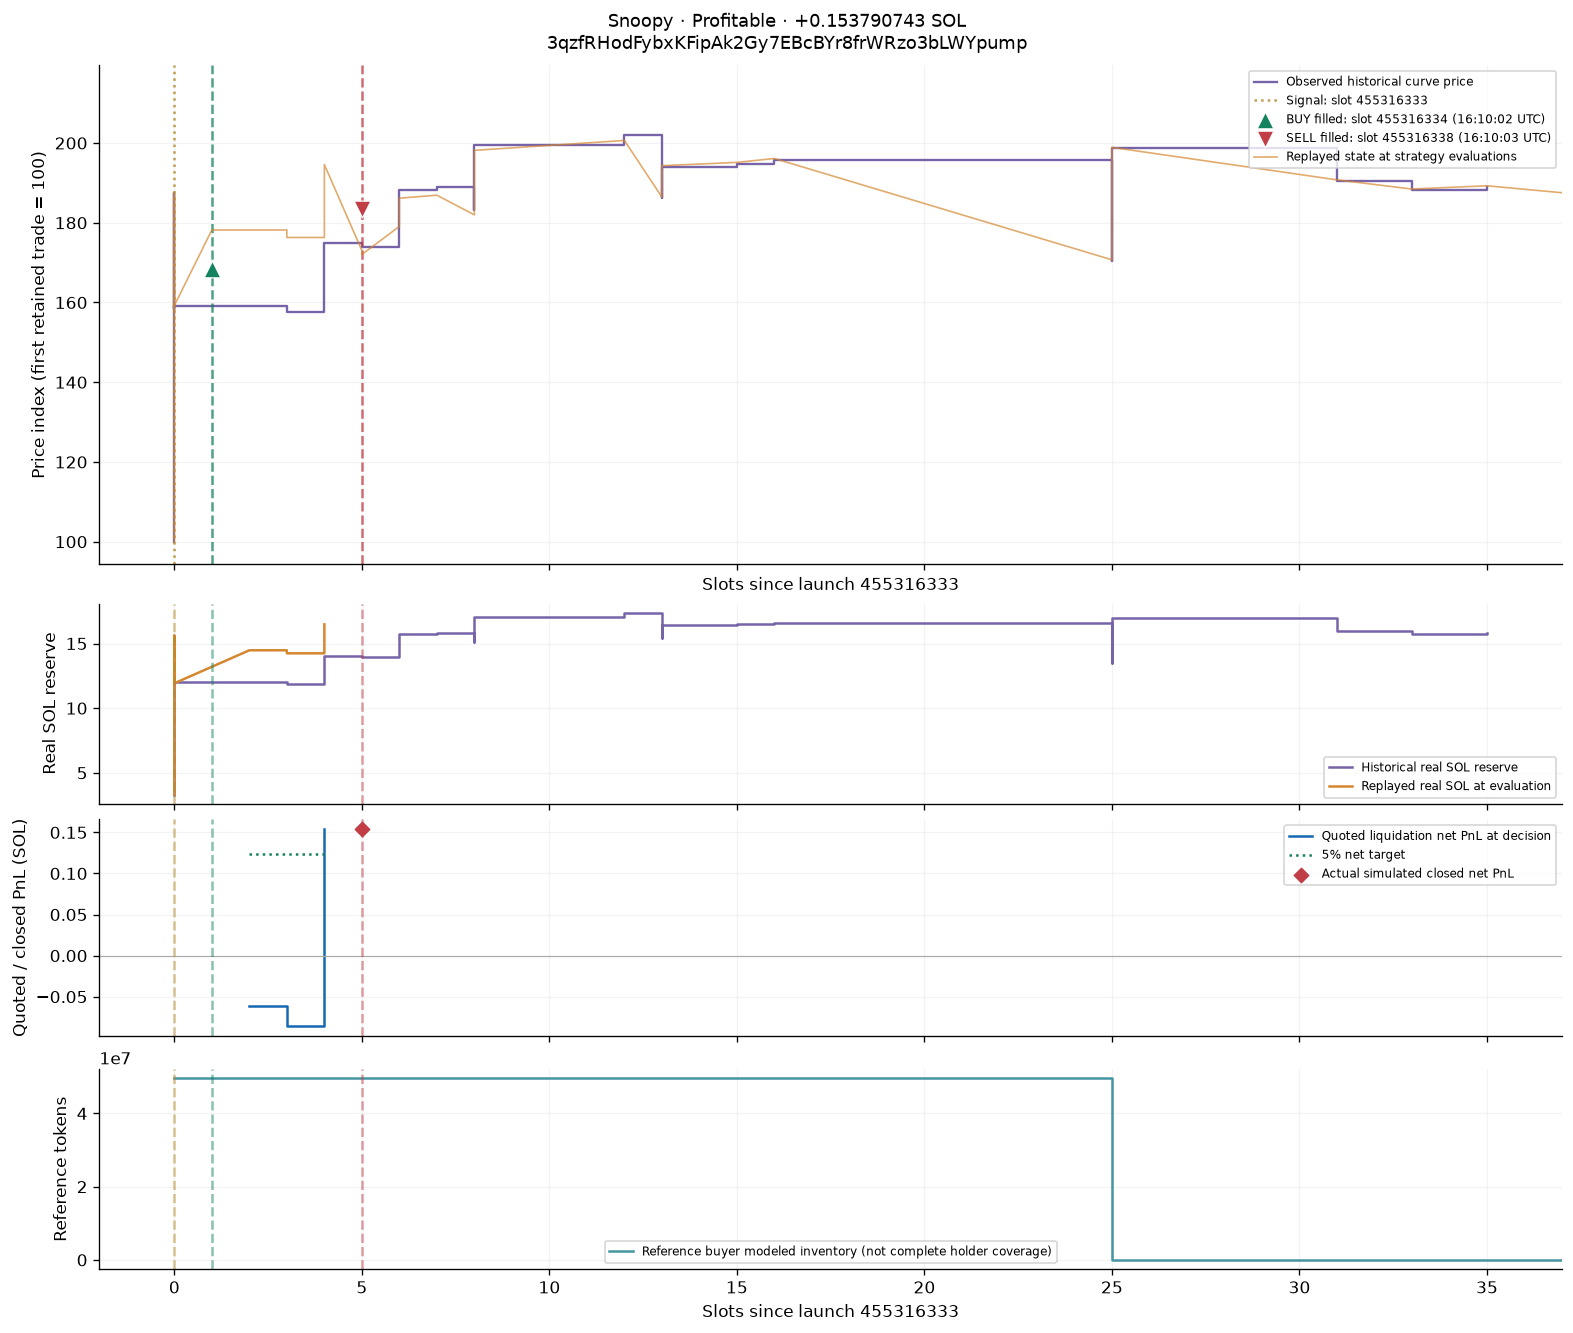

[GMGN token](https://gmgn.ai/sol/token/3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump) · [Reference buyer](https://gmgn.ai/sol/address/DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH) · [Creator](https://gmgn.ai/sol/address/5rMA6GfcwVJLhnMT2tooraHYVChev7Vzu82JG4T1VYjH)

,field,recorded_value
0,signal_slot,455316333
1,entry_slot,455316334
2,exit_signal_slot,455316337
3,exit_slot,455316338
4,reason,TARGET
5,budget_lamports,2463066576
6,entry_cash_sol,2.465210856
7,closed_pnl_sol,0.153790743
8,sniper_trading_cash_cost_sol,3.015005000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump
symbol,Snoopy
boundary_ordinal,1955568759569646334
slot,455316333
time,1791648602
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,3
virtual_sol,41927374070


**Exit decision**

...

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568759569646334,455316333,1791648602,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,3,41927374070,767756166868189,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,,49572213153812,3015005000,3015005000,0,,,,,,,,,BUY,cd0f10f6f7751553402b1196cb6b54e07354d123d87ff6727c701cec1c725242,[],0,,,,,
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568763864612864,455316334,1791648602,ORDER_FILLED,PENDING_BUY,SIGNAL,3,44478550933,723719620577953,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,,49572213153812,3015005000,3015005000,0,,,,,,,,,BUY,cd0f10f6f7751553402b1196cb6b54e07354d123d87ff6727c701cec1c725242,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568768159580160,455316335,1791648602,EXIT_EVALUATION,OPEN,HOLDING,3,44478550933,723719620577953,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,14478550933,49572213153812,3015005000,3015005000,0,,,,,,,,,,,,,-61026463,123158579,False,2432658344,0
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568772454547456,455316336,1791648603,EXIT_EVALUATION,OPEN,HOLDING,3,44478550933,723719620577953,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,14478550933,49572213153812,3015005000,3015005000,0,,,,,,,,,,,,,-61026463,123158579,False,2432658344,0
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568772454547796,455316336,1791648603,EXIT_EVALUATION,OPEN,HOLDING,3,44243776386,727559956104095,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,14243776386,49572213153812,3015005000,3015005000,0,,,,,,,,,,,,,-85633095,123158579,False,2407740235,0
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568776749514752,455316337,1791648603,EXIT_EVALUATION,OPEN,HOLDING,3,44243776386,727559956104095,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,14243776386,49572213153812,3015005000,3015005000,0,,,,,,,,,,,,,-85633095,123158579,False,2407740235,0
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568776749515500,455316337,1791648603,EXIT_EVALUATION,OPEN,HOLDING,3,44830443052,718038855173874,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,14830443052,49572213153812,3015005000,3015005000,0,,,,,,,,,,,,,-23920807,123158579,False,2470233692,0
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568776749515680,455316337,1791648603,EXIT_EVALUATION,OPEN,HOLDING,3,46481829314,692528682320874,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,16481829314,49572213153812,3015005000,3015005000,0,,,,,,,,,,,,,153790743,123158579,False,2650194755,0
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568776749515680,455316337,1791648603,ORDER_ACCEPTED,OPEN,HOLDING,3,46481829314,692528682320874,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,,49572213153812,3015005000,3015005000,0,,,,,,,,,SELL,14e635a916e9b1e60d0b589b3a4b54539d8172132e8d0846504c96a9758b5e5f,[],0,,,,,
3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,Snoopy,1955568781044482048,455316338,1791648603,ORDER_FILLED,OPEN,HOLDING,3,43831634559,734401085672300,DxhpC9c4kGkYJR34xUrfFeDx9vwb6yoHUMWrTCZybwtH,,,49572213153812,3015005000,3015005000,0,,,,,,,,,SELL,14e635a916e9b1e60d0b589b3a4b54539d8172132e8d0846504c96a9758b5e5f,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,3qzfRHodFybxKFipAk2Gy7EBcBYr8frWRzo3bLWYpump,1955569051627421933,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


---

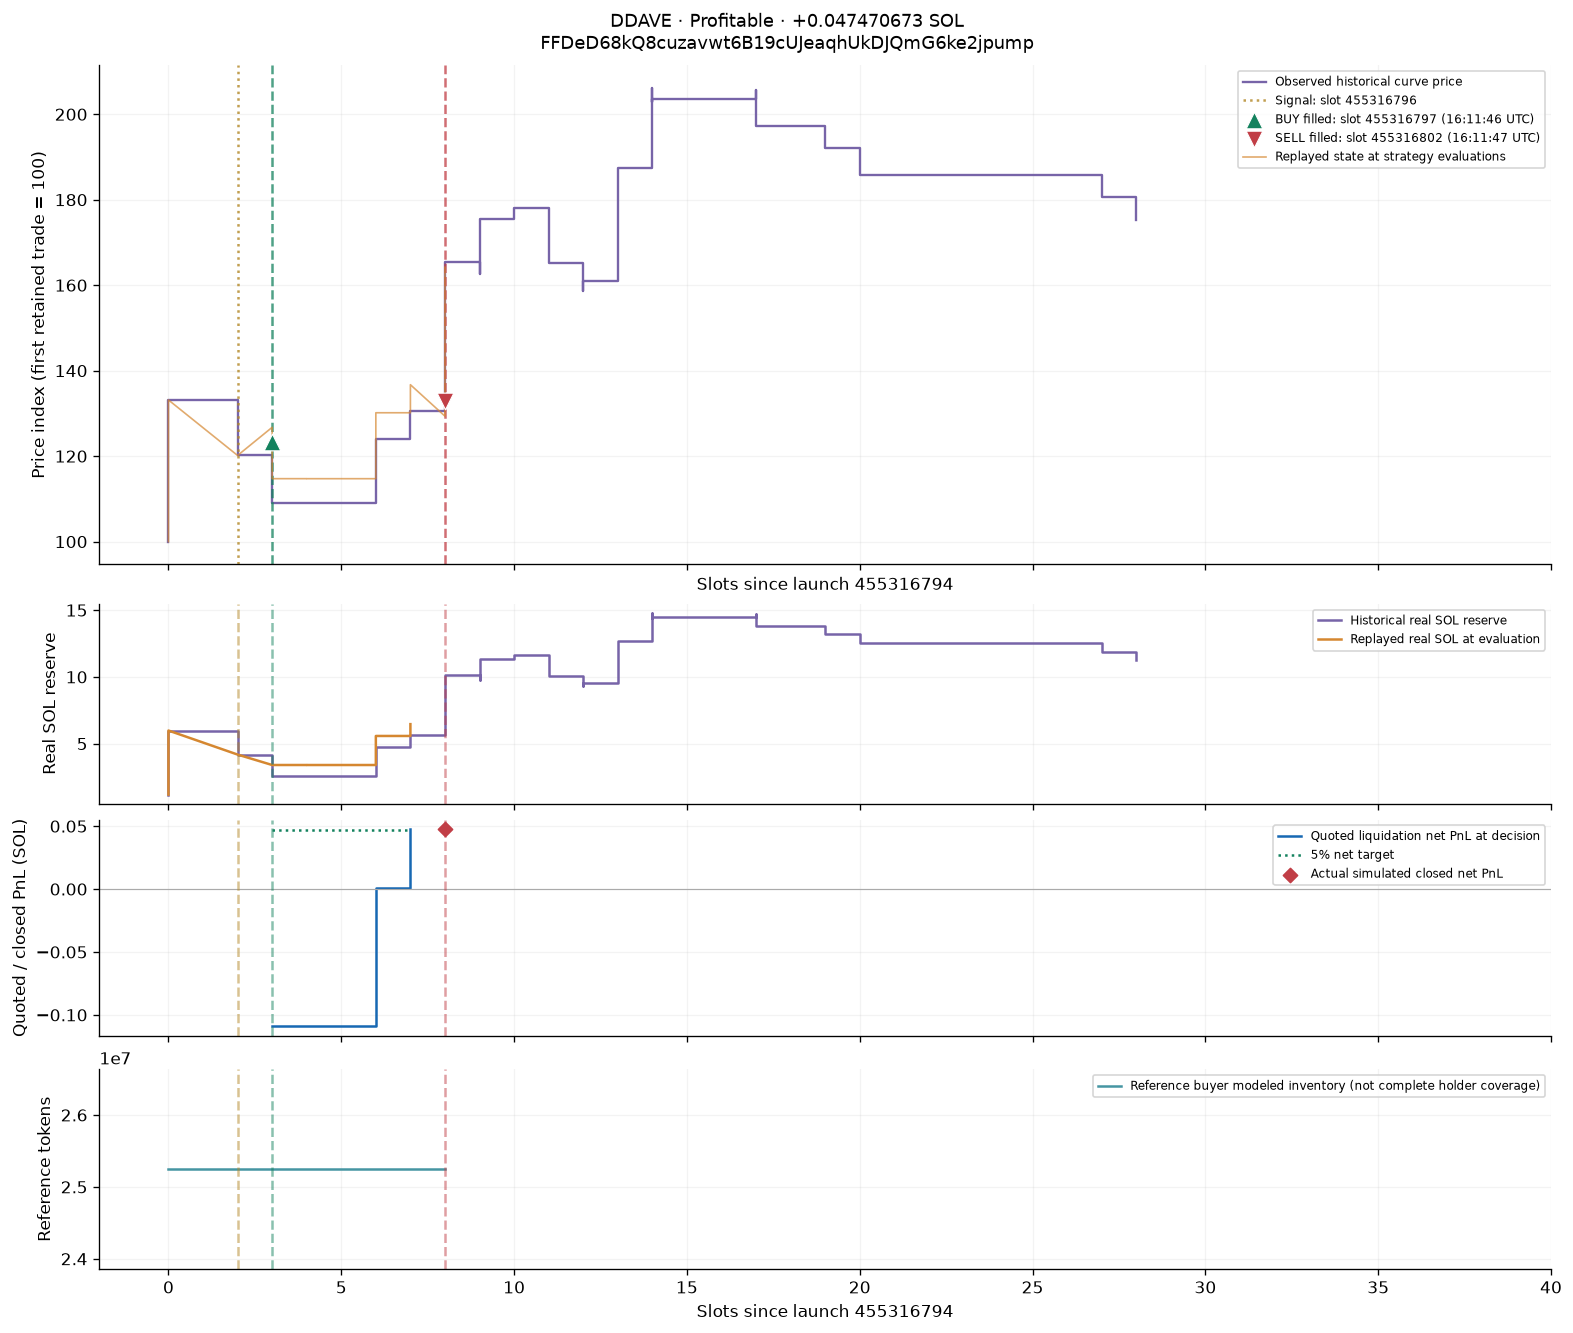

[GMGN token](https://gmgn.ai/sol/token/FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump) · [Reference buyer](https://gmgn.ai/sol/address/EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6) · [Creator](https://gmgn.ai/sol/address/4CSgwdqLKjQaq7XwQVw15kcx3qyhWzuJj8fwwCrArEf1)

,field,recorded_value
0,signal_slot,455316796
1,entry_slot,455316797
2,exit_signal_slot,455316801
3,exit_slot,455316802
4,reason,TARGET
5,budget_lamports,935666900
6,entry_cash_sol,0.937811180
7,closed_pnl_sol,0.047470673
8,sniper_trading_cash_cost_sol,1.000505000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump
symbol,DDAVE
boundary_ordinal,1955570748139504411
slot,455316796
time,1791648705
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,4
virtual_sol,34184769630


**Exit decision**

...

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570748139504411,455316796,1791648705,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,34184769630,941647416490045,4CSgwdqLKjQaq7XwQVw15kcx3qyhWzuJj8fwwCrArEf1,0,4184769630,40779097347944,1200110148,1176758065,23352083,,,,,,,,,,,,,,,,,
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570748139504411,455316796,1791648705,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,34184769630,941647416490045,EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6,935666945,4184769630,25246910414617,1000505000,1000505000,0,,,,,,,,,,,,,,,,,
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570748139504411,455316796,1791648705,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,4,34184769630,941647416490045,EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6,935666900,,25246910414617,1000505000,1000505000,0,36451758168.7647540230421831674325436879885479149205836356867,36450758155.7618532534588682417919431836454226674287159468820,1000000,35108885086,5108885086,24785490300603,924115456,23546215785572,,,,,,,,,
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570748139504411,455316796,1791648705,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,4,34184769630,941647416490045,EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6,,,25246910414617,1000505000,1000505000,0,,,,,,,,,BUY,d83ce8748c05f15ff252ae68794059baf6bc4fa74e6a6f90e8df6069ba90b5f0,[],0,,,,,
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570752434470912,455316797,1791648706,ORDER_FILLED,PENDING_BUY,SIGNAL,4,35108885086,916861926189442,EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6,,,25246910414617,1000505000,1000505000,0,,,,,,,,,BUY,d83ce8748c05f15ff252ae68794059baf6bc4fa74e6a6f90e8df6069ba90b5f0,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570765319372800,455316800,1791648706,EXIT_EVALUATION,OPEN,HOLDING,4,33402538243,963699218704947,EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6,,3402538243,25246910414617,1000505000,1000505000,0,,,,,,,,,,,,,-108803349,46788595,False,837542837,0
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570765319373269,455316800,1791648706,EXIT_EVALUATION,OPEN,HOLDING,4,34330933303,937638360261705,EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6,,4330933303,25246910414617,1000505000,1000505000,0,,,,,,,,,,,,,-62797279,46788595,False,884131262,0
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570765319373478,455316800,1791648706,EXIT_EVALUATION,OPEN,HOLDING,4,34577846882,930942869845572,EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6,,4577846882,25246910414617,1000505000,1000505000,0,,,,,,,,,,,,,-50357477,46788595,False,896728531,0
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570765319373602,455316800,1791648706,EXIT_EVALUATION,OPEN,HOLDING,4,35577846882,904776506489509,EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6,,5577846882,25246910414617,1000505000,1000505000,0,,,,,,,,,,,,,899454,46788595,False,948634283,0
FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,DDAVE,1955570769614340096,455316801,1791648707,EXIT_EVALUATION,OPEN,HOLDING,4,35577846882,904776506489509,EbbtcPMxGA74BgyEZD2kBTvaAw4a1sXZErQTG7hi9XZ6,,5577846882,25246910414617,1000505000,1000505000,0,,,,,,,,,,,,,899454,46788595,False,948634283,0


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,FFDeD68kQ8cuzavwt6B19cUJeaqhUkDJQmG6ke2jpump,1955570778204275190,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


---

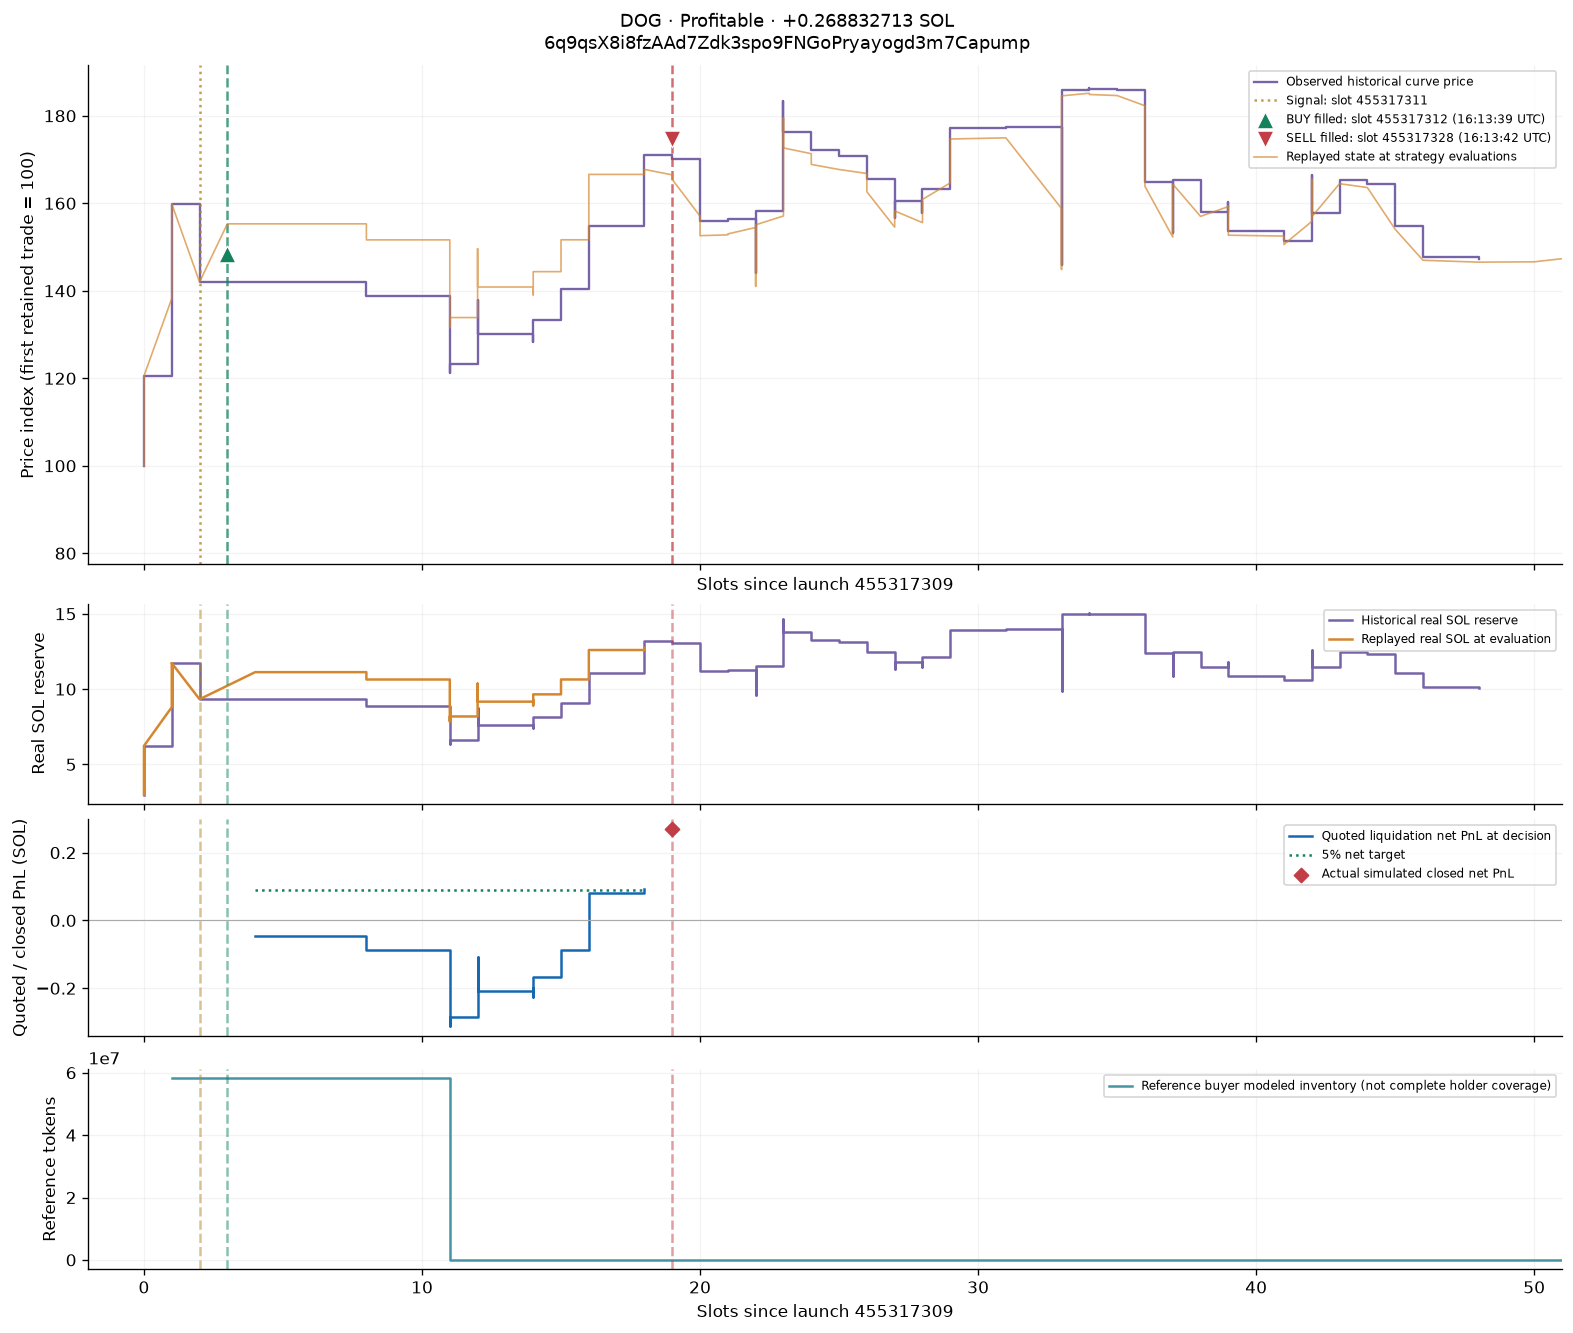

[GMGN token](https://gmgn.ai/sol/token/6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump) · [Reference buyer](https://gmgn.ai/sol/address/8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4) · [Creator](https://gmgn.ai/sol/address/7yGqBp1jJ7xqSKC43rfcmGiD2qupcWHdWV5v3jKTBi8n)

,field,recorded_value
0,signal_slot,455317311
1,entry_slot,455317312
2,exit_signal_slot,455317327
3,exit_slot,455317328
4,reason,TARGET
5,budget_lamports,1821409058
6,entry_cash_sol,1.823553338
7,closed_pnl_sol,0.268832713
8,sniper_trading_cash_cost_sol,3.022967962
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump
symbol,DOG
boundary_ordinal,1955572960047661968
slot,455317311
time,1791648819
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,5
virtual_sol,39326209623


**Exit decision**

,recorded_value
mint,6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump
symbol,DOG
boundary_ordinal,1955573028767138418
slot,455317327
time,1791648822
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,5
virtual_sol,42741196790


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955572960047661968,455317311,1791648819,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,5,39326209623,818538077069506,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,58190895017279,3022967962,3022967962,0,,,,,,,,,BUY,cf5ba6ff33db7a0de40293c6a98c337c8150ce7e3c00f9c44891e090e7a7da3c,[],0,,,,,
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955572964342628352,455317312,1791648819,ORDER_FILLED,PENDING_BUY,SIGNAL,5,41125132149,782733047213034,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,58190895017279,3022967962,3022967962,0,,,,,,,,,BUY,cf5ba6ff33db7a0de40293c6a98c337c8150ce7e3c00f9c44891e090e7a7da3c,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955573015882235904,455317324,1791648821,EXIT_EVALUATION,OPEN,HOLDING,5,39651320249,811826688452237,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,9651320249,0,276943138,276943138,0,,,,,,,,,,,,,-167633942,91075703,False,1674921637,0
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955573015882236221,455317324,1791648821,EXIT_EVALUATION,OPEN,HOLDING,5,40638974569,792096758166037,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,10638974569,0,276943138,276943138,0,,,,,,,,,,,,,-86037349,91075703,False,1757551099,0
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955573020177203200,455317325,1791648821,EXIT_EVALUATION,OPEN,HOLDING,5,40638974569,792096758166037,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,10638974569,0,276943138,276943138,0,,,,,,,,,,,,,-86037349,91075703,False,1757551099,0
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955573020177203932,455317325,1791648821,EXIT_EVALUATION,OPEN,HOLDING,5,41595402665,773883601303775,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,11595402665,0,276943138,276943138,0,,,,,,,,,,,,,-5231846,91075703,False,1839379456,0
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955573020177203936,455317325,1791648821,EXIT_EVALUATION,OPEN,HOLDING,5,42594530124,755730839596445,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,12594530124,0,276943138,276943138,0,,,,,,,,,,,,,81054907,91075703,False,1926758447,0
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955573024472170496,455317326,1791648822,EXIT_EVALUATION,OPEN,HOLDING,5,42594530124,755730839596445,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,12594530124,0,276943138,276943138,0,,,,,,,,,,,,,81054907,91075703,False,1926758447,0
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955573028767137792,455317327,1791648822,EXIT_EVALUATION,OPEN,HOLDING,5,42594530124,755730839596445,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,12594530124,0,276943138,276943138,0,,,,,,,,,,,,,81054907,91075703,False,1926758447,0
6q9qsX8i8fzAAd7Zdk3spo9FNGoPryayogd3m7Capump,DOG,1955573028767138418,455317327,1791648822,EXIT_EVALUATION,OPEN,HOLDING,5,42741196790,753137544831480,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,12741196790,0,276943138,276943138,0,,,,,,,,,,,,,93882148,91075703,False,1939748058,0


---

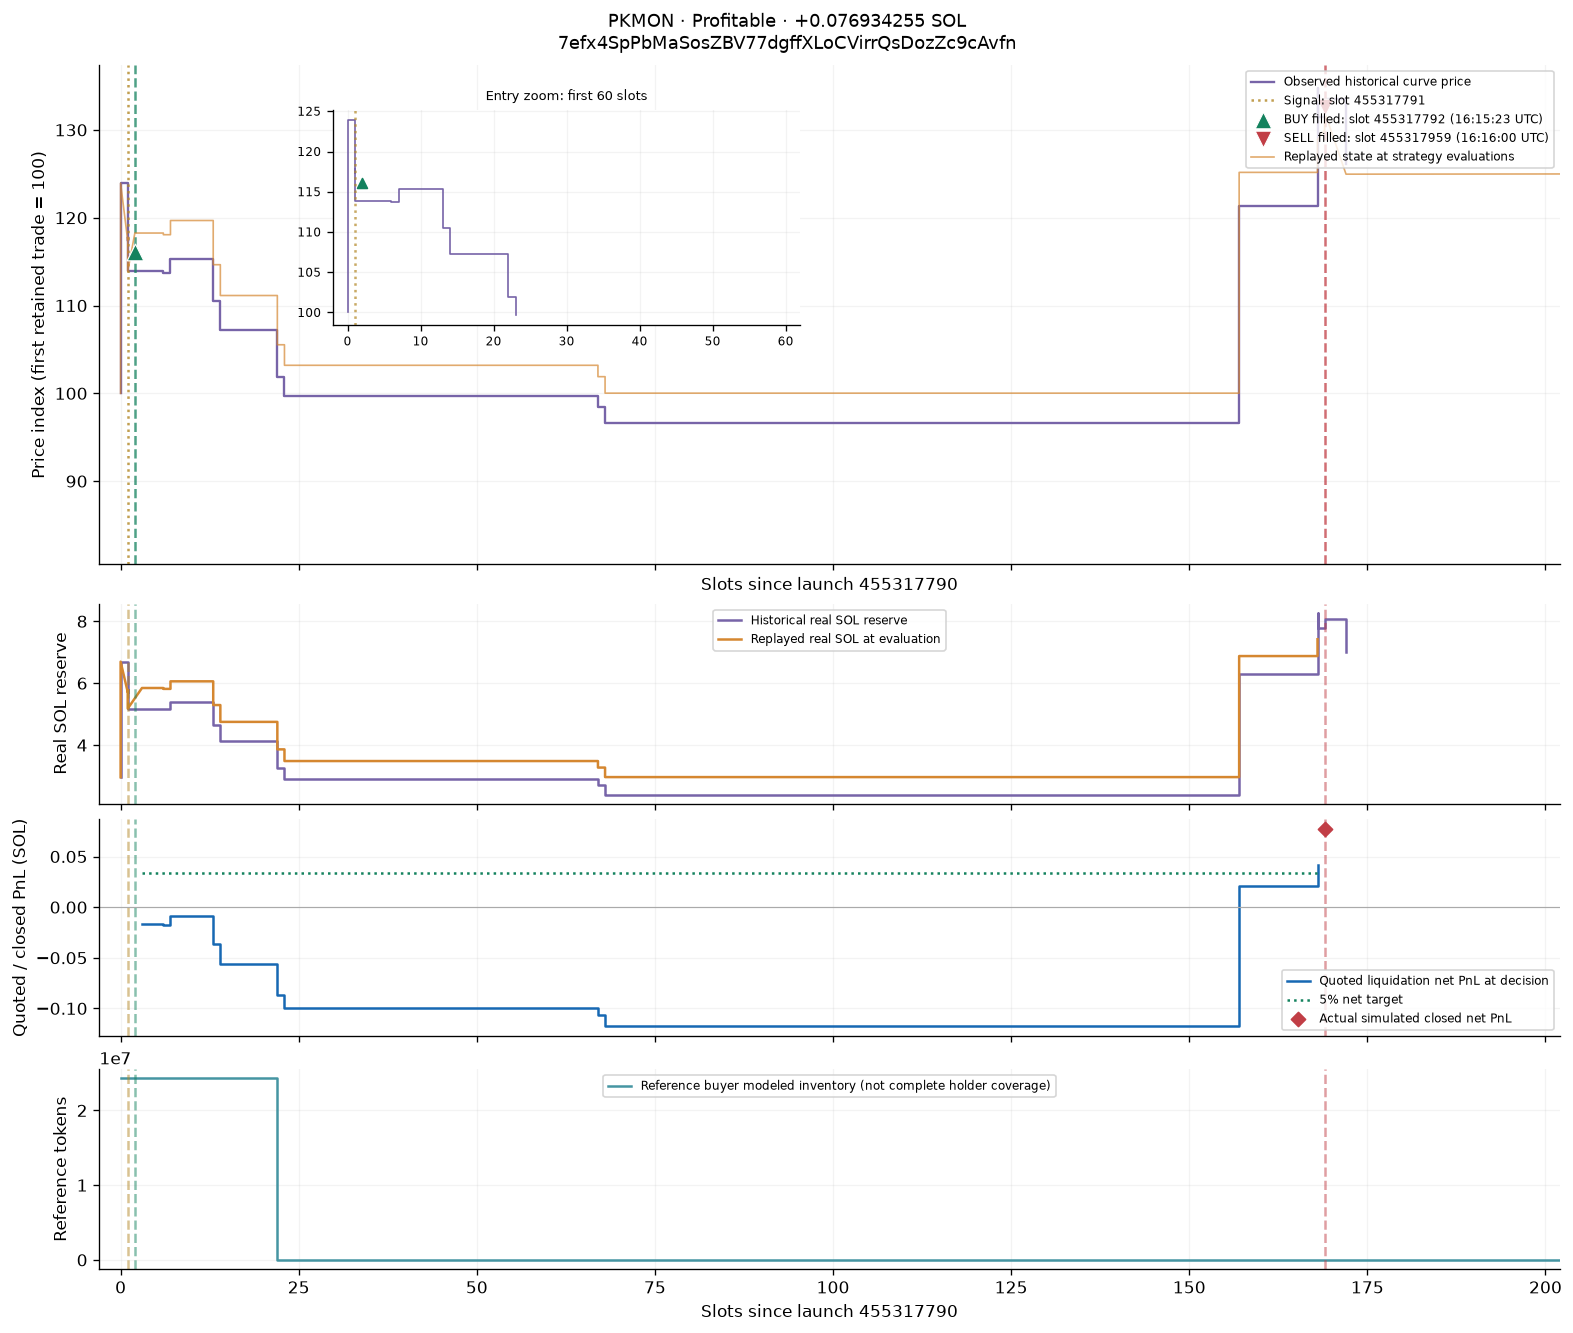

[GMGN token](https://gmgn.ai/sol/token/7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn) · [Reference buyer](https://gmgn.ai/sol/address/AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg) · [Creator](https://gmgn.ai/sol/address/DZPmSo91QadErckyuzijF2x1jAgi4nYLvuhxHJ3Tn1az)

,field,recorded_value
0,signal_slot,455317791
1,entry_slot,455317792
2,exit_signal_slot,455317958
3,exit_slot,455317959
4,reason,TARGET
5,budget_lamports,673855093
6,entry_cash_sol,0.675999373
7,closed_pnl_sol,0.076934255
8,sniper_trading_cash_cost_sol,1.003627500
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn
symbol,PKMON
boundary_ordinal,1955575021631964212
slot,455317791
time,1791648923
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,4
virtual_sol,35180023378


**Exit decision**

,recorded_value
mint,7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn
symbol,PKMON
boundary_ordinal,1955575738891502090
slot,455317958
time,1791648960
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,4
virtual_sol,37421145964


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575021631964212,455317791,1791648923,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,4,35180023378,915007919816520,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,,24288576041979,1003627500,1003627500,0,,,,,,,,,BUY,03e996ae73c914f4a51e2ca34e14c930cfb61e4095ad75996f5f1b2647e99f31,[],0,,,,,
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575025926930432,455317792,1791648923,ORDER_FILLED,PENDING_BUY,SIGNAL,4,35845559272,898019187449054,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,,24288576041979,1003627500,1003627500,0,,,,,,,,,BUY,03e996ae73c914f4a51e2ca34e14c930cfb61e4095ad75996f5f1b2647e99f31,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575713121697792,455317952,1791648959,EXIT_EVALUATION,OPEN,HOLDING,4,36877710427,872884993355988,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,6877710427,0,127006686,127006686,0,,,,,,,,,,,,,21173135,33698005,False,704038713,0
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575717416665088,455317953,1791648959,EXIT_EVALUATION,OPEN,HOLDING,4,36877710427,872884993355988,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,6877710427,0,127006686,127006686,0,,,,,,,,,,,,,21173135,33698005,False,704038713,0
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575721711632384,455317954,1791648959,EXIT_EVALUATION,OPEN,HOLDING,4,36877710427,872884993355988,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,6877710427,0,127006686,127006686,0,,,,,,,,,,,,,21173135,33698005,False,704038713,0
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575726006599680,455317955,1791648959,EXIT_EVALUATION,OPEN,HOLDING,4,36877710427,872884993355988,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,6877710427,0,127006686,127006686,0,,,,,,,,,,,,,21173135,33698005,False,704038713,0
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575730301566976,455317956,1791648960,EXIT_EVALUATION,OPEN,HOLDING,4,36877710427,872884993355988,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,6877710427,0,127006686,127006686,0,,,,,,,,,,,,,21173135,33698005,False,704038713,0
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575734596534272,455317957,1791648960,EXIT_EVALUATION,OPEN,HOLDING,4,36877710427,872884993355988,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,6877710427,0,127006686,127006686,0,,,,,,,,,,,,,21173135,33698005,False,704038713,0
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575738891501568,455317958,1791648960,EXIT_EVALUATION,OPEN,HOLDING,4,36877710427,872884993355988,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,6877710427,0,127006686,127006686,0,,,,,,,,,,,,,21173135,33698005,False,704038713,0
7efx4SpPbMaSosZBV77dgffXLoCVirrQsDozZc9cAvfn,PKMON,1955575738891502090,455317958,1791648960,EXIT_EVALUATION,OPEN,HOLDING,4,37421145964,860208825589780,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,,7421145964,0,127006686,127006686,0,,,,,,,,,,,,,41613039,33698005,False,724737350,0


---

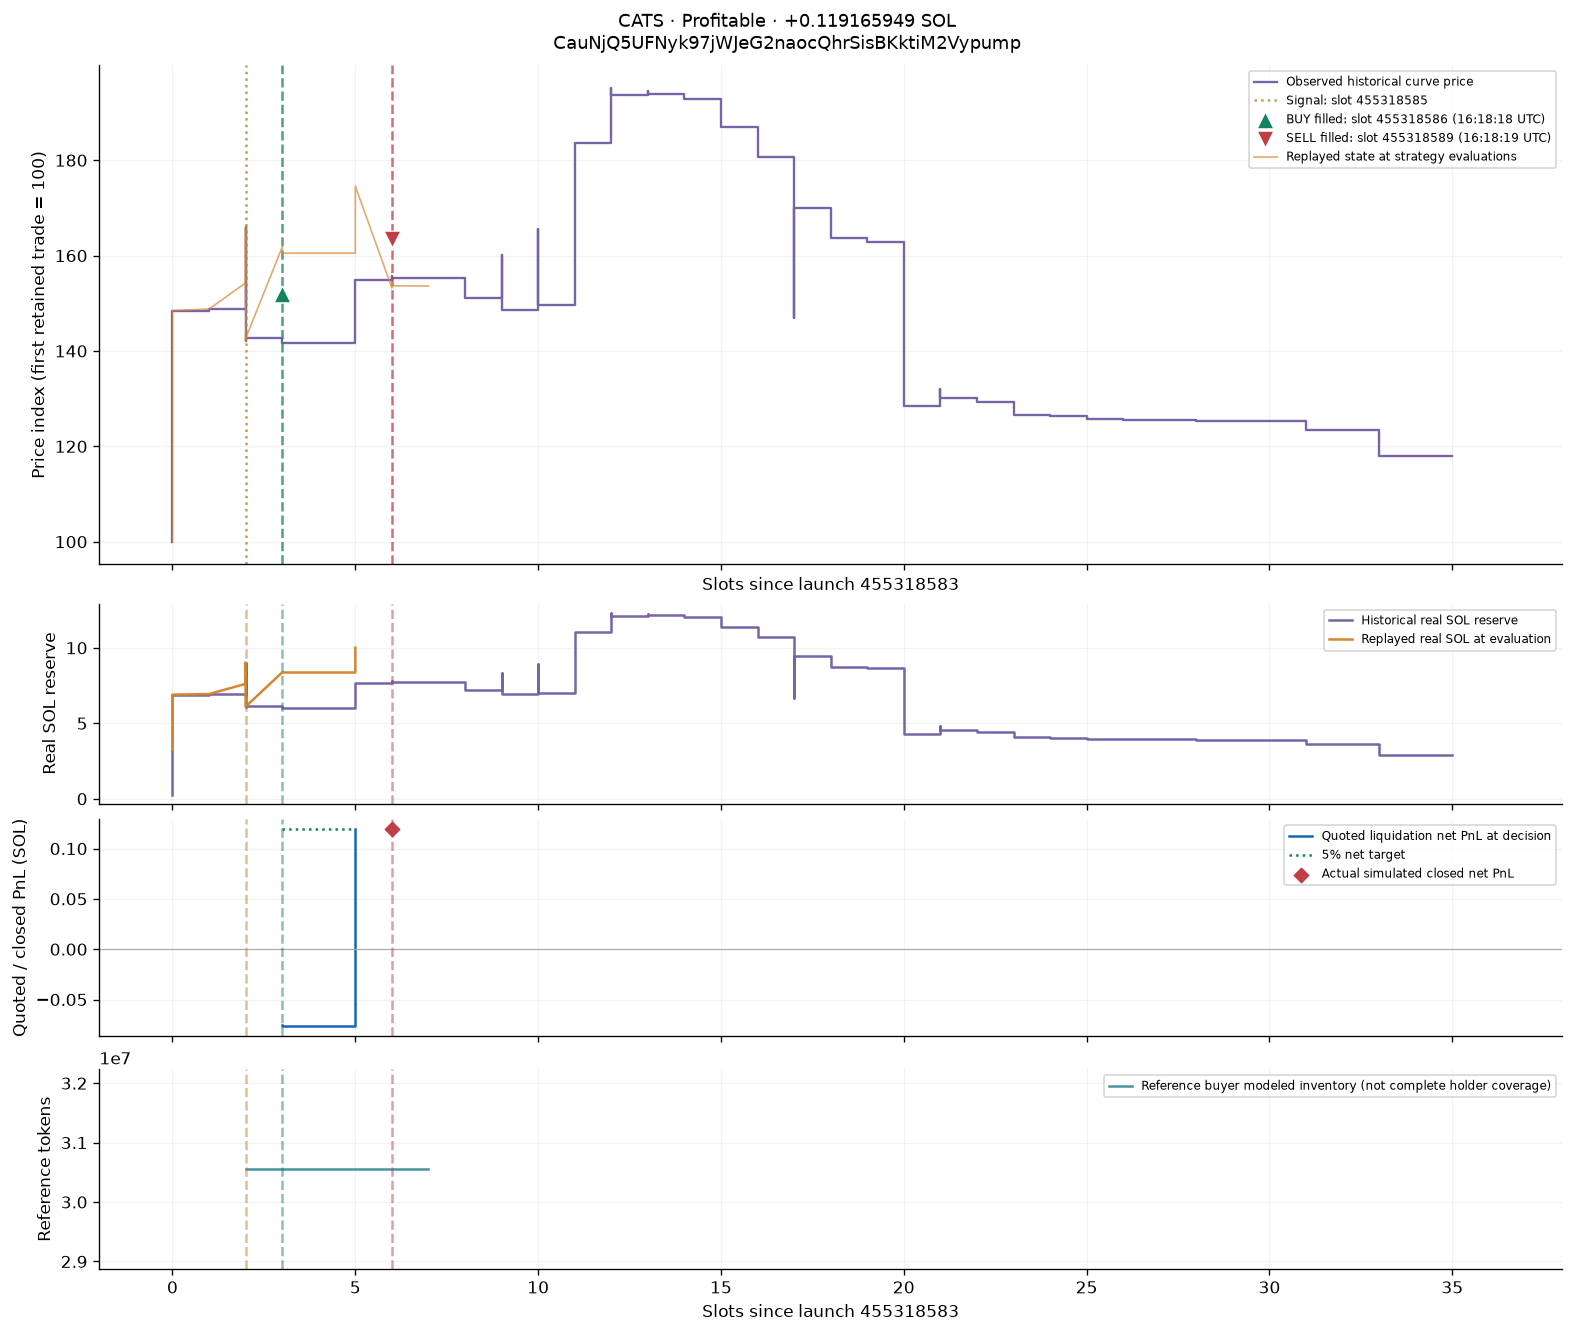

[GMGN token](https://gmgn.ai/sol/token/CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump) · [Reference buyer](https://gmgn.ai/sol/address/AzcvjR3YbA7KGzALXtW1HPjrGuKc8B3vjWhZwg6Rrgpc) · [Creator](https://gmgn.ai/sol/address/E4v2kd8nqm74DNHdotAZ5rT7Lyv9XhP94qLqyzyJYNBe)

,field,recorded_value
0,signal_slot,455318585
1,entry_slot,455318586
2,exit_signal_slot,455318588
3,exit_slot,455318589
4,reason,TARGET
5,budget_lamports,2379279053
6,entry_cash_sol,2.381423333
7,closed_pnl_sol,0.119165949
8,sniper_trading_cash_cost_sol,1.441298595
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump
symbol,CATS
boundary_ordinal,1955578431835996598
slot,455318585
time,1791649098
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,4
virtual_sol,36104965070


**Exit decision**

...

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578431835996592,455318585,1791649098,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,38130891517,844197413841975,AzcvjR3YbA7KGzALXtW1HPjrGuKc8B3vjWhZwg6Rrgpc,357940688,8130891517,30553590482463,1441298595,1441298595,0,,,,,,,,,,,,,,,,,
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578431835996592,455318585,1791649098,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,38130891517,844197413841975,,,,,,,,,,,,,,,,,,,,,,,,
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578431835996598,455318585,1791649098,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36104965070,891567127805229,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,0,6104965070,42750646099243,1703890000,1703890000,0,,,,,,,,,,,,,,,,,
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578431835996598,455318585,1791649098,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36104965070,891567127805229,DL11CHBXbMMAfB3WEc1MaXqNBbVnWjuPVCzUjEwsPLv4,0,6104965070,41307166179389,1511705000,1511705000,0,,,,,,,,,,,,,,,,,
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578431835996598,455318585,1791649098,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36104965070,891567127805229,AzcvjR3YbA7KGzALXtW1HPjrGuKc8B3vjWhZwg6Rrgpc,2379279067,6104965070,30553590482463,1441298595,1441298595,0,,,,,,,,,,,,,,,,,
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578431835996598,455318585,1791649098,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,4,36104965070,891567127805229,AzcvjR3YbA7KGzALXtW1HPjrGuKc8B3vjWhZwg6Rrgpc,2379279053,,30553590482463,1441298595,1441298595,0,39950258637.5619050717223862773183122137277251640015675759672,39949258637.2160734979835754047287828334315884122812063331481,1000000,38454870307,8454870307,54482000464531,2349905237,51757900441304,,,,,,,,,
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578431835996598,455318585,1791649098,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,4,36104965070,891567127805229,AzcvjR3YbA7KGzALXtW1HPjrGuKc8B3vjWhZwg6Rrgpc,,,30553590482463,1441298595,1441298595,0,,,,,,,,,BUY,970be8d64f90296389c05ddb690fd87481c5b074a696bf22417d89973432dc42,[],0,,,,,
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578431835996610,455318585,1791649098,ENTRY_INELIGIBLE,PENDING_BUY,SIGNAL,4,36164224329,890106192103367,AzcvjR3YbA7KGzALXtW1HPjrGuKc8B3vjWhZwg6Rrgpc,,,30553590482463,1441298595,1441298595,0,,,,,,,,,,,,,,,,,
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578436130963456,455318586,1791649098,ORDER_FILLED,PENDING_BUY,SIGNAL,4,38514129566,835797157340174,AzcvjR3YbA7KGzALXtW1HPjrGuKc8B3vjWhZwg6Rrgpc,,,30553590482463,1441298595,1441298595,0,,,,,,,,,BUY,970be8d64f90296389c05ddb690fd87481c5b074a696bf22417d89973432dc42,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,CATS,1955578436130963661,455318586,1791649098,EXIT_EVALUATION,OPEN,HOLDING,4,38372437493,838883378601028,AzcvjR3YbA7KGzALXtW1HPjrGuKc8B3vjWhZwg6Rrgpc,,8372437493,30553590482463,1441298595,1441298595,0,,,,,,,,,,,,,-75483350,118969203,False,2333170334,0


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,CauNjQ5UFNyk97jWJeG2naocQhrSisBKktiM2Vypump,1955578457605800526,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


---

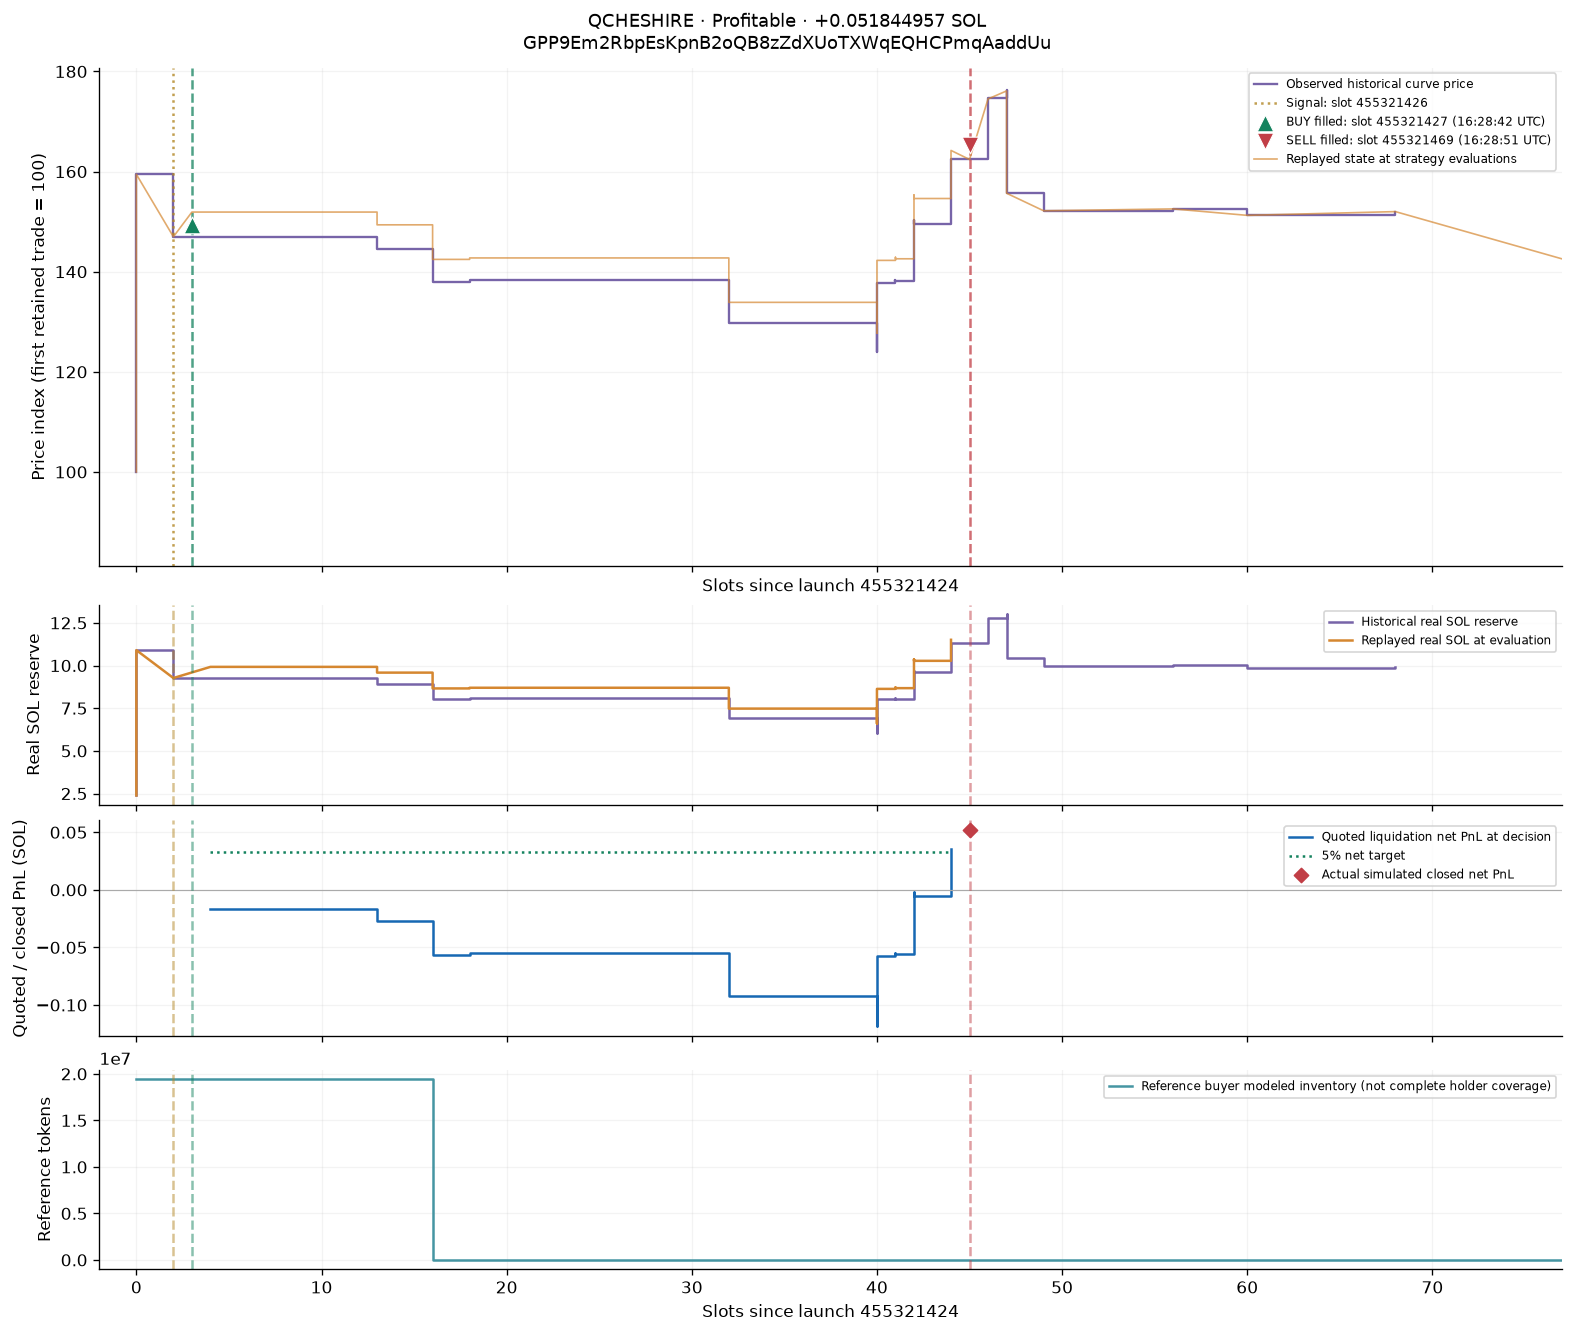

[GMGN token](https://gmgn.ai/sol/token/GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu) · [Reference buyer](https://gmgn.ai/sol/address/FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K) · [Creator](https://gmgn.ai/sol/address/EUn35ghkixANBWpQ5AkzoeG64uf8yd55e6gGsHWAFToY)

,field,recorded_value
0,signal_slot,455321426
1,entry_slot,455321427
2,exit_signal_slot,455321468
3,exit_slot,455321469
4,reason,TARGET
5,budget_lamports,661701140
6,entry_cash_sol,0.663845420
7,closed_pnl_sol,0.051844957
8,sniper_trading_cash_cost_sol,1.001000000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu
symbol,QCHESHIRE
boundary_ordinal,1955590633838084474
slot,455321426
time,1791649722
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,7
virtual_sol,39268878630


**Exit decision**

,recorded_value
mint,GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu
symbol,QCHESHIRE
boundary_ordinal,1955590814226710546
slot,455321468
time,1791649731
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,7
virtual_sol,41508642465


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590633838084474,455321426,1791649722,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,7,39268878630,819733110008115,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,,19474474828018,1001000000,1001000000,0,,,,,,,,,BUY,6cd8672aaf5b014ae9c9ee2e529049367f0be816cf6379ceea1c142df12ac2b0,[],0,,,,,
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590638133051392,455321427,1791649722,ORDER_FILLED,PENDING_BUY,SIGNAL,7,39922410620,806314035319830,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,,19474474828018,1001000000,1001000000,0,,,,,,,,,BUY,6cd8672aaf5b014ae9c9ee2e529049367f0be816cf6379ceea1c142df12ac2b0,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590801341808765,455321465,1791649730,EXIT_EVALUATION,OPEN,HOLDING,7,38716036819,831438407842156,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,8716036819,0,87714069,87714069,0,,,,,,,,,,,,,-54661715,33090307,False,614936128,0
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590801341809411,455321465,1791649730,EXIT_EVALUATION,OPEN,HOLDING,7,38676496745,832288410791152,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,8676496745,0,87714069,87714069,0,,,,,,,,,,,,,-55891599,33090307,False,613690676,0
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590805636775936,455321466,1791649730,EXIT_EVALUATION,OPEN,HOLDING,7,38676496745,832288410791152,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,8676496745,0,87714069,87714069,0,,,,,,,,,,,,,-55891599,33090307,False,613690676,0
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590805636776563,455321466,1791649730,EXIT_EVALUATION,OPEN,HOLDING,7,40366737237,797438738299801,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,10366737237,0,87714069,87714069,0,,,,,,,,,,,,,-2223093,33090307,False,668038530,0
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590805636776850,455321466,1791649730,EXIT_EVALUATION,OPEN,HOLDING,7,40276557270,799224218597305,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,10276557270,0,87714069,87714069,0,,,,,,,,,,,,,-5143026,33090307,False,665081635,0
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590809931743232,455321467,1791649731,EXIT_EVALUATION,OPEN,HOLDING,7,40276557270,799224218597305,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,10276557270,0,87714069,87714069,0,,,,,,,,,,,,,-5143026,33090307,False,665081635,0
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590814226710528,455321468,1791649731,EXIT_EVALUATION,OPEN,HOLDING,7,40276557270,799224218597305,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,10276557270,0,87714069,87714069,0,,,,,,,,,,,,,-5143026,33090307,False,665081635,0
GPP9Em2RbpEsKpnB2oQB8zZdXUoTXWqEQHCPmqAaddUu,QCHESHIRE,1955590814226710546,455321468,1791649731,EXIT_EVALUATION,OPEN,HOLDING,7,41508642465,775501151104621,FPG2nbhETtotvQxhVm4GSic9rZkdERnUYj1TffaBjg7K,,11508642465,0,87714069,87714069,0,,,,,,,,,,,,,35301278,33090307,False,706037892,0


---

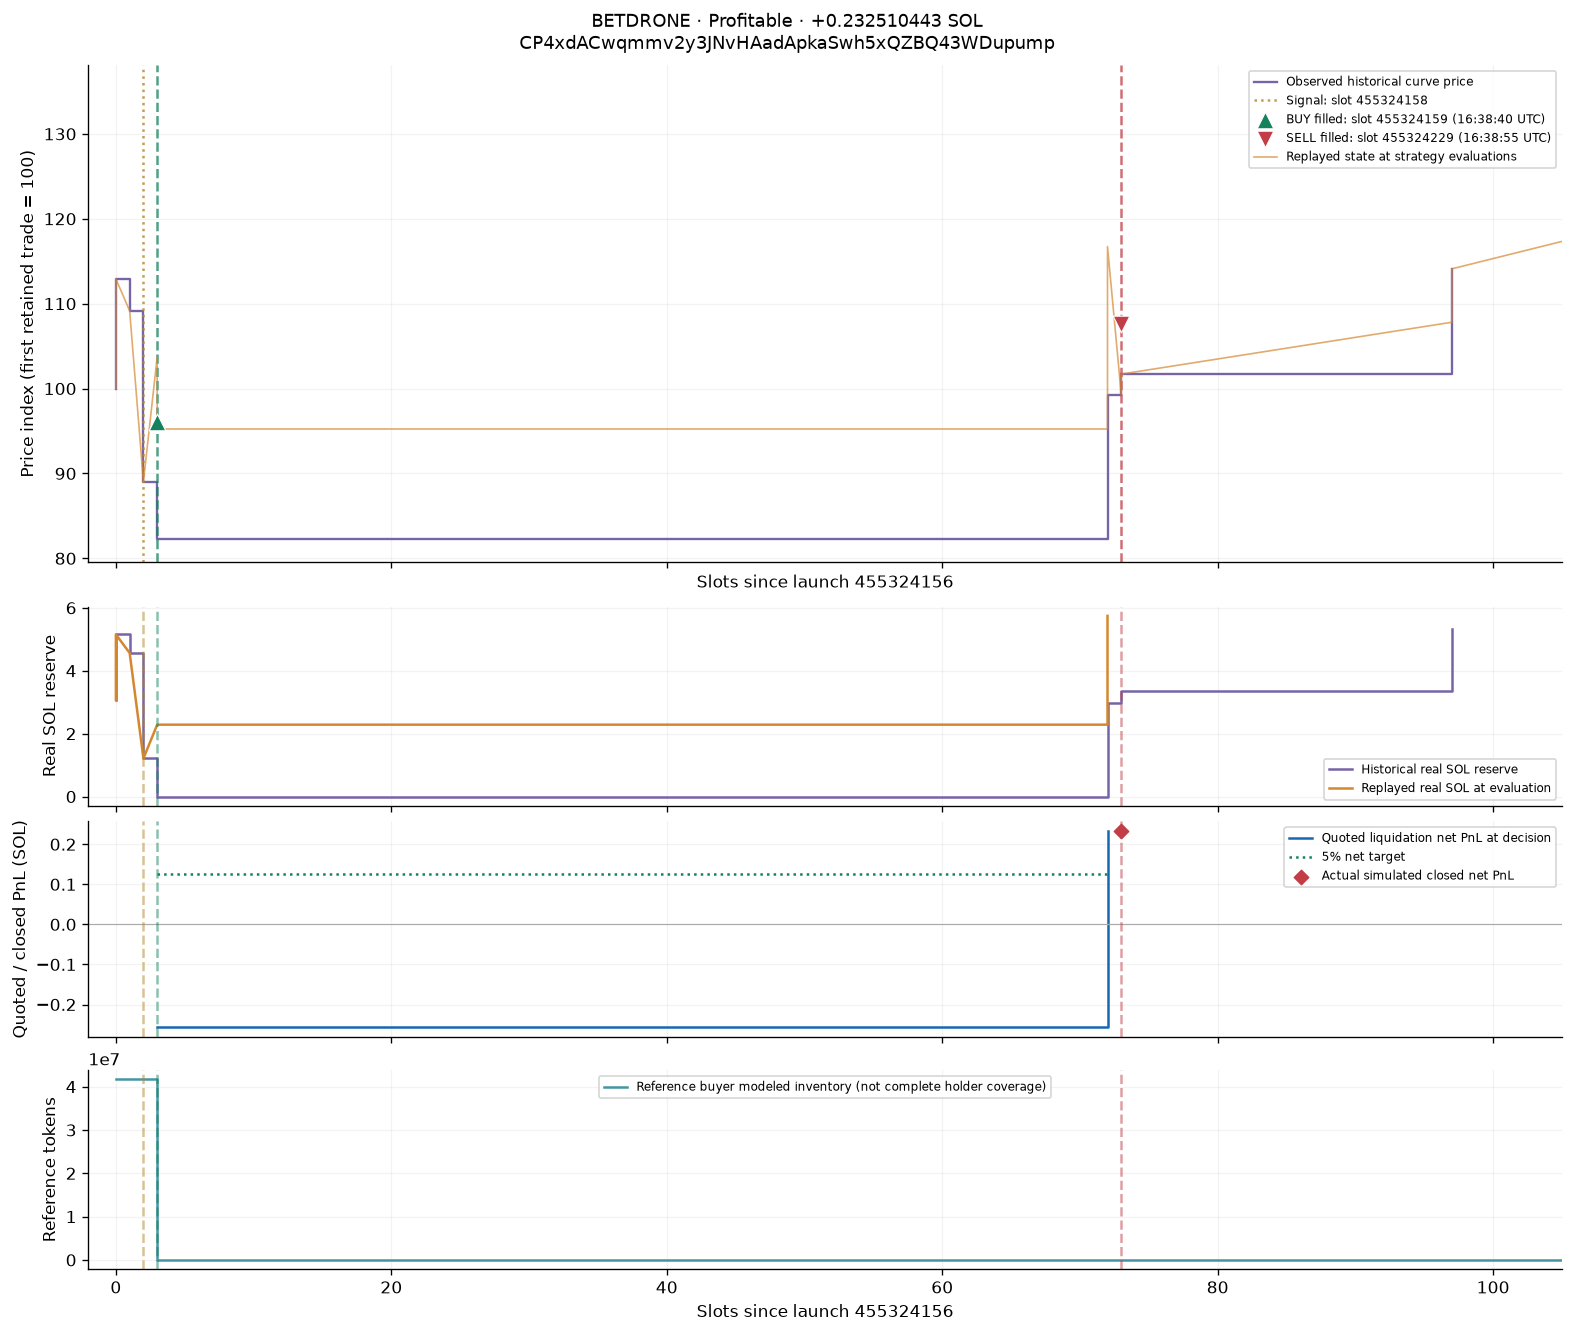

[GMGN token](https://gmgn.ai/sol/token/CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump) · [Reference buyer](https://gmgn.ai/sol/address/AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs) · [Creator](https://gmgn.ai/sol/address/Auq9cHogpAHGn6gcRkUaefBj68yCDcdjRgAqnCd6zYRM)

,field,recorded_value
0,signal_slot,455324158
1,entry_slot,455324159
2,exit_signal_slot,455324228
3,exit_slot,455324229
4,reason,TARGET
5,budget_lamports,2513266805
6,entry_cash_sol,2.515411085
7,closed_pnl_sol,0.232510443
8,sniper_trading_cash_cost_sol,1.500455000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump
symbol,BETDRONE
boundary_ordinal,1955602367688736831
slot,455324158
time,1791650320
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,2
virtual_sol,31213147920


**Exit decision**

,recorded_value
mint,CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump
symbol,BETDRONE
boundary_ordinal,1955602668336447654
slot,455324228
time,1791650335
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,2
virtual_sol,35743709548


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602367688736831,455324158,1791650320,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,2,31213147920,1031296173185607,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,,41703826814393,1500455000,1500455000,0,,,,,,,,,BUY,cb958673e06943d406023a27ae62813ae236e5e5cb730d1e028529991a549b38,[],0,,,,,
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602371983704064,455324159,1791650320,ORDER_FILLED,PENDING_BUY,SIGNAL,2,33695386739,955323654637565,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,,41703826814393,1500455000,1500455000,0,,,,,,,,,BUY,cb958673e06943d406023a27ae62813ae236e5e5cb730d1e028529991a549b38,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602651156578304,455324224,1791650334,EXIT_EVALUATION,OPEN,HOLDING,2,32285970651,997027481451958,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,2285970651,0,123661614,123661614,0,,,,,,,,,,,,,-256080793,125668591,False,2285970646,0
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602655451545600,455324225,1791650334,EXIT_EVALUATION,OPEN,HOLDING,2,32285970651,997027481451958,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,2285970651,0,123661614,123661614,0,,,,,,,,,,,,,-256080793,125668591,False,2285970646,0
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602659746512896,455324226,1791650335,EXIT_EVALUATION,OPEN,HOLDING,2,32285970651,997027481451958,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,2285970651,0,123661614,123661614,0,,,,,,,,,,,,,-256080793,125668591,False,2285970646,0
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602664041480192,455324227,1791650335,EXIT_EVALUATION,OPEN,HOLDING,2,32285970651,997027481451958,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,2285970651,0,123661614,123661614,0,,,,,,,,,,,,,-256080793,125668591,False,2285970646,0
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602668336447488,455324228,1791650335,EXIT_EVALUATION,OPEN,HOLDING,2,32285970651,997027481451958,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,2285970651,0,123661614,123661614,0,,,,,,,,,,,,,-256080793,125668591,False,2285970646,0
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602668336447633,455324228,1791650335,EXIT_EVALUATION,OPEN,HOLDING,2,33432752995,962828278301128,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,3432752995,0,123661614,123661614,0,,,,,,,,,,,,,-98941870,125668591,False,2445098670,0
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602668336447641,455324228,1791650335,EXIT_EVALUATION,OPEN,HOLDING,2,34585318011,930741767234655,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,4585318011,0,123661614,123661614,0,,,,,,,,,,,,,63907442,125668591,False,2610009365,0
CP4xdACwqmmv2y3JNvHAadApkaSwh5xQZBQ43WDupump,BETDRONE,1955602668336447654,455324228,1791650335,EXIT_EVALUATION,OPEN,HOLDING,2,35743709548,900578043346270,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,5743709548,0,123661614,123661614,0,,,,,,,,,,,,,232510443,125668591,False,2780746581,0


---

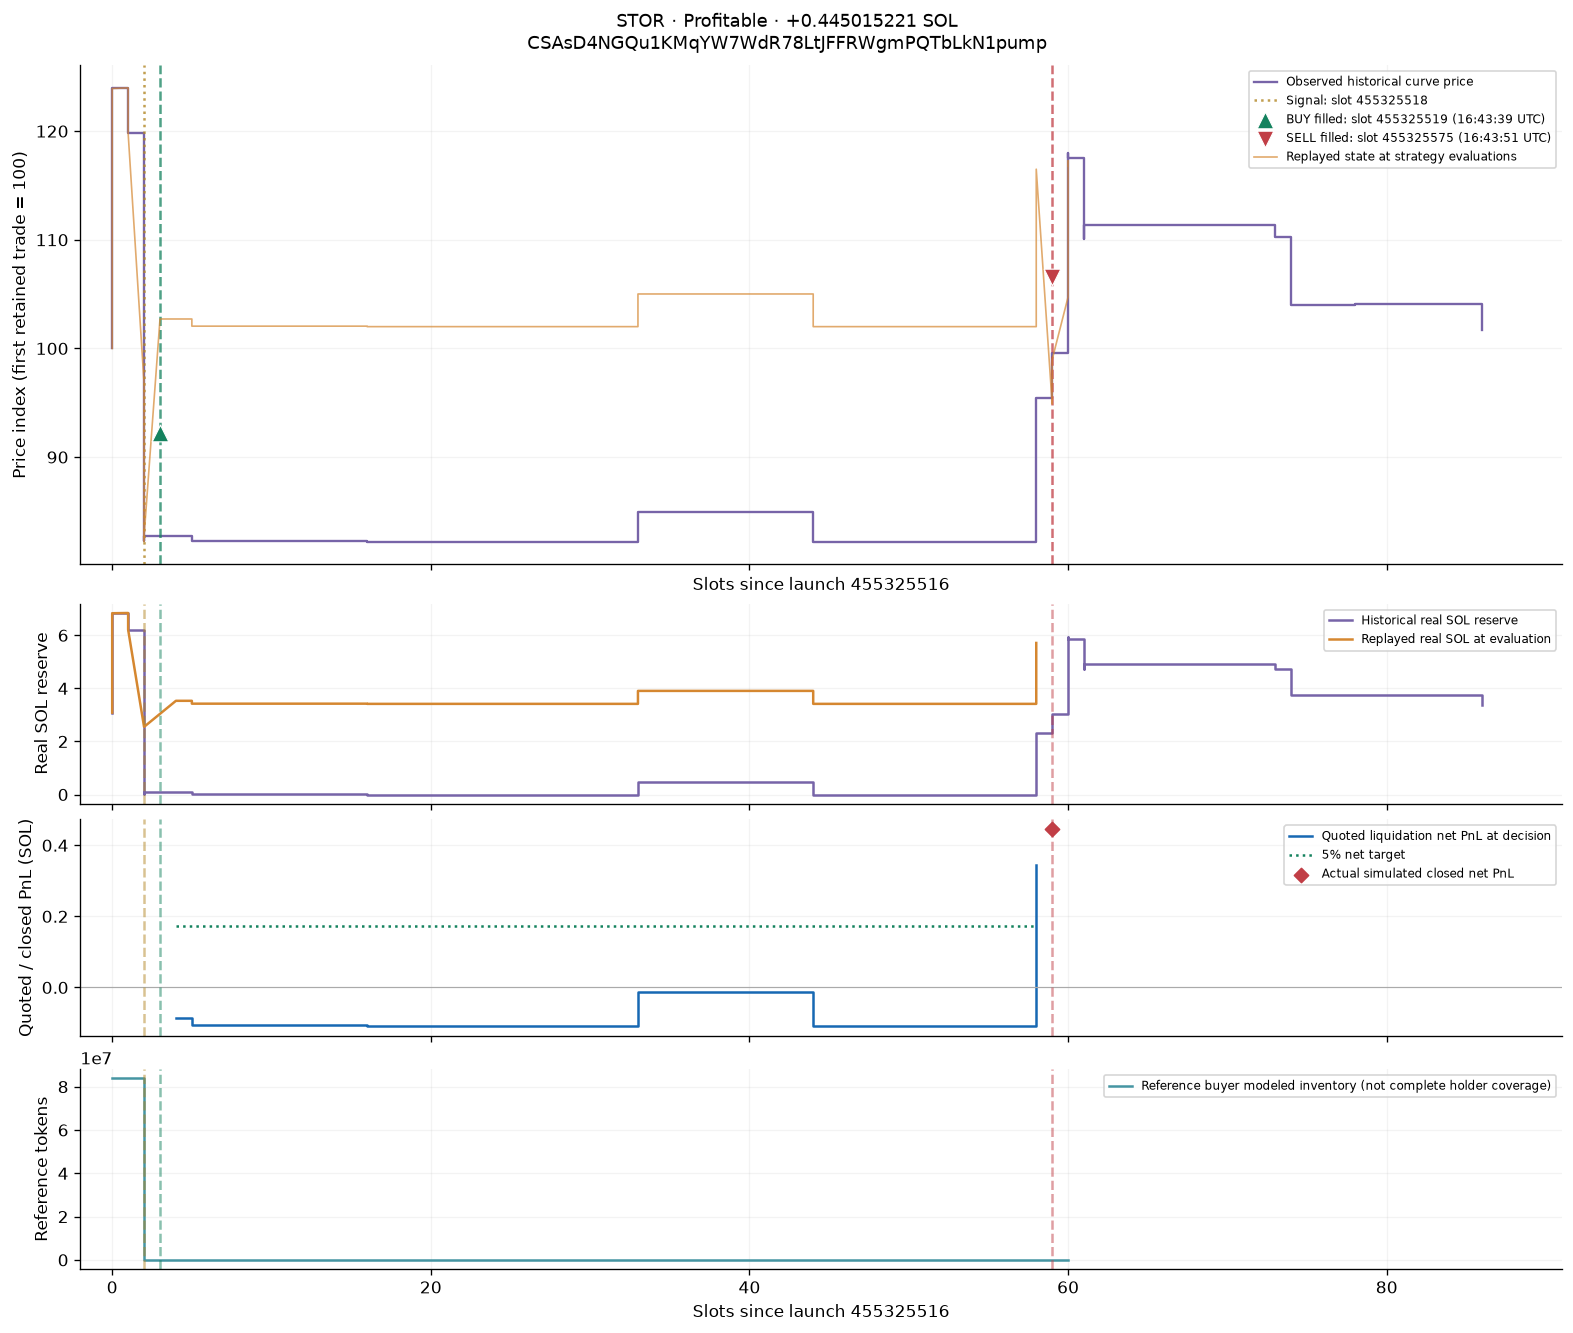

[GMGN token](https://gmgn.ai/sol/token/CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump) · [Reference buyer](https://gmgn.ai/sol/address/8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879) · [Creator](https://gmgn.ai/sol/address/2Y7upLF3UKc2EBQiHNdhoA37rZRcazDgLafw2JUDnxEX)

,field,recorded_value
0,signal_slot,455325518
1,entry_slot,455325519
2,exit_signal_slot,455325574
3,exit_slot,455325575
4,reason,TARGET
5,budget_lamports,3482638113
6,entry_cash_sol,3.484782393
7,closed_pnl_sol,0.445015221
8,sniper_trading_cash_cost_sol,3.281591300
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump
symbol,STOR
boundary_ordinal,1955608208844259757
slot,455325518
time,1791650618
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,2
virtual_sol,32550408216


**Exit decision**

...

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608208844259757,455325518,1791650618,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,2,32550408216,988927689954748,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,,83861452802849,3281591300,3281591300,0,,,,,,,,,BUY,0c200eefdcef072d66240df14ddc8ebcd8275d5e41df14caab926062f2da714c,[],0,,,,,
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608208844259938,455325518,1791650618,ENTRY_INELIGIBLE,PENDING_BUY,SIGNAL,2,30005896519,1072789142757597,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,,0,769067293,769067293,0,,,,,,,,,,,,,,,,,
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608208844260114,455325518,1791650618,ENTRY_INELIGIBLE,PENDING_BUY,SIGNAL,2,30092738840,1069693263099507,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,,0,769067293,769067293,0,,,,,,,,,,,,,,,,,
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608213139226624,455325519,1791650619,ORDER_FILLED,PENDING_BUY,SIGNAL,2,33532381420,959967608716317,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,,0,769067293,769067293,0,,,,,,,,,BUY,0c200eefdcef072d66240df14ddc8ebcd8275d5e41df14caab926062f2da714c,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608427887591424,455325569,1791650630,EXIT_EVALUATION,OPEN,HOLDING,2,33417271159,963274345616810,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,3417271159,0,769067293,769067293,0,,,,,,,,,,,,,-108292852,174137156,False,3417271151,0
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608432182558720,455325570,1791650630,EXIT_EVALUATION,OPEN,HOLDING,2,33417271159,963274345616810,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,3417271159,0,769067293,769067293,0,,,,,,,,,,,,,-108292852,174137156,False,3417271151,0
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608436477526016,455325571,1791650630,EXIT_EVALUATION,OPEN,HOLDING,2,33417271159,963274345616810,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,3417271159,0,769067293,769067293,0,,,,,,,,,,,,,-108292852,174137156,False,3417271151,0
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608440772493312,455325572,1791650630,EXIT_EVALUATION,OPEN,HOLDING,2,33417271159,963274345616810,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,3417271159,0,769067293,769067293,0,,,,,,,,,,,,,-108292852,174137156,False,3417271151,0
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608445067460608,455325573,1791650631,EXIT_EVALUATION,OPEN,HOLDING,2,33417271159,963274345616810,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,3417271159,0,769067293,769067293,0,,,,,,,,,,,,,-108292852,174137156,False,3417271151,0
CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,STOR,1955608449362427904,455325574,1791650631,EXIT_EVALUATION,OPEN,HOLDING,2,33417271159,963274345616810,8gHCvPKDJaNoA5wG2a1ryzAyurPDEEB5yPzBhThyy879,,3417271159,0,769067293,769067293,0,,,,,,,,,,,,,-108292852,174137156,False,3417271151,0


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,CSAsD4NGQu1KMqYW7WdR78LtJFFRWgmPQTbLkN1pump,1955608462247329885,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


---

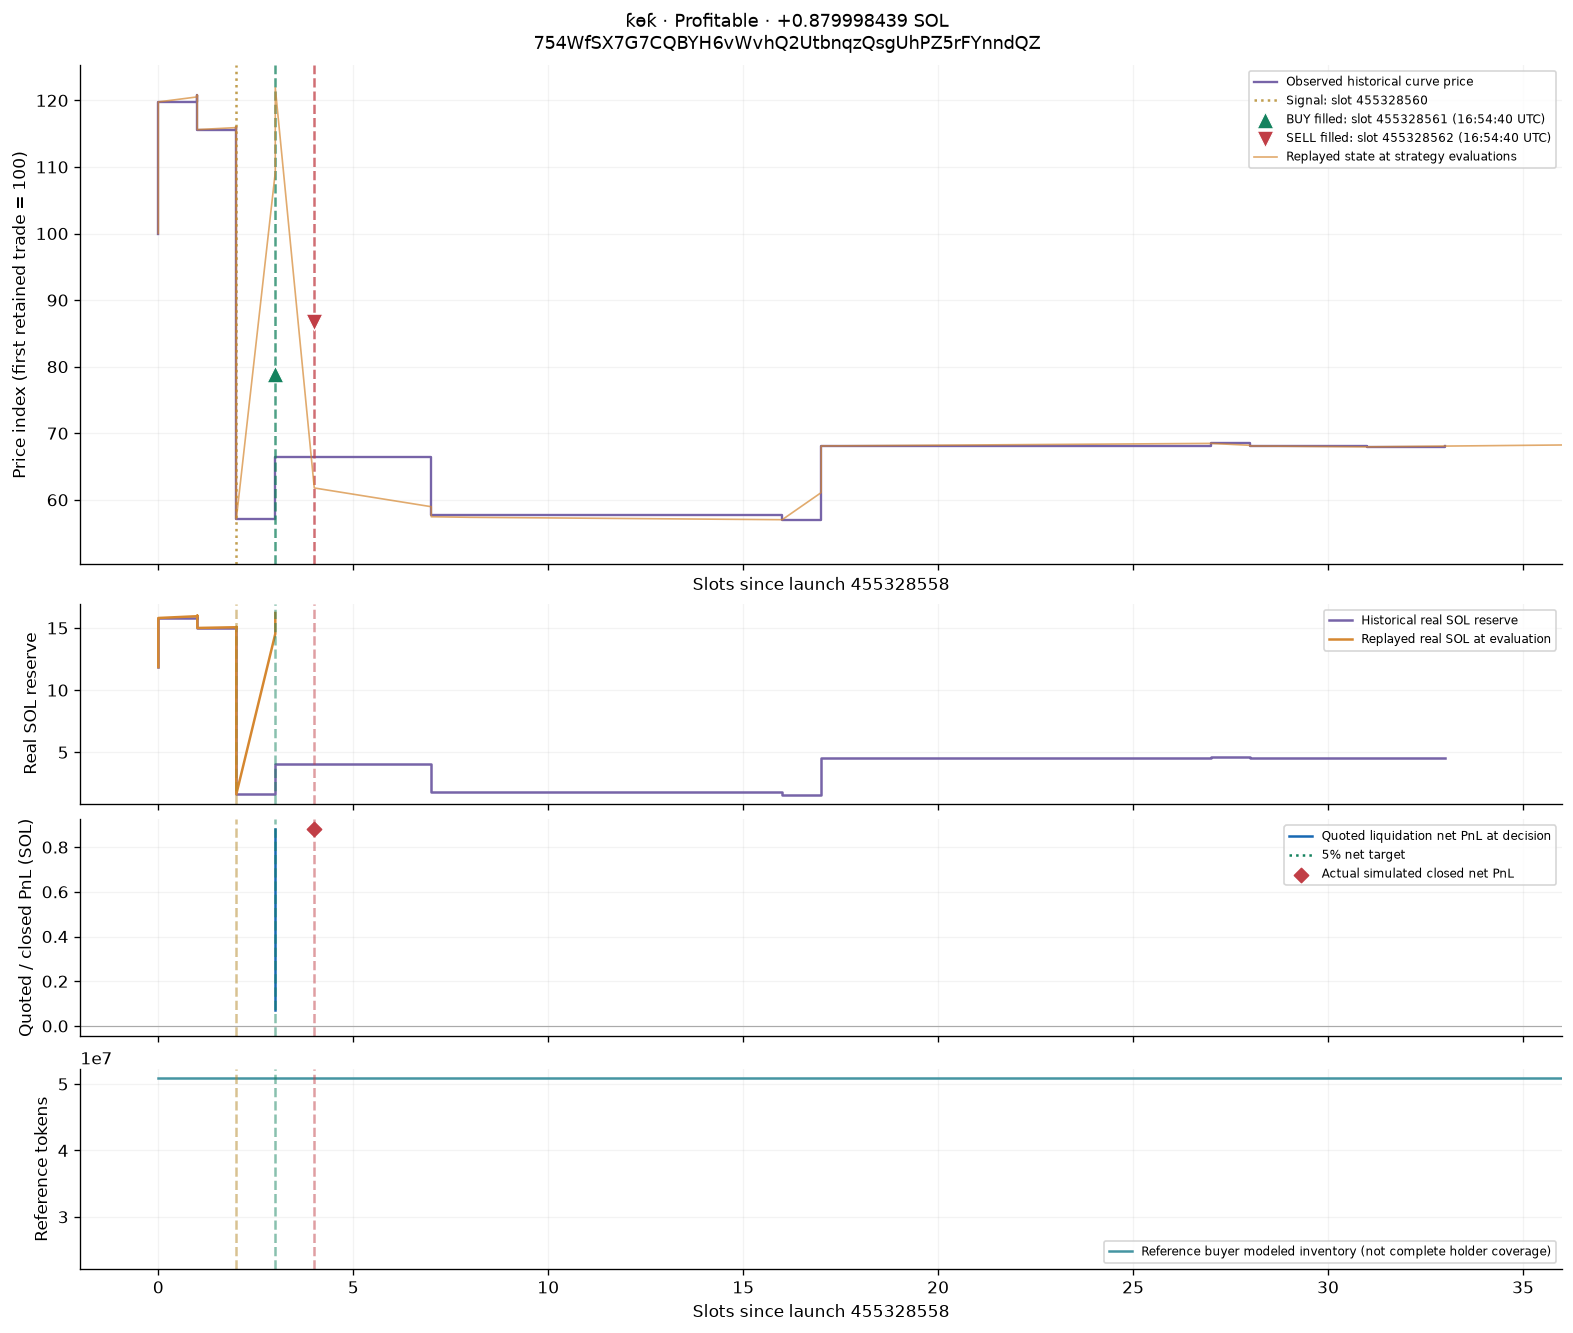

[GMGN token](https://gmgn.ai/sol/token/754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ) · [Reference buyer](https://gmgn.ai/sol/address/AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord) · [Creator](https://gmgn.ai/sol/address/bwamJzztZsepfkteWRChggmXuiiCQvpLqPietdNfSXa)

,field,recorded_value
0,signal_slot,455328560
1,entry_slot,455328561
2,exit_signal_slot,455328561
3,exit_slot,455328562
4,reason,TARGET
5,budget_lamports,12261489988
6,entry_cash_sol,12.263634268
7,closed_pnl_sol,0.879998439
8,sniper_trading_cash_cost_sol,3.033005000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ
symbol,ƙөƙ
boundary_ordinal,1955621274134774518
slot,455328560
time,1791651279
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,3
virtual_sol,31625647572


**Exit decision**

...

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621274134774518,455328560,1791651279,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,3,31625647572,1017844770833690,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,,50852336693761,3033005000,3033005000,0,,,,,,,,,BUY,6565c8f8d97957fc56cb88dfa6a833b96a966e6e1e948538034f39c277b85beb,[],0,,,,,
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621278429741056,455328561,1791651280,ORDER_FILLED,PENDING_BUY,SIGNAL,3,43735761140,736010970589580,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,,50852336693761,3033005000,3033005000,0,,,,,,,,,BUY,6565c8f8d97957fc56cb88dfa6a833b96a966e6e1e948538034f39c277b85beb,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621278429741072,455328561,1791651280,EXIT_EVALUATION,OPEN,HOLDING,3,44525884596,722950263625761,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,14525884596,50852336693761,3033005000,3033005000,0,,,,,,,,,,,,,71336002,613079750,False,12489150371,0
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621278429741077,455328561,1791651280,EXIT_EVALUATION,OPEN,HOLDING,3,44723415459,719757193792103,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,14723415459,50852336693761,3033005000,3033005000,0,,,,,,,,,,,,,165541356,613079750,False,12584548197,0
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621278429741081,455328561,1791651280,EXIT_EVALUATION,OPEN,HOLDING,3,46204896939,696679402851225,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,16204896939,50852336693761,3033005000,3033005000,0,,,,,,,,,,,,,879998439,613079750,False,13308049041,0
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621278429741081,455328561,1791651280,ORDER_ACCEPTED,OPEN,HOLDING,3,46204896939,696679402851225,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,,50852336693761,3033005000,3033005000,0,,,,,,,,,SELL,89922c243c769e050d1ff254a08f739c59fd690f83a0944d6ec405e627b52140,[],0,,,,,
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621282724708352,455328562,1791651280,ORDER_FILLED,OPEN,HOLDING,3,32896847898,978513203095335,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,,50852336693761,3033005000,3033005000,0,,,,,,,,,SELL,89922c243c769e050d1ff254a08f739c59fd690f83a0944d6ec405e627b52140,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621540422746317,455328622,1791651293,ENTRY_INELIGIBLE,CLOSED,TARGET,3,31898950511,1009124109433448,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,,50852336693761,3033005000,3033005000,0,,,,,,,,,,,,,,,,,
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621540422746351,455328622,1791651293,ENTRY_INELIGIBLE,CLOSED,TARGET,3,31996728288,1006040359424906,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,,50852336693761,3033005000,3033005000,0,,,,,,,,,,,,,,,,,
754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,ƙөƙ,1955621540422746951,455328622,1791651293,ENTRY_INELIGIBLE,CLOSED,TARGET,3,32006506065,1005733020746272,AG3ngAi7emcRcRTotTYa87C3iiFaEnLbg2xwr4nyLord,,,50852336693761,3033005000,3033005000,0,,,,,,,,,,,,,,,,,


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,754WfSX7G7CQBYH6vWvhQ2UtbnqzQsgUhPZ5rFYnndQZ,1955622760193458526,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


---

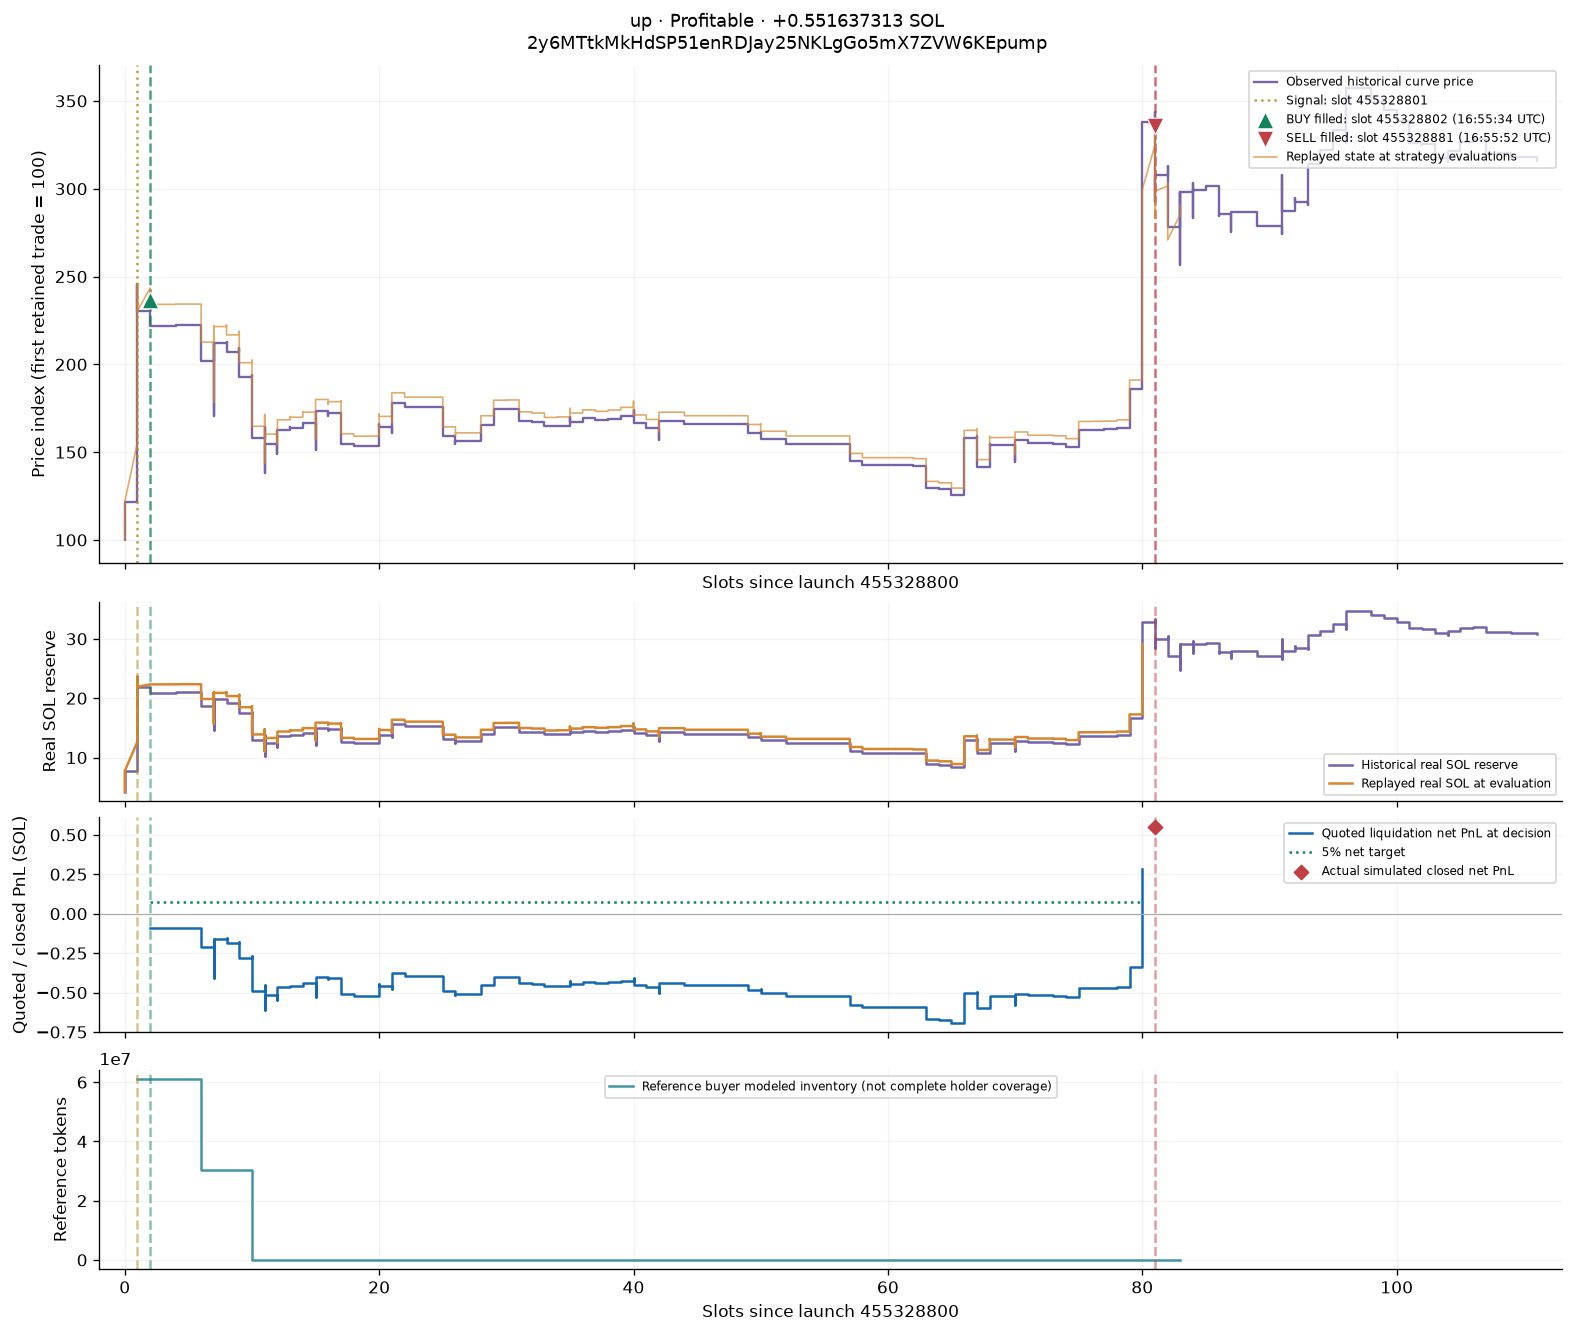

[GMGN token](https://gmgn.ai/sol/token/2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump) · [Reference buyer](https://gmgn.ai/sol/address/3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s) · [Creator](https://gmgn.ai/sol/address/DyaaFErBArgVqig8djQrvDQgii2w2A6rwxnvxwnBgrYH)

,field,recorded_value
0,signal_slot,455328801
1,entry_slot,455328802
2,exit_signal_slot,455328880
3,exit_slot,455328881
4,reason,TARGET
5,budget_lamports,1446751900
6,entry_cash_sol,1.448896180
7,closed_pnl_sol,0.551637313
8,sniper_trading_cash_cost_sol,5.200005000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump
symbol,up
boundary_ordinal,1955622309221893142
slot,455328801
time,1791651334
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,7
virtual_sol,51920088869


**Exit decision**

...

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622309221893142,455328801,1791651334,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,7,51920088869,619991234704306,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,,61059511879992,5200005000,5200005000,0,,,,,,,,,BUY,341ab827c2d6caf5bf375ea098defba9379999752d62eb9ee0f22caf498b842a,[],0,,,,,
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622313516859392,455328802,1791651334,ORDER_FILLED,PENDING_BUY,SIGNAL,7,53358856175,603273801437926,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,,61059511879992,5200005000,5200005000,0,,,,,,,,,BUY,341ab827c2d6caf5bf375ea098defba9379999752d62eb9ee0f22caf498b842a,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622644229341490,455328879,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,46848396014,687109972201014,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,16848396014,0,871300436,871300436,0,,,,,,,,,,,,,-355687711,72342845,False,1105087787,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622644229341590,455328879,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,46947161445,685664459633813,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,16947161445,0,871300436,871300436,0,,,,,,,,,,,,,-351136123,72342845,False,1109696990,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622644229341634,455328879,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,46002073659,699751066058630,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,16002073659,0,871300436,871300436,0,,,,,,,,,,,,,-394311027,72342845,False,1065975568,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622644229341773,455328879,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,47273184769,680935719515619,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,17273184769,0,871300436,871300436,0,,,,,,,,,,,,,-336045765,72342845,False,1124978366,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622648524308480,455328880,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,47273184769,680935719515619,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,17273184769,0,871300436,871300436,0,,,,,,,,,,,,,-336045765,72342845,False,1124978366,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622648524308575,455328880,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,49228740324,653886324802718,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,19228740324,0,871300436,871300436,0,,,,,,,,,,,,,-243418721,72342845,False,1218777904,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622648524308576,455328880,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,52668004078,611187012858468,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,22668004078,0,871300436,871300436,0,,,,,,,,,,,,,-71756933,72342845,False,1392612625,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622648524308956,455328880,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,59186522596,543873819144932,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,29186522596,0,871300436,871300436,0,,,,,,,,,,,,,284051512,72342845,False,1752924975,0


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,1955622661409210943,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


---

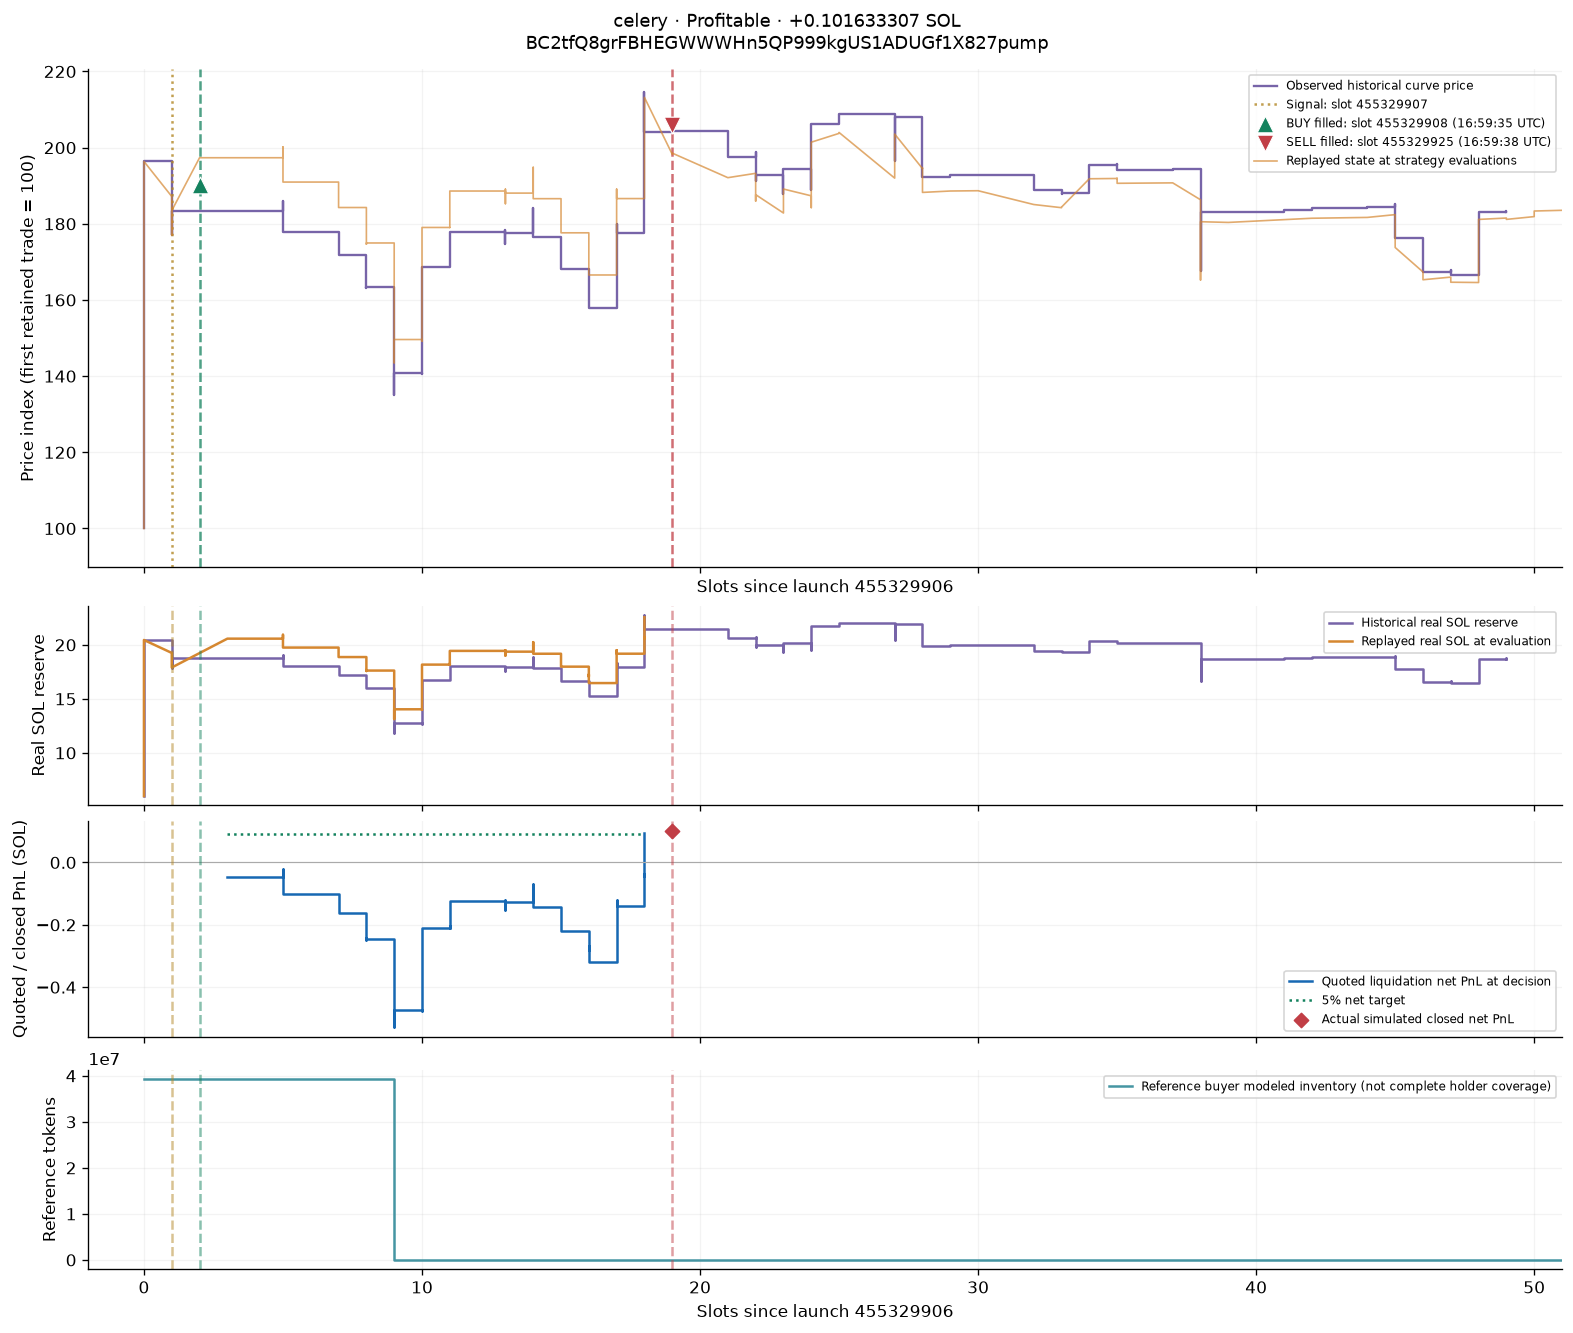

[GMGN token](https://gmgn.ai/sol/token/BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump) · [Reference buyer](https://gmgn.ai/sol/address/4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3) · [Creator](https://gmgn.ai/sol/address/9mGjJfVwmy1XCTL4KovuqTzoGjZLUhaQCij8Tu2cY2Db)

,field,recorded_value
0,signal_slot,455329907
1,entry_slot,455329908
2,exit_signal_slot,455329924
3,exit_slot,455329925
4,reason,TARGET
5,budget_lamports,1834718481
6,entry_cash_sol,1.836862761
7,closed_pnl_sol,0.101633307
8,sniper_trading_cash_cost_sol,3.021667962
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump
symbol,celery
boundary_ordinal,1955627059455721547
slot,455329907
time,1791651574
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,7
virtual_sol,47902299797


**Exit decision**

,recorded_value
mint,BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump
symbol,celery
boundary_ordinal,1955627132470166518
slot,455329924
time,1791651578
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,7
virtual_sol,52564147697


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627059455721547,455329907,1791651574,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,7,47902299797,671992788219476,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,,39290210105479,3021667962,3021667962,0,,,,,,,,,BUY,ecf7ee867e0784e8db1e77d567cc391359ac30e80fee3e1afa6ae240e83cb966,[],0,,,,,
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627063750688768,455329908,1791651575,ORDER_FILLED,PENDING_BUY,SIGNAL,7,50573626689,636497758063278,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,,39290210105479,3021667962,3021667962,0,,,,,,,,,BUY,ecf7ee867e0784e8db1e77d567cc391359ac30e80fee3e1afa6ae240e83cb966,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627128175199084,455329923,1791651578,EXIT_EVALUATION,OPEN,HOLDING,7,49180325120,654530037155507,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,19180325120,0,655322451,655322451,0,,,,,,,,,,,,,-141078223,91741175,False,1715291402,0
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627132470165504,455329924,1791651578,EXIT_EVALUATION,OPEN,HOLDING,7,49180325120,654530037155507,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,19180325120,0,655322451,655322451,0,,,,,,,,,,,,,-141078223,91741175,False,1715291402,0
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627132470165572,455329924,1791651578,EXIT_EVALUATION,OPEN,HOLDING,7,49207011194,654175070740585,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,19207011194,0,655322451,655322451,0,,,,,,,,,,,,,-139271591,91741175,False,1717120902,0
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627132470165703,455329924,1791651578,EXIT_EVALUATION,OPEN,HOLDING,7,50611767990,636018090408116,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,20611767990,0,655322451,655322451,0,,,,,,,,,,,,,-42860041,91741175,False,1814752852,0
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627132470165900,455329924,1791651578,EXIT_EVALUATION,OPEN,HOLDING,7,50710533421,634779361569146,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,20710533421,0,655322451,655322451,0,,,,,,,,,,,,,-35984891,91741175,False,1821715029,0
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627132470166106,455329924,1791651578,EXIT_EVALUATION,OPEN,HOLDING,7,50598814365,636180915182668,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,20598814365,0,655322451,655322451,0,,,,,,,,,,,,,-43760814,91741175,False,1813840677,0
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627132470166509,455329924,1791651578,EXIT_EVALUATION,OPEN,HOLDING,7,50608592142,636058002566036,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,20608592142,0,655322451,655322451,0,,,,,,,,,,,,,-43080904,91741175,False,1814529193,0
BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,celery,1955627132470166518,455329924,1791651578,EXIT_EVALUATION,OPEN,HOLDING,7,52564147697,612394596725656,4yFAz7dp5WwuZs3vbWKedbRiUmSFxTVGCdsLAxfEQrG3,,22564147697,0,655322451,655322451,0,,,,,,,,,,,,,95396967,91741175,False,1954759948,0


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,BC2tfQ8grFBHEGWWWHn5QP999kgUS1ADUGf1X827pump,1955629533356884566,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN


In [5]:
selected = review.ENTRY_EXIT[review.ENTRY_EXIT['group'] == 'Profitable']
review.linked_table(selected[columns])
for mint in selected['mint']:
    display(Markdown('---'))
    review.inspect(mint)

## Losing positions — 14

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,gmgn_url
BRIMHUB,Unprofitable,TIMEOUT,455317286,455317287,2026-10-10T16:13:33+00:00,455318652,2026-10-10T16:18:33+00:00,0.728648094,0.598954546,-0.129693548,0.000000000,0.000000000,GMGN
UNBOX,Unprofitable,TIMEOUT,455319401,455319402,2026-10-10T16:21:18+00:00,455320766,2026-10-10T16:26:18+00:00,1.278134722,0.504710108,-0.773424614,0.000000000,0.000000000,GMGN
Qweb,Unprofitable,TIMEOUT,455319406,455319407,2026-10-10T16:21:19+00:00,455320771,2026-10-10T16:26:19+00:00,1.403320640,0.554141209,-0.849179431,0.000000000,0.000000000,GMGN
KUSO,Unprofitable,TIMEOUT,455319916,455319917,2026-10-10T16:23:10+00:00,455321280,2026-10-10T16:28:10+00:00,1.129363900,0.817150148,-0.312213752,0.000000000,0.000000000,GMGN
POPPOINT,Unprofitable,TIMEOUT,455320252,455320253,2026-10-10T16:24:25+00:00,455321627,2026-10-10T16:29:25+00:00,1.014469540,0.758541180,-0.255928360,0.000000000,0.000000000,GMGN
CRD,Unprofitable,TIMEOUT,455321879,455321880,2026-10-10T16:30:19+00:00,455323237,2026-10-10T16:35:19+00:00,1.521456678,1.198221610,-0.323235068,0.000000000,0.000000000,GMGN
MUNA,Unprofitable,TIMEOUT,455323776,455323777,2026-10-10T16:37:17+00:00,455325143,2026-10-10T16:42:17+00:00,0.759669700,0.609935990,-0.149733710,0.000000000,0.000000000,GMGN
QUANTARENA,Unprofitable,TIMEOUT,455324088,455324089,2026-10-10T16:38:24+00:00,455325449,2026-10-10T16:43:24+00:00,0.752845459,0.528248932,-0.224596527,0.000000000,0.000000000,GMGN
MASCHINA,Unprofitable,TIMEOUT,455325537,455325538,2026-10-10T16:43:43+00:00,455326916,2026-10-10T16:48:43+00:00,5.025296250,3.096766262,-1.928529988,0.000000000,0.000000000,GMGN
PRINU,Unprofitable,TIMEOUT,455325754,455325755,2026-10-10T16:44:30+00:00,455327135,2026-10-10T16:49:30+00:00,1.979441540,1.261716351,-0.717725189,0.000000000,0.000000000,GMGN


---

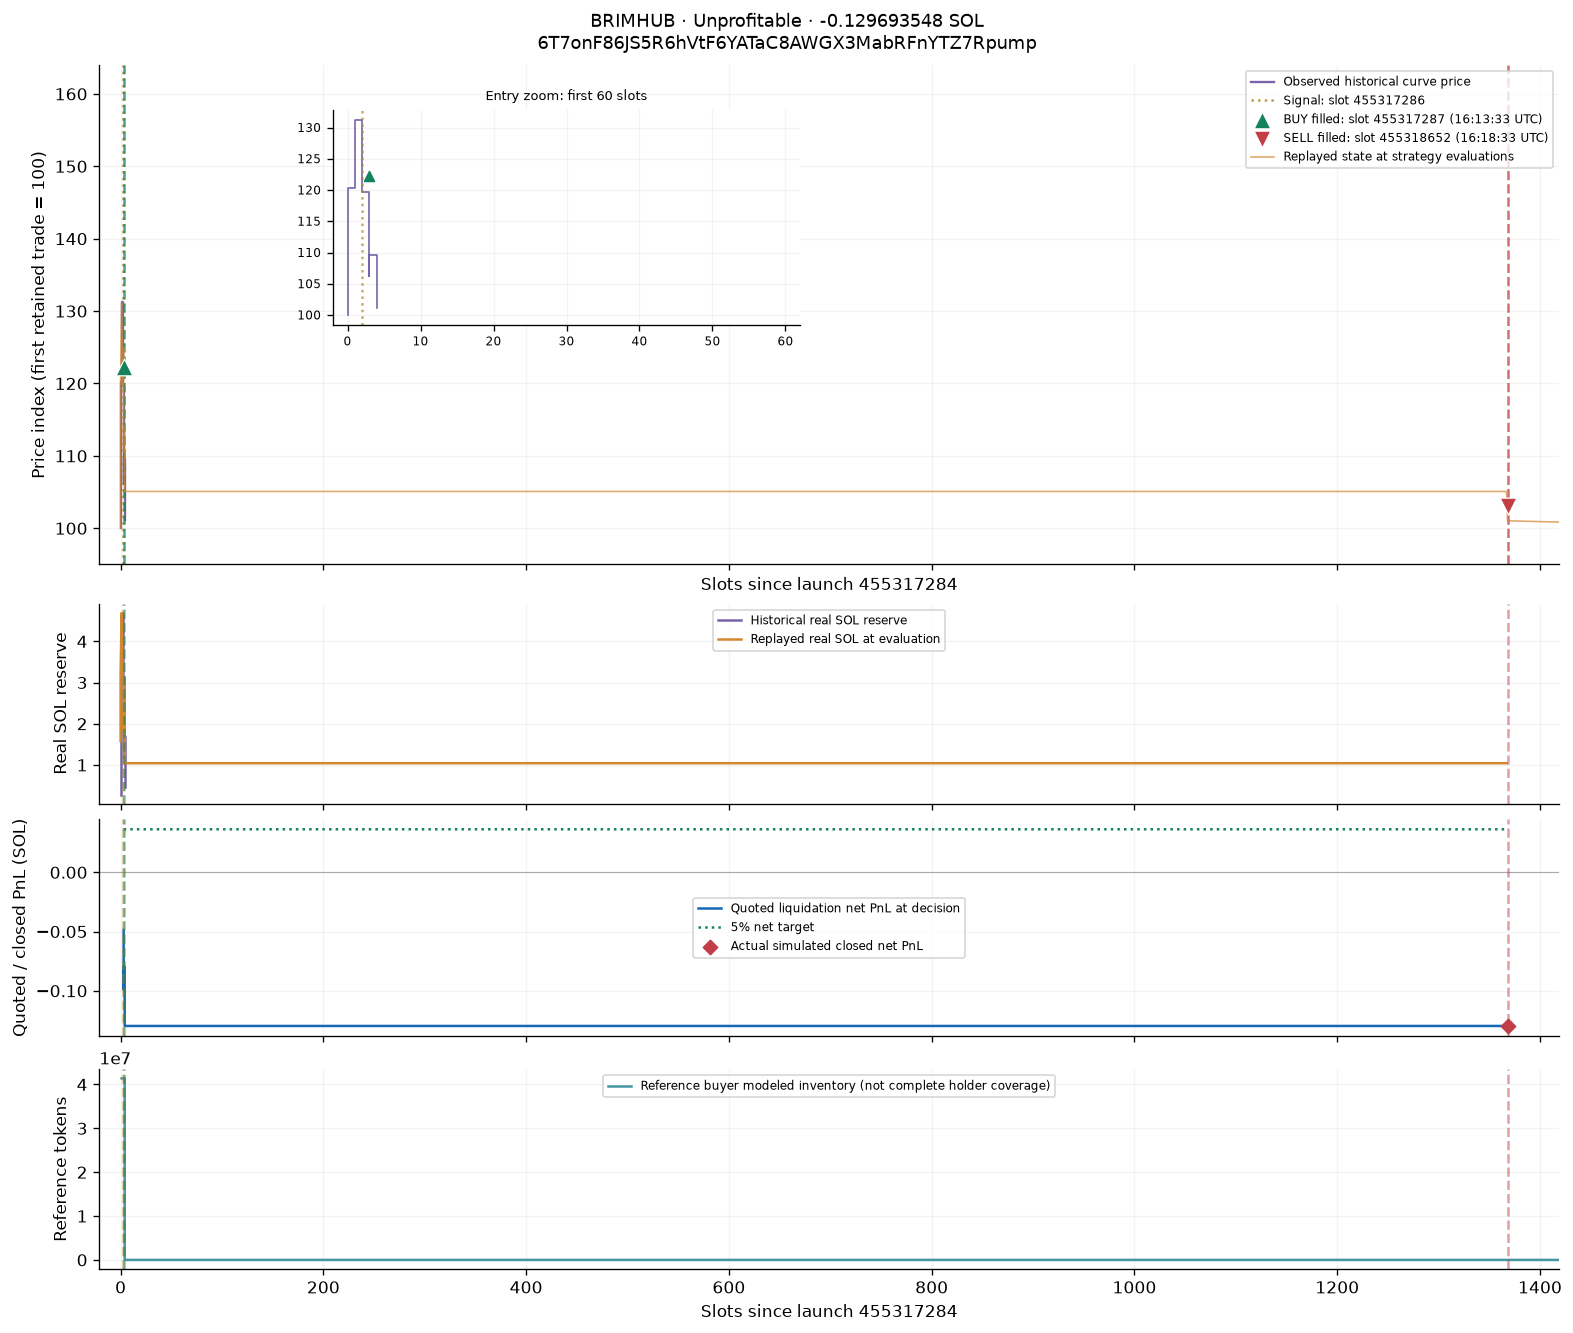

[GMGN token](https://gmgn.ai/sol/token/6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump) · [Reference buyer](https://gmgn.ai/sol/address/AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs) · [Creator](https://gmgn.ai/sol/address/EGLoh2fjcQ11YuruYAdxJHLYjE3VAAmPMuxeKz2QEity)

,field,recorded_value
0,signal_slot,455317286
1,entry_slot,455317287
2,exit_signal_slot,455318651
3,exit_slot,455318652
4,reason,TIMEOUT
5,budget_lamports,726503814
6,entry_cash_sol,0.728648094
7,closed_pnl_sol,-0.129693548
8,sniper_trading_cash_cost_sol,1.500455000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump
symbol,BRIMHUB
boundary_ordinal,1955572852673479117
slot,455317286
time,1791648813
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,2
virtual_sol,33131068982


**Exit decision**

,recorded_value
mint,6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump
symbol,BRIMHUB
boundary_ordinal,1955578715303837696
slot,455318651
time,1791649113
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,2
virtual_sol,31042981762


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955572852673479117,455317286,1791648813,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,2,33131068982,971595574506768,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,,41397694869669,1500455000,1500455000,0,,,,,,,,,BUY,86727a4228fb45e1cade662e1c4155862d5034936bb756ec902e86acf64b4973,[],0,,,,,
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955572856968445952,455317287,1791648813,ORDER_FILLED,PENDING_BUY,SIGNAL,2,33848603613,950999349059637,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,,41397694869669,1500455000,1500455000,0,,,,,,,,,BUY,86727a4228fb45e1cade662e1c4155862d5034936bb756ec902e86acf64b4973,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955578685239066624,455318644,1791649111,EXIT_EVALUATION,OPEN,HOLDING,2,31042981762,1036949357912810,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,1042981762,0,240745605,240745605,0,,,,,,,,,,,,,-129693548,36330441,False,604577486,0
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955578689534033920,455318645,1791649111,EXIT_EVALUATION,OPEN,HOLDING,2,31042981762,1036949357912810,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,1042981762,0,240745605,240745605,0,,,,,,,,,,,,,-129693548,36330441,False,604577486,0
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955578693829001216,455318646,1791649111,EXIT_EVALUATION,OPEN,HOLDING,2,31042981762,1036949357912810,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,1042981762,0,240745605,240745605,0,,,,,,,,,,,,,-129693548,36330441,False,604577486,0
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955578698123968512,455318647,1791649111,EXIT_EVALUATION,OPEN,HOLDING,2,31042981762,1036949357912810,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,1042981762,0,240745605,240745605,0,,,,,,,,,,,,,-129693548,36330441,False,604577486,0
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955578702418935808,455318648,1791649112,EXIT_EVALUATION,OPEN,HOLDING,2,31042981762,1036949357912810,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,1042981762,0,240745605,240745605,0,,,,,,,,,,,,,-129693548,36330441,False,604577486,0
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955578706713903104,455318649,1791649112,EXIT_EVALUATION,OPEN,HOLDING,2,31042981762,1036949357912810,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,1042981762,0,240745605,240745605,0,,,,,,,,,,,,,-129693548,36330441,False,604577486,0
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955578711008870400,455318650,1791649112,EXIT_EVALUATION,OPEN,HOLDING,2,31042981762,1036949357912810,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,1042981762,0,240745605,240745605,0,,,,,,,,,,,,,-129693548,36330441,False,604577486,0
6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,BRIMHUB,1955578715303837696,455318651,1791649113,EXIT_EVALUATION,OPEN,HOLDING,2,31042981762,1036949357912810,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,1042981762,0,240745605,240745605,0,,,,,,,,,,,,,-129693548,36330441,True,604577486,0


---

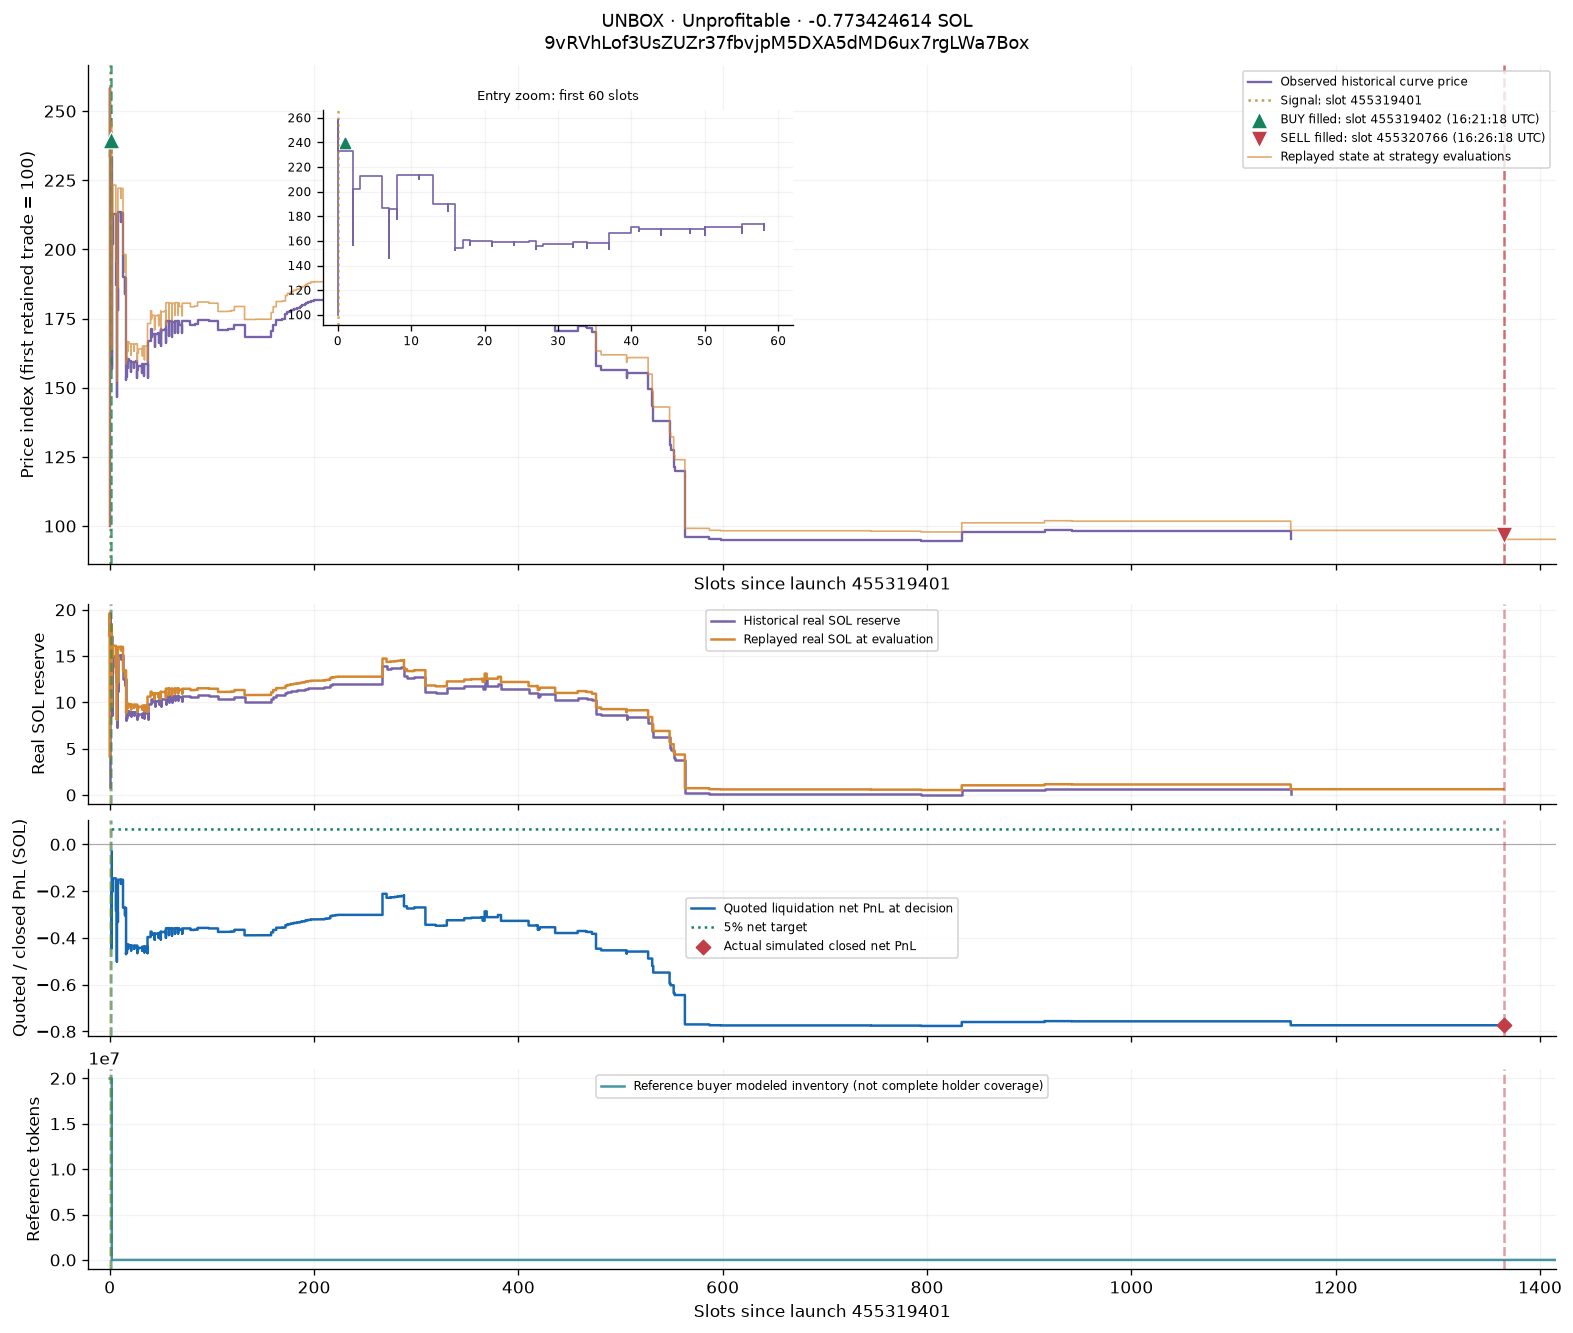

[GMGN token](https://gmgn.ai/sol/token/9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box) · [Reference buyer](https://gmgn.ai/sol/address/BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL) · [Creator](https://gmgn.ai/sol/address/3U5eDRNnCzQJoaSdkwARhaUSSr547FUpZFR9QkHvTugB)

,field,recorded_value
0,signal_slot,455319401
1,entry_slot,455319402
2,exit_signal_slot,455320765
3,exit_slot,455320766
4,reason,TIMEOUT
5,budget_lamports,1275990442
6,entry_cash_sol,1.278134722
7,closed_pnl_sol,-0.773424614
8,sniper_trading_cash_cost_sol,1.500480000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box
symbol,UNBOX
boundary_ordinal,1955581936529310036
slot,455319401
time,1791649278
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,6
virtual_sol,47144515811


**Exit decision**

,recorded_value
mint,9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box
symbol,UNBOX
boundary_ordinal,1955587794864701440
slot,455320765
time,1791649578
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,8
virtual_sol,30619152136


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310028,455319401,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,49613201525,648819245986090,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,19613201525,45932483661316,3099005000,3099005000,0,,,,,,,,,,,,,,,,,
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310028,455319401,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,49613201525,648819245986090,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,0,19613201525,19971290352667,1500480000,1500480000,0,,,,,,,,,,,,,,,,,
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310028,455319401,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,49613201525,648819245986090,8ptvshQRZPRaRQBSCRxhHwbJFr6ktyUQ1SATDCLijkBW,0,19613201525,15014355025628,1088205000,1088205000,0,,,,,,,,,,,,,,,,,
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310028,455319401,1791649278,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,49613201525,648819245986090,,,,,,,,,,,,,,,,,,,,,,,,
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310036,455319401,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,47144515811,682794158576050,EUsez9vj6GM1mVhSFNkfb5HLD684TwuSCH5rABFPic8Z,0,17144515811,99085719718762,4066446477,4066446477,0,,,,,,,,,,,,,,,,,
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310036,455319401,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,47144515811,682794158576050,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,0,17144515811,79274796043295,3630648595,3630648595,0,,,,,,,,,,,,,,,,,
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310036,455319401,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,47144515811,682794158576050,4Acj5VDoTzYcz5jNZxoWc7VZZrLSG2Hcna9MDENbbG5o,0,17144515811,100914280281229,3347727334,3347727334,0,,,,,,,,,,,,,,,,,
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310036,455319401,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,47144515811,682794158576050,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,17144515811,45932483661316,3099005000,3099005000,0,,,,,,,,,,,,,,,,,
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310036,455319401,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,47144515811,682794158576050,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,1275990490,17144515811,19971290352667,1500480000,1500480000,0,,,,,,,,,,,,,,,,,
9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,UNBOX,1955581936529310036,455319401,1791649278,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,6,47144515811,682794158576050,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,1275990442,,19971290352667,1500480000,1500480000,0,50254032517.6728321264084426877688238996067847903902915427999,50253032514.3025585951440698537046402253431677993966684158278,1000000,48404753284,18404753284,17776824091415,1260237473,16887982886844,,,,,,,,,


---

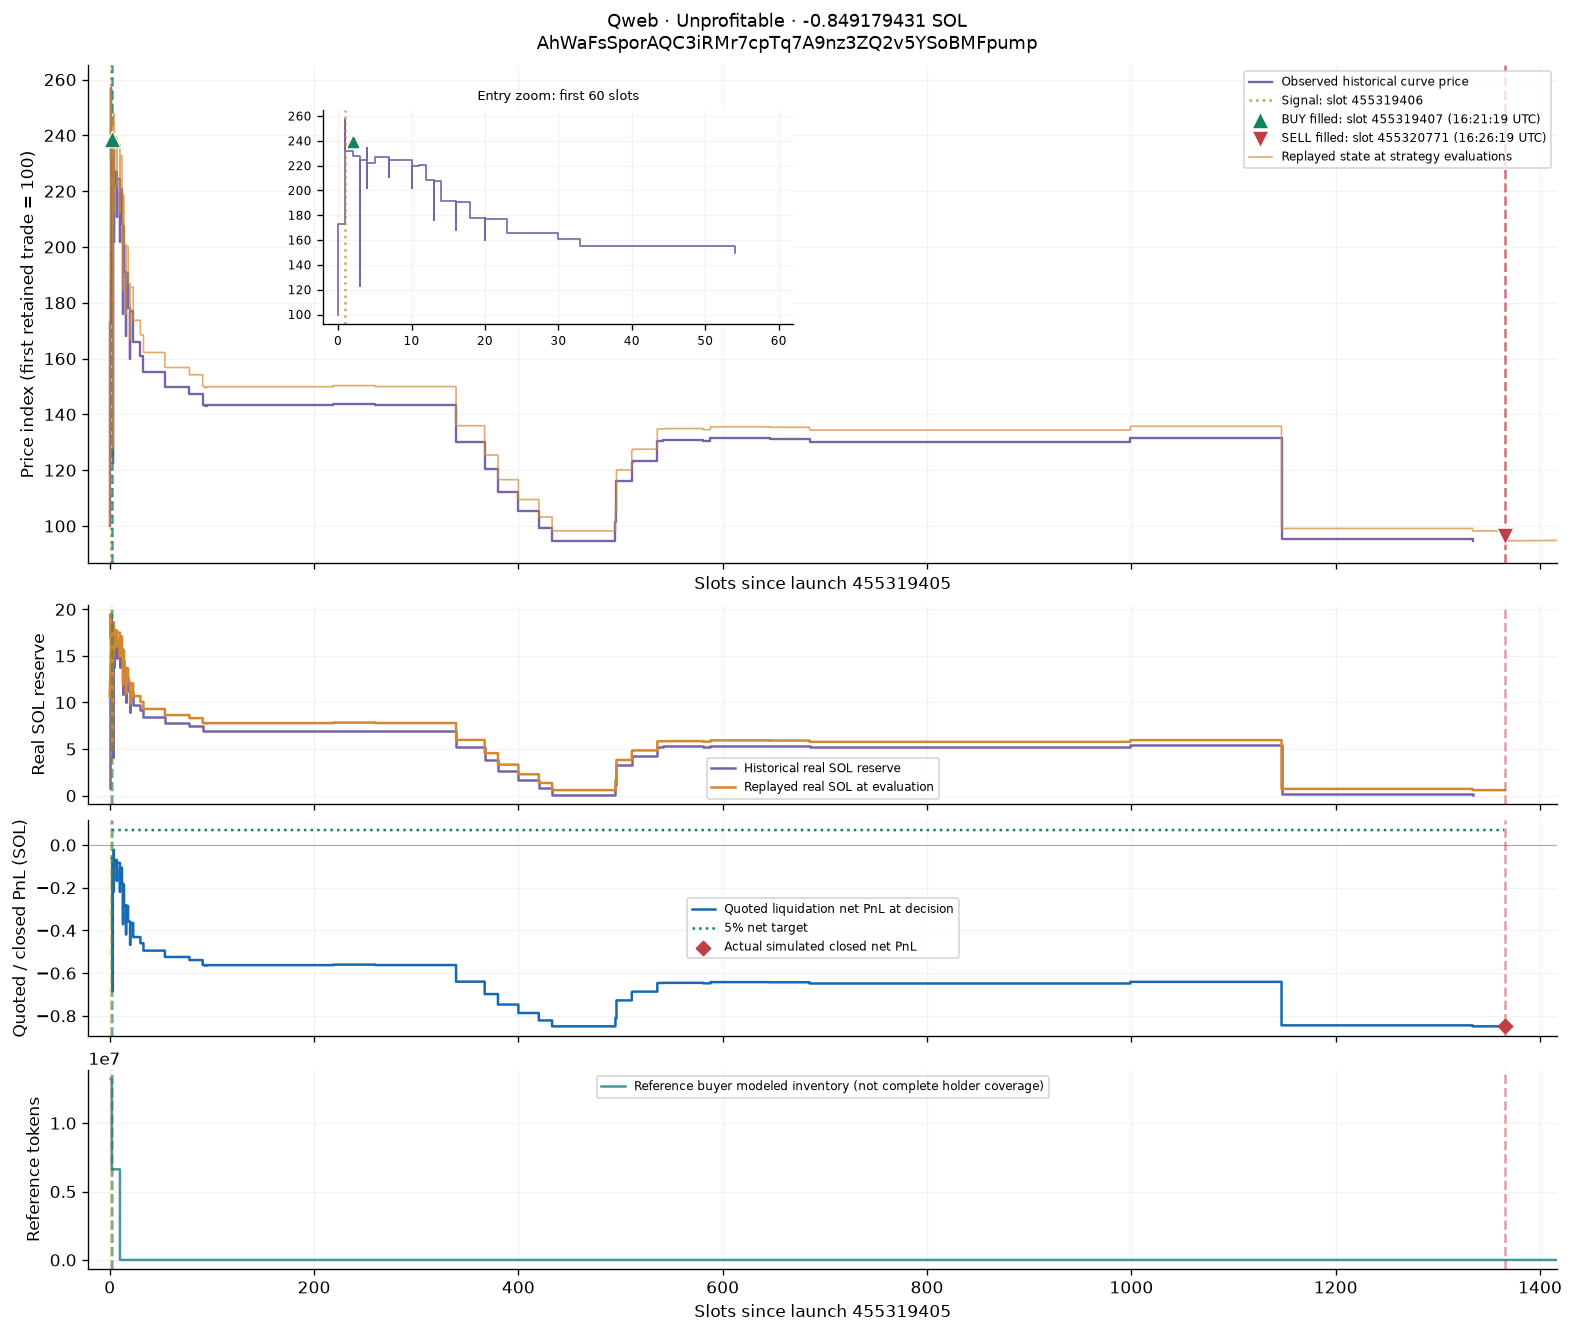

[GMGN token](https://gmgn.ai/sol/token/AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump) · [Reference buyer](https://gmgn.ai/sol/address/7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj) · [Creator](https://gmgn.ai/sol/address/2AgJ3bj8BrhnpuATudrn3hocEewkyMCe2B2J5Xffr3qk)

,field,recorded_value
0,signal_slot,455319406
1,entry_slot,455319407
2,exit_signal_slot,455320770
3,exit_slot,455320771
4,reason,TIMEOUT
5,budget_lamports,1401176360
6,entry_cash_sol,1.403320640
7,closed_pnl_sol,-0.849179431
8,sniper_trading_cash_cost_sol,1.004755000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump
symbol,Qweb
boundary_ordinal,1955581958004146354
slot,455319406
time,1791649279
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,5
virtual_sol,46996228584


**Exit decision**

,recorded_value
mint,AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump
symbol,Qweb
boundary_ordinal,1955587816339537920
slot,455320770
time,1791649579
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,5
virtual_sol,30591758095


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955581958004146354,455319406,1791649279,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,5,46996228584,684948579345028,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,,13249367105227,1004755000,1004755000,0,,,,,,,,,BUY,2c09a54baa5e7e5ef420a4a7889b4c645c7a1572dc5ddd261b5e011f805a9490,[],0,,,,,
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955581962299113472,455319407,1791649279,ORDER_FILLED,PENDING_BUY,SIGNAL,5,48380106470,665356121607774,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,,13249367105227,1004755000,1004755000,0,,,,,,,,,BUY,2c09a54baa5e7e5ef420a4a7889b4c645c7a1572dc5ddd261b5e011f805a9490,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955587786274766848,455320763,1791649577,EXIT_EVALUATION,OPEN,HOLDING,5,30591758095,1052244200537059,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,591758095,0,80277580,80277580,0,,,,,,,,,,,,,-849179431,70064068,False,559196891,0
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955587790569734144,455320764,1791649577,EXIT_EVALUATION,OPEN,HOLDING,5,30591758095,1052244200537059,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,591758095,0,80277580,80277580,0,,,,,,,,,,,,,-849179431,70064068,False,559196891,0
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955587794864701440,455320765,1791649578,EXIT_EVALUATION,OPEN,HOLDING,5,30591758095,1052244200537059,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,591758095,0,80277580,80277580,0,,,,,,,,,,,,,-849179431,70064068,False,559196891,0
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955587799159668736,455320766,1791649578,EXIT_EVALUATION,OPEN,HOLDING,5,30591758095,1052244200537059,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,591758095,0,80277580,80277580,0,,,,,,,,,,,,,-849179431,70064068,False,559196891,0
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955587803454636032,455320767,1791649578,EXIT_EVALUATION,OPEN,HOLDING,5,30591758095,1052244200537059,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,591758095,0,80277580,80277580,0,,,,,,,,,,,,,-849179431,70064068,False,559196891,0
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955587807749603328,455320768,1791649578,EXIT_EVALUATION,OPEN,HOLDING,5,30591758095,1052244200537059,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,591758095,0,80277580,80277580,0,,,,,,,,,,,,,-849179431,70064068,False,559196891,0
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955587812044570624,455320769,1791649578,EXIT_EVALUATION,OPEN,HOLDING,5,30591758095,1052244200537059,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,591758095,0,80277580,80277580,0,,,,,,,,,,,,,-849179431,70064068,False,559196891,0
AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,Qweb,1955587816339537920,455320770,1791649579,EXIT_EVALUATION,OPEN,HOLDING,5,30591758095,1052244200537059,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,,591758095,0,80277580,80277580,0,,,,,,,,,,,,,-849179431,70064068,True,559196891,0


---

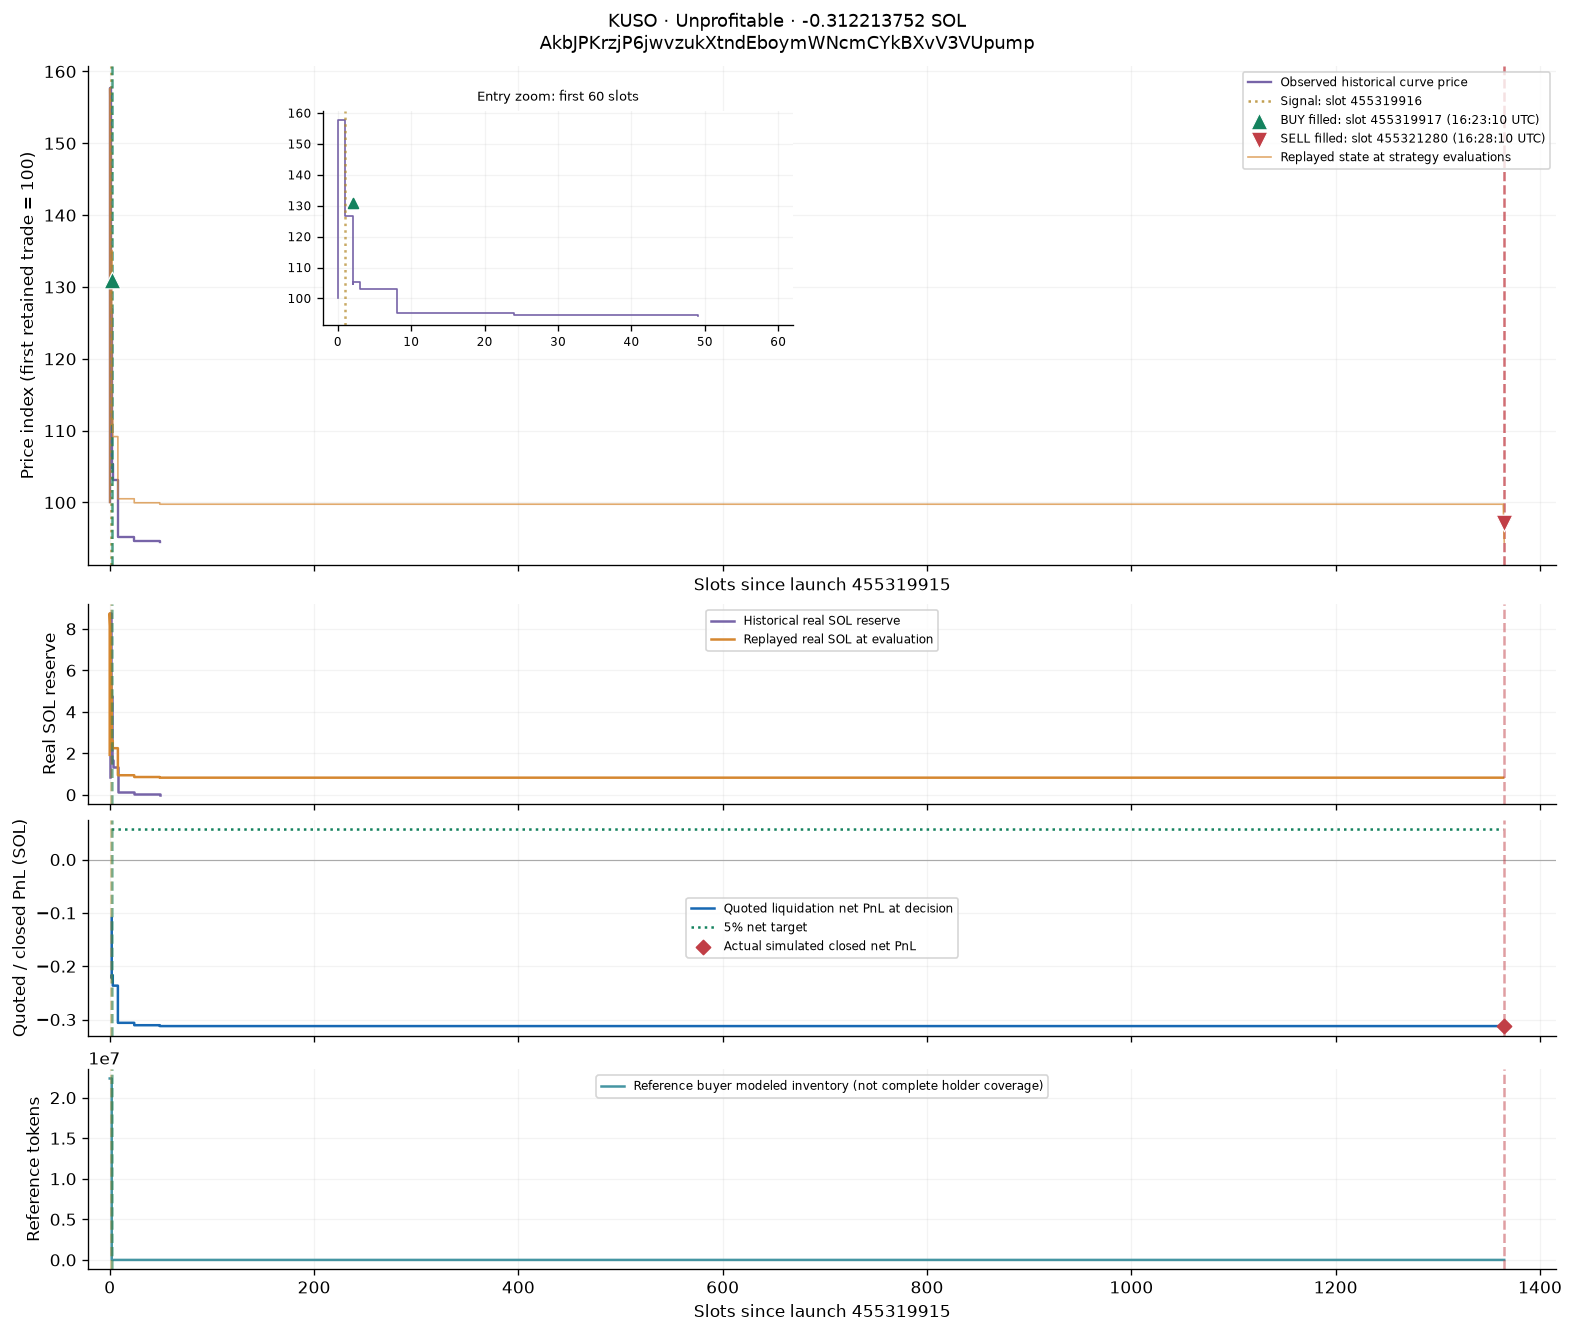

[GMGN token](https://gmgn.ai/sol/token/AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump) · [Reference buyer](https://gmgn.ai/sol/address/straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD) · [Creator](https://gmgn.ai/sol/address/8Tkn47KhnHxZcbfKEUCKDC4N7kx8RAz6Q1WygZiUbcZg)

,field,recorded_value
0,signal_slot,455319916
1,entry_slot,455319917
2,exit_signal_slot,455321279
3,exit_slot,455321280
4,reason,TIMEOUT
5,budget_lamports,1127219620
6,entry_cash_sol,1.129363900
7,closed_pnl_sol,-0.312213752
8,sniper_trading_cash_cost_sol,1.008505001
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump
symbol,KUSO
boundary_ordinal,1955584148437468090
slot,455319916
time,1791649390
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,4
virtual_sol,36306291069


**Exit decision**

,recorded_value
mint,AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump
symbol,KUSO
boundary_ordinal,1955590002477891584
slot,455321279
time,1791649690
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,4
virtual_sol,30825535067


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584144142500695,455319915,1791649390,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,38748776971,830735897254375,,,,,,,,,,,,,,,,,,,,,,,,
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584148437467724,455319916,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,37577782117,856623201029962,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,7577782117,81464884093072,3000005000,3000005000,0,,,,,,,,,,,,,,,,,
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584148437467724,455319916,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,37577782117,856623201029962,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,0,7577782117,35867496809101,1500455000,1500455000,0,,,,,,,,,,,,,,,,,
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584148437467724,455319916,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,37577782117,856623201029962,EtXS3zbz67VqWVptE8FFETAw4f99AiEnf4Bdxh8SQnMv,0,7577782117,34730735340997,1076423750,1076423750,0,,,,,,,,,,,,,,,,,
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584148437467724,455319916,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,37577782117,856623201029962,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,0,7577782117,22366060260386,1008505001,1008505001,0,,,,,,,,,,,,,,,,,
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584148437467724,455319916,1791649390,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,37577782117,856623201029962,,,,,,,,,,,,,,,,,,,,,,,,
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584148437468090,455319916,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36306291069,886623201029962,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,6306291069,81464884093072,3000005000,3000005000,0,,,,,,,,,,,,,,,,,
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584148437468090,455319916,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36306291069,886623201029962,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,0,6306291069,35867496809101,1500455000,1500455000,0,,,,,,,,,,,,,,,,,
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584148437468090,455319916,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36306291069,886623201029962,EtXS3zbz67VqWVptE8FFETAw4f99AiEnf4Bdxh8SQnMv,0,6306291069,34730735340997,1076423750,1076423750,0,,,,,,,,,,,,,,,,,
AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,KUSO,1955584148437468090,455319916,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36306291069,886623201029962,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,1127219649,6306291069,22366060260386,1008505001,1008505001,0,,,,,,,,,,,,,,,,,


---

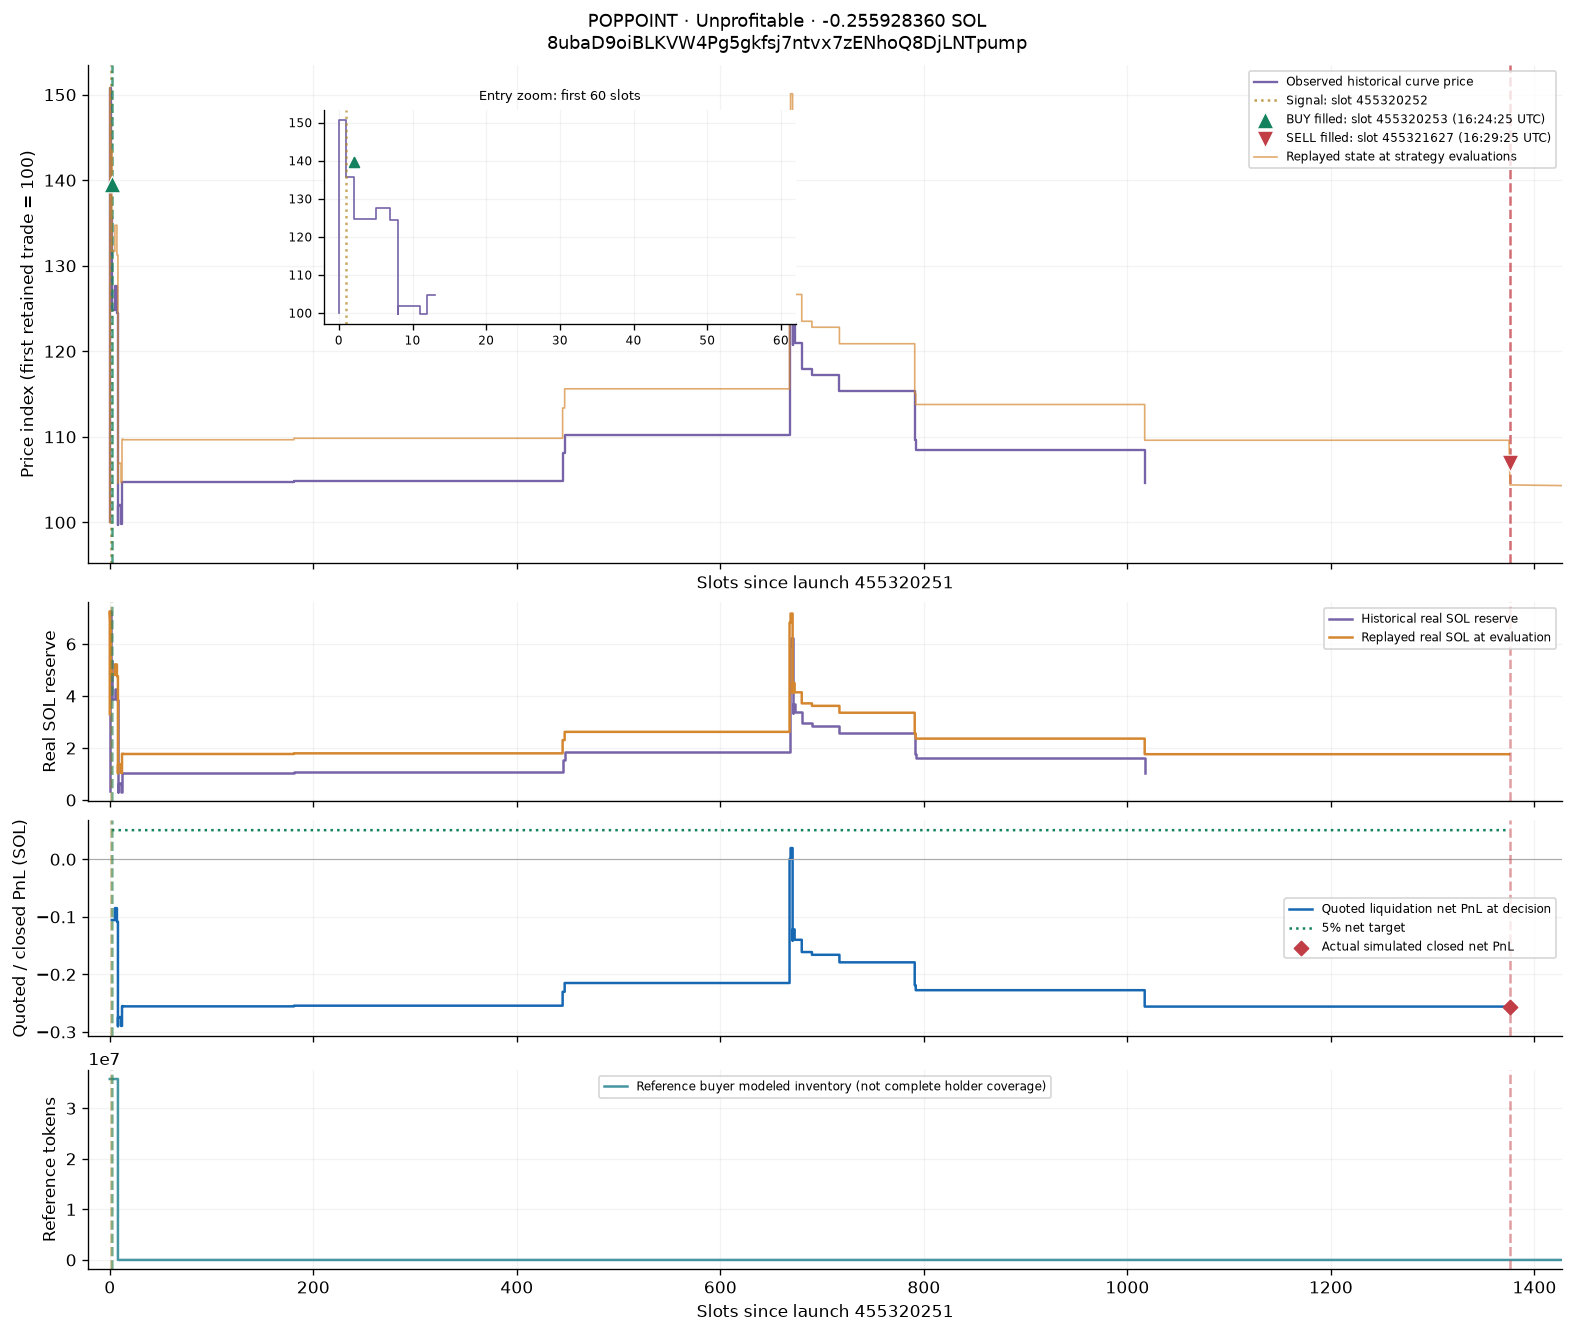

[GMGN token](https://gmgn.ai/sol/token/8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump) · [Reference buyer](https://gmgn.ai/sol/address/AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs) · [Creator](https://gmgn.ai/sol/address/2ayLjKUaKHyDPZqFb4xkC1Rvc1YYWVYewqkUmK3yxANB)

,field,recorded_value
0,signal_slot,455320252
1,entry_slot,455320253
2,exit_signal_slot,455321626
3,exit_slot,455321627
4,reason,TIMEOUT
5,budget_lamports,1012325260
6,entry_cash_sol,1.014469540
7,closed_pnl_sol,-0.255928360
8,sniper_trading_cash_cost_sol,1.500455000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump
symbol,POPPOINT
boundary_ordinal,1955585591546479596
slot,455320252
time,1791649465
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,4
virtual_sol,35346415622


**Exit decision**

,recorded_value
mint,8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump
symbol,POPPOINT
boundary_ordinal,1955591492831543296
slot,455321626
time,1791649765
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,4
virtual_sol,31762077545


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585587251512417,455320251,1791649465,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,37257821058,863979671668603,,,,,,,,,,,,,,,,,,,,,,,,
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585591546479168,455320252,1791649465,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36461068098,882859490526900,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,6461068098,75519275433189,2229659939,2229659939,0,,,,,,,,,,,,,,,,,
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585591546479168,455320252,1791649465,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36461068098,882859490526900,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,0,6461068098,38878972604090,1500480000,1500480000,0,,,,,,,,,,,,,,,,,
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585591546479168,455320252,1791649465,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36461068098,882859490526900,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,0,6461068098,35786676193860,1500455000,1500455000,0,,,,,,,,,,,,,,,,,
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585591546479168,455320252,1791649465,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36461068098,882859490526900,EaoBCDSwUfzyqthe55Qne8StLxS64TwSq7m5wD2umsFN,0,6461068098,27841055450600,1020005000,1020005000,0,,,,,,,,,,,,,,,,,
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585591546479168,455320252,1791649465,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36461068098,882859490526900,,,,,,,,,,,,,,,,,,,,,,,,
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585591546479596,455320252,1791649465,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,35346415622,910700545977500,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,5346415622,75519275433189,2229659939,2229659939,0,,,,,,,,,,,,,,,,,
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585591546479596,455320252,1791649465,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,35346415622,910700545977500,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,0,5346415622,38878972604090,1500480000,1500480000,0,,,,,,,,,,,,,,,,,
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585591546479596,455320252,1791649465,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,35346415622,910700545977500,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,1012325310,5346415622,35786676193860,1500455000,1500455000,0,,,,,,,,,,,,,,,,,
8ubaD9oiBLKVW4Pg5gkfsj7ntvx7zENhoQ8DjLNTpump,POPPOINT,1955585591546479596,455320252,1791649465,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,4,35346415622,910700545977500,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,1012325260,,35786676193860,1500455000,1500455000,0,37736958333.6663279293959033553622032575575097382234484012421,37735958322.3963213642839444194377063241854588030485894911678,1000000,36346243038,6346243038,25051925498788,999827416,23799329223848,,,,,,,,,


---

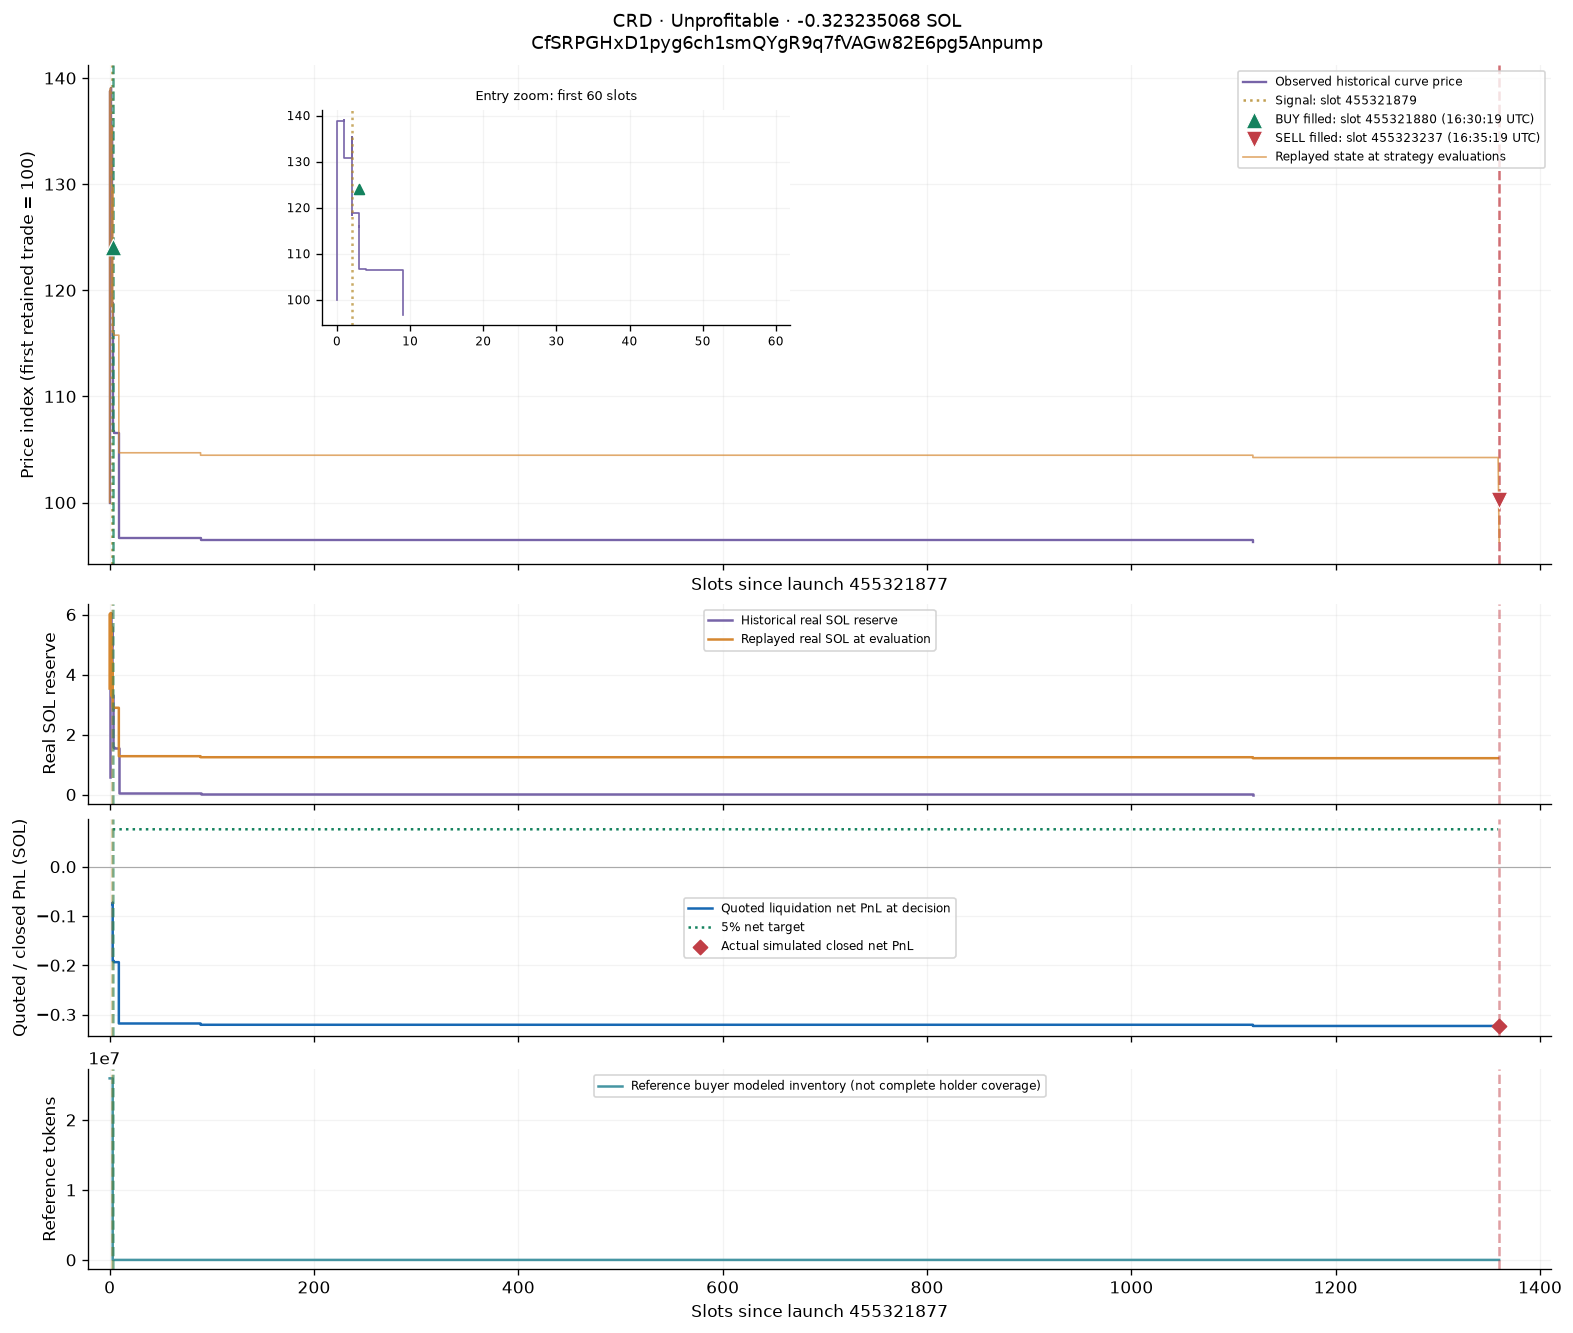

[GMGN token](https://gmgn.ai/sol/token/CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump) · [Reference buyer](https://gmgn.ai/sol/address/straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD) · [Creator](https://gmgn.ai/sol/address/4MVWgmXA6HhYawHMyEeKMU8BqkFHnw1zrGfYU4dSGcgY)

,field,recorded_value
0,signal_slot,455321879
1,entry_slot,455321880
2,exit_signal_slot,455323236
3,exit_slot,455323237
4,reason,TIMEOUT
5,budget_lamports,1519312398
6,entry_cash_sol,1.521456678
7,closed_pnl_sol,-0.323235068
8,sniper_trading_cash_cost_sol,1.008505001
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump
symbol,CRD
boundary_ordinal,1955592579458269983
slot,455321879
time,1791649819
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,3
virtual_sol,33274907460


**Exit decision**

,recorded_value
mint,CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump
symbol,CRD
boundary_ordinal,1955598407728889856
slot,455323236
time,1791650119
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,3
virtual_sol,31211430220


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592575163302754,455321878,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,34975121804,920368488940157,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,0,4975121804,25937182989852,1008505001,1008505001,0,,,,,,,,,,,,,,,,,
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592575163302754,455321878,1791649819,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,34975121804,920368488940157,,,,,,,,,,,,,,,,,,,,,,,,
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592579458269857,455321879,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35575121805,904845812829403,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,5575121805,93043330444526,3000005000,3000005000,0,,,,,,,,,,,,,,,,,
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592579458269857,455321879,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35575121805,904845812829403,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,0,5575121805,25937182989852,1008505001,1008505001,0,,,,,,,,,,,,,,,,,
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592579458269857,455321879,1791649819,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35575121805,904845812829403,,,,,,,,,,,,,,,,,,,,,,,,
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592579458269920,455321879,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,34805801746,924845812829403,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,4805801746,93043330444526,3000005000,3000005000,0,,,,,,,,,,,,,,,,,
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592579458269920,455321879,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,34805801746,924845812829403,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,0,4805801746,25937182989852,1008505001,1008505001,0,,,,,,,,,,,,,,,,,
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592579458269920,455321879,1791649819,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,34805801746,924845812829403,,,,,,,,,,,,,,,,,,,,,,,,
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592579458269983,455321879,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,33274907460,967395628256460,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,3274907460,50493515017469,1488535693,1488535693,0,,,,,,,,,,,,,,,,,
CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,CRD,1955592579458269983,455321879,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,33274907460,967395628256460,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,1519312418,3274907460,25937182989852,1008505001,1008505001,0,,,,,,,,,,,,,,,,,


---

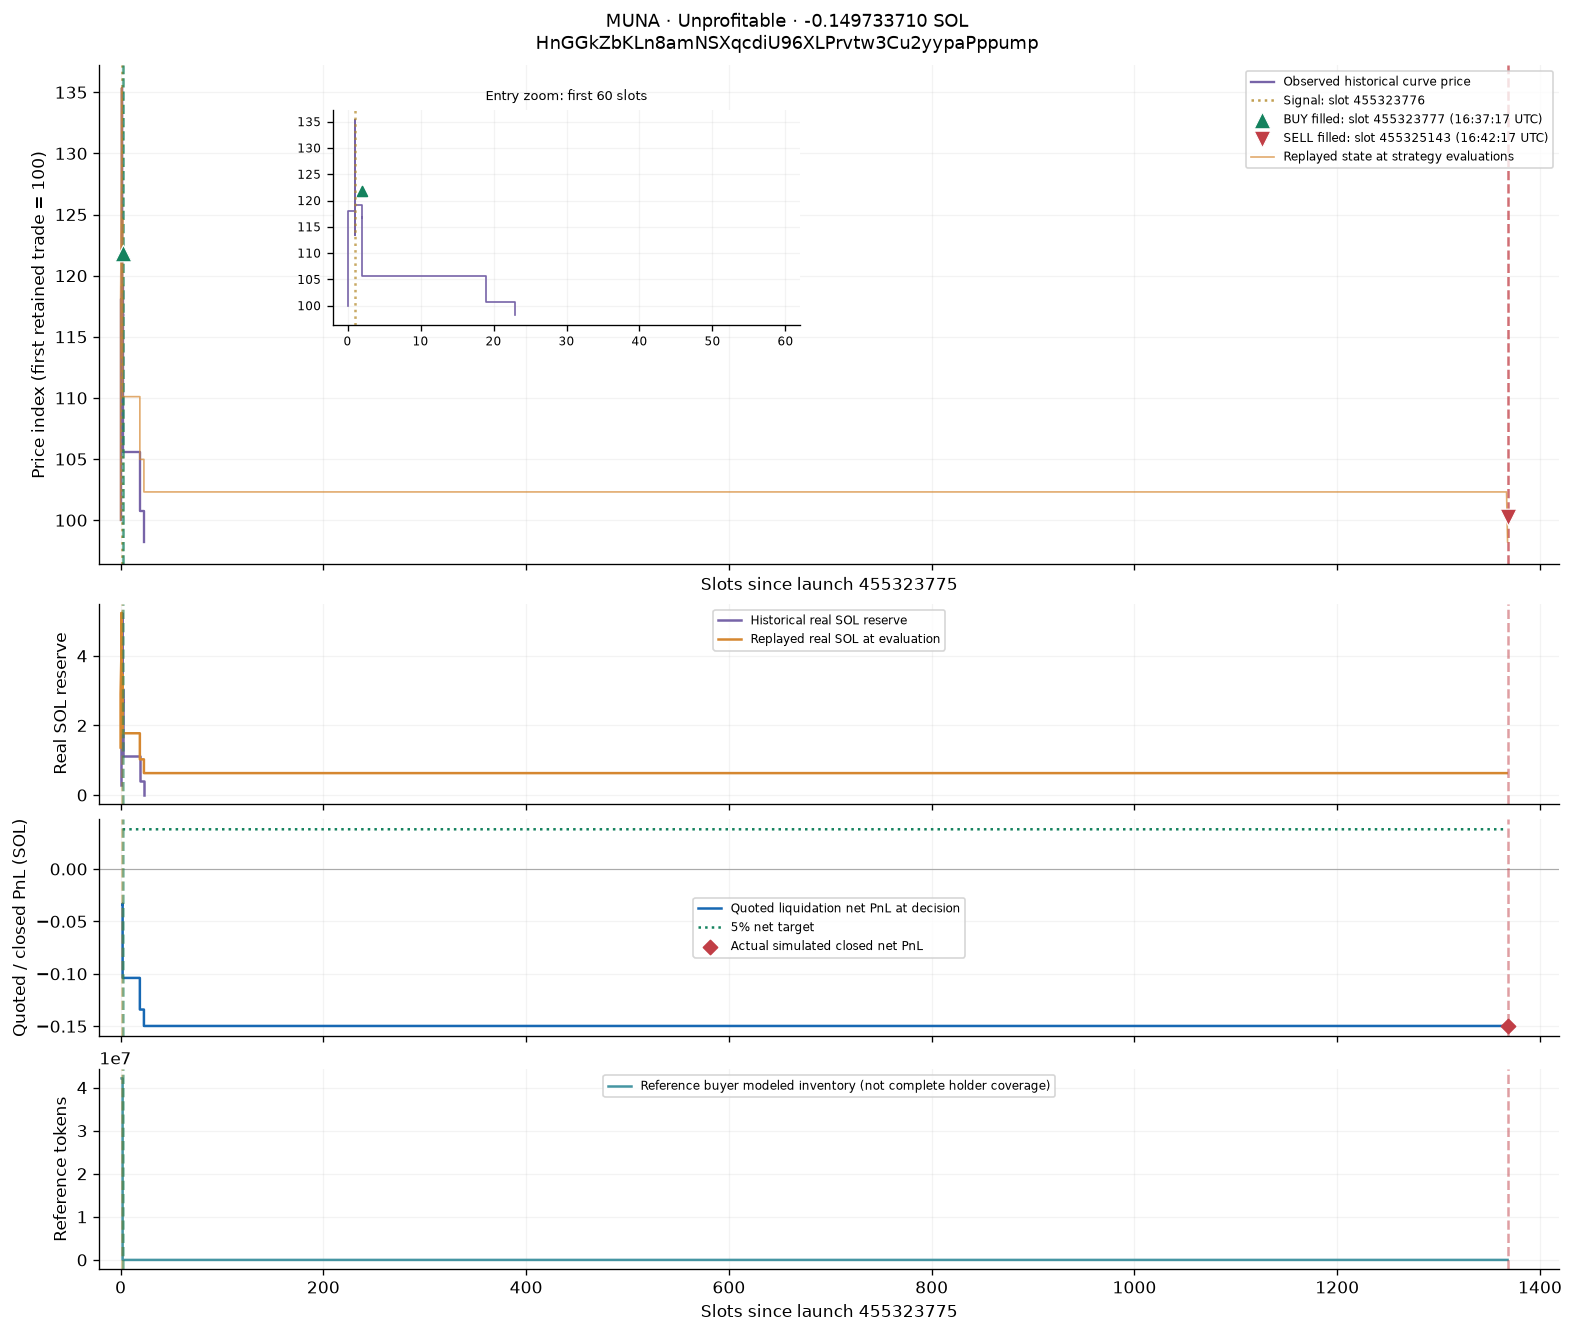

[GMGN token](https://gmgn.ai/sol/token/HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump) · [Reference buyer](https://gmgn.ai/sol/address/AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs) · [Creator](https://gmgn.ai/sol/address/CX2D2BDzRW7niVJMJYJ2H7PBKgTbkTmNQyjwt1x7r6oY)

,field,recorded_value
0,signal_slot,455323776
1,entry_slot,455323777
2,exit_signal_slot,455325142
3,exit_slot,455325143
4,reason,TIMEOUT
5,budget_lamports,757525420
6,entry_cash_sol,0.759669700
7,closed_pnl_sol,-0.149733710
8,sniper_trading_cash_cost_sol,1.500455000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump
symbol,MUNA
boundary_ordinal,1955600727011230829
slot,455323776
time,1791650236
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,2
virtual_sol,32804042291


**Exit decision**

,recorded_value
mint,HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump
symbol,MUNA
boundary_ordinal,1955606593936556032
slot,455325142
time,1791650537
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,2
virtual_sol,30630197820


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011229823,455323776,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,34984967043,920109484840456,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,0,4984967043,42147788944843,1500455000,1500455000,0,,,,,,,,,,,,,,,,,
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011229823,455323776,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,34984967043,920109484840456,Dc1HCbbFAhViEhrkHqm5k67rJShicSedz5pjyDF4JeE2,0,4984967043,36739990383007,1097686250,1097686250,0,,,,,,,,,,,,,,,,,
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011229823,455323776,1791650236,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,34984967043,920109484840456,,,,,,,,,,,,,,,,,,,,,,,,
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011229832,455323776,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,35231880622,913661134055620,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,0,5231880622,42147788944843,1500455000,1500455000,0,,,,,,,,,,,,,,,,,
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011229832,455323776,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,35231880622,913661134055620,Dc1HCbbFAhViEhrkHqm5k67rJShicSedz5pjyDF4JeE2,0,5231880622,36739990383007,1097686250,1097686250,0,,,,,,,,,,,,,,,,,
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011229832,455323776,1791650236,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,35231880622,913661134055620,,,,,,,,,,,,,,,,,,,,,,,,
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011230828,455323776,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,33869909427,950401124438627,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,0,3869909427,42147788944843,1500455000,1500455000,0,,,,,,,,,,,,,,,,,
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011230828,455323776,1791650236,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,33869909427,950401124438627,,,,,,,,,,,,,,,,,,,,,,,,
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011230829,455323776,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,32804042291,981281505449853,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,757525465,2804042291,42147788944843,1500455000,1500455000,0,,,,,,,,,,,,,,,,,
HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,MUNA,1955600727011230829,455323776,1791650236,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,2,32804042291,981281505449853,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,757525420,,42147788944843,1500455000,1500455000,0,34833793256.5595244514824589409736300176774854889326687022957,34832793239.2589776034689727261707182606367873559412970016986,1000000,33552215545,3552215545,21881373975985,748173254,20787305277185,,,,,,,,,


---

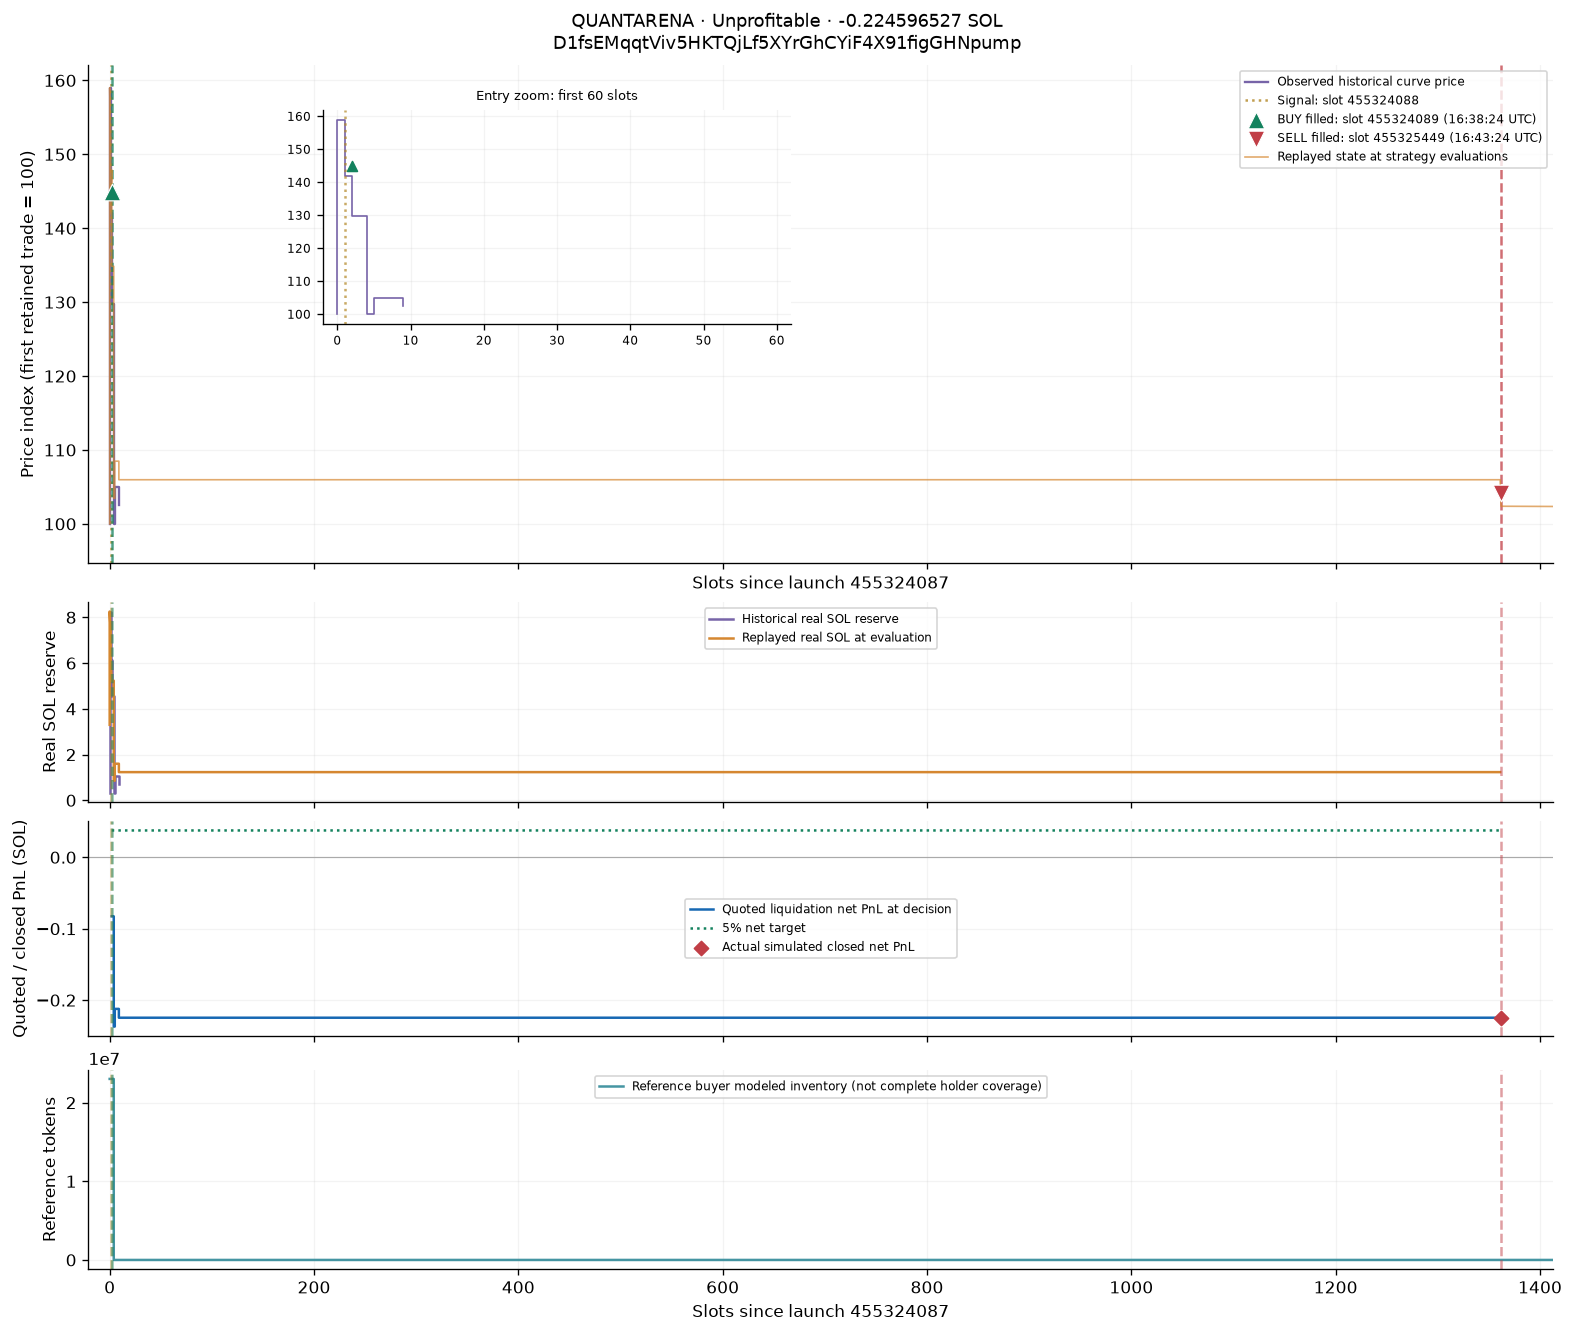

[GMGN token](https://gmgn.ai/sol/token/D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump) · [Reference buyer](https://gmgn.ai/sol/address/straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD) · [Creator](https://gmgn.ai/sol/address/EZVBDZxmqNm7jh9xeKu813Go8X1Ke3wsWP12cdPPz45h)

,field,recorded_value
0,signal_slot,455324088
1,entry_slot,455324089
2,exit_signal_slot,455325448
3,exit_slot,455325449
4,reason,TIMEOUT
5,budget_lamports,750701179
6,entry_cash_sol,0.752845459
7,closed_pnl_sol,-0.224596527
8,sniper_trading_cash_cost_sol,1.008505001
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump
symbol,QUANTARENA
boundary_ordinal,1955602067041026443
slot,455324088
time,1791650303
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,4
virtual_sol,36152930295


**Exit decision**

,recorded_value
mint,D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump
symbol,QUANTARENA
boundary_ordinal,1955607908196548608
slot,455325448
time,1791650604
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,4
virtual_sol,31232551359


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026150,455324088,1791650303,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,37417025364,860303556806506,,,,,,,,,,,,,,,,,,,,,,,,
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026307,455324088,1791650303,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36613522158,879183375664802,8ptvshQRZPRaRQBSCRxhHwbJFr6ktyUQ1SATDCLijkBW,0,6613522158,47606917636405,1919605000,1919605000,0,,,,,,,,,,,,,,,,,
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026307,455324088,1791650303,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36613522158,879183375664802,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,0,6613522158,41168691227203,1502855000,1502855000,0,,,,,,,,,,,,,,,,,
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026307,455324088,1791650303,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36613522158,879183375664802,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,6613522158,56639456574893,1377774513,1377774513,0,,,,,,,,,,,,,,,,,
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026307,455324088,1791650303,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36613522158,879183375664802,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,284893411,6613522158,23022785742728,1008505001,1008505001,0,,,,,,,,,,,,,,,,,
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026307,455324088,1791650303,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36613522158,879183375664802,,,,,,,,,,,,,,,,,,,,,,,,
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026443,455324088,1791650303,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36152930295,890384257760418,8ptvshQRZPRaRQBSCRxhHwbJFr6ktyUQ1SATDCLijkBW,0,6152930295,47606917636405,1919605000,1919605000,0,,,,,,,,,,,,,,,,,
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026443,455324088,1791650303,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36152930295,890384257760418,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,0,6152930295,41168691227203,1502855000,1502855000,0,,,,,,,,,,,,,,,,,
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026443,455324088,1791650303,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36152930295,890384257760418,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,6152930295,56639456574893,1377774513,1377774513,0,,,,,,,,,,,,,,,,,
D1fsEMqqtViv5HKTQjLf5XYrGhCYiF4X91figGHNpump,QUANTARENA,1955602067041026443,455324088,1791650303,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,36152930295,890384257760418,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,750701213,6152930295,23022785742728,1008505001,1008505001,0,,,,,,,,,,,,,,,,,


---

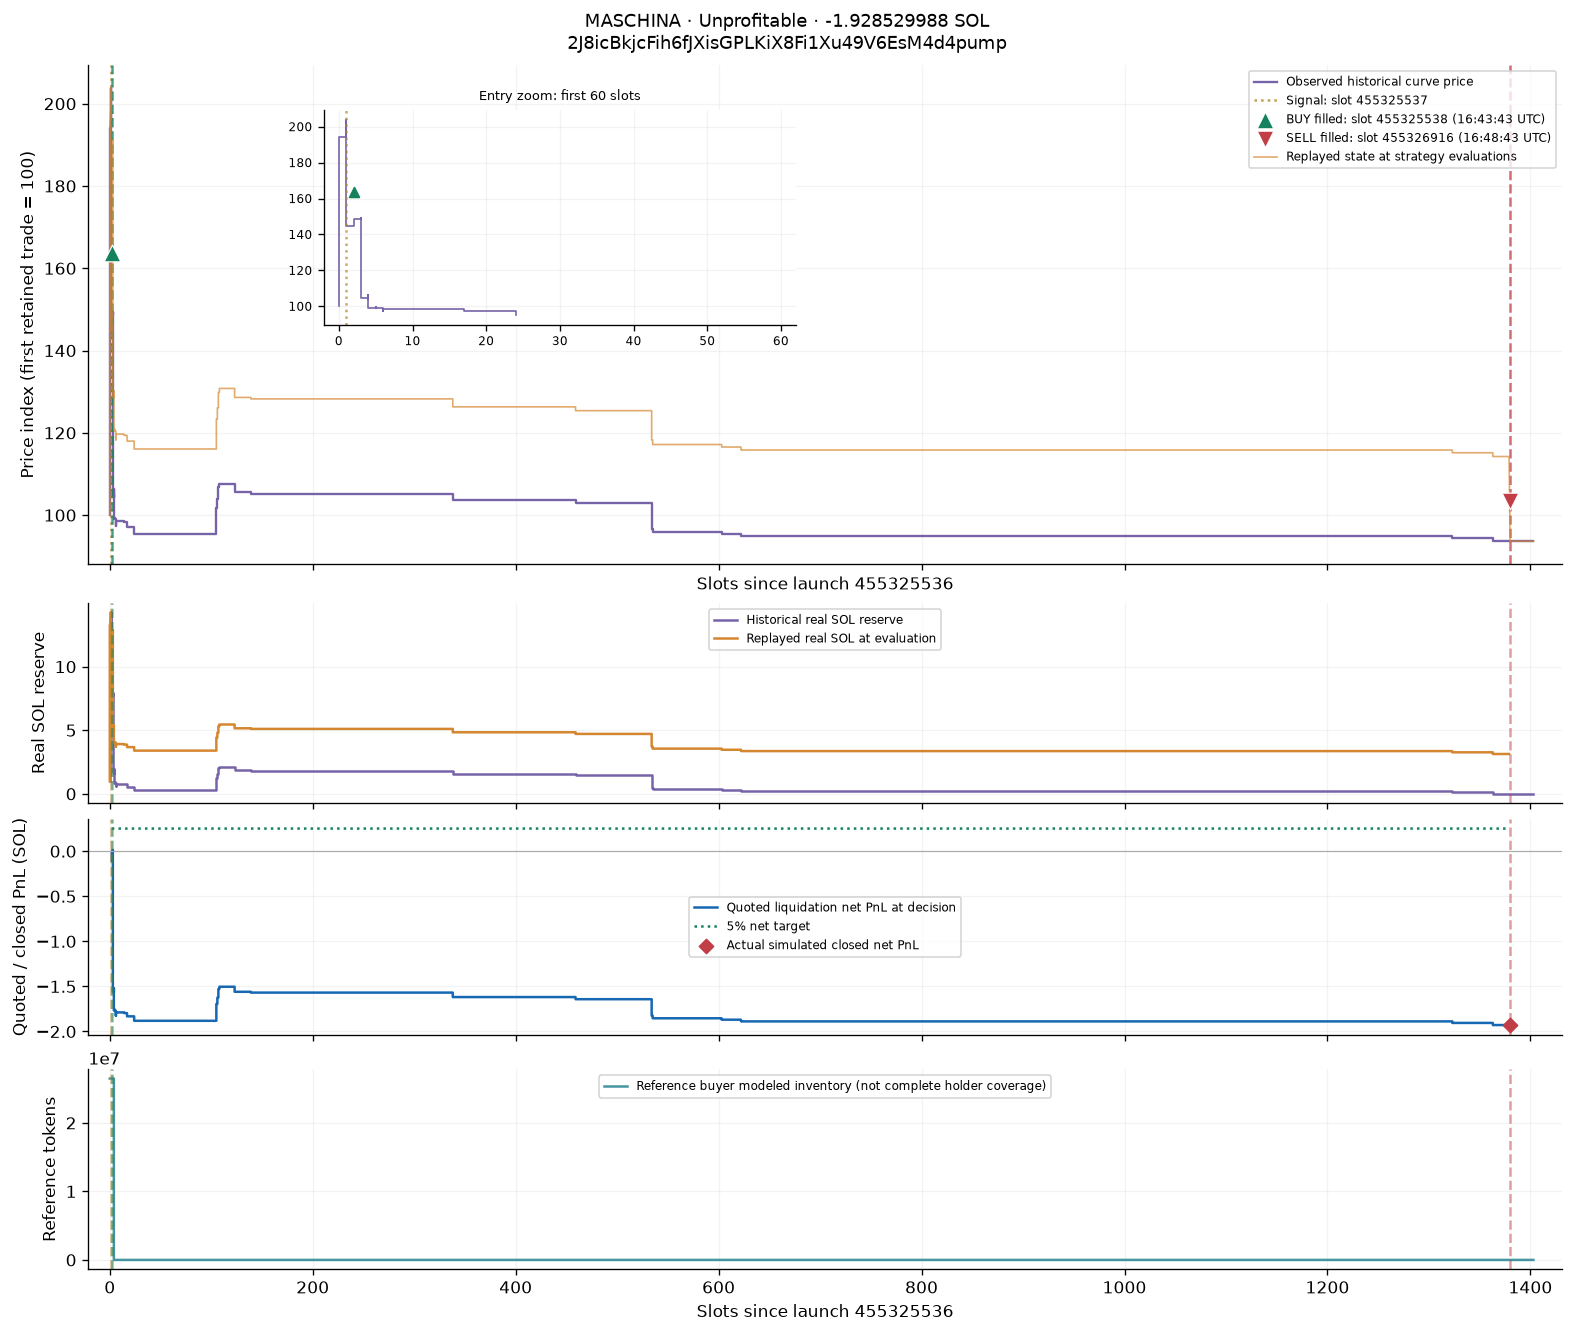

[GMGN token](https://gmgn.ai/sol/token/2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump) · [Reference buyer](https://gmgn.ai/sol/address/DL11CHBXbMMAfB3WEc1MaXqNBbVnWjuPVCzUjEwsPLv4) · [Creator](https://gmgn.ai/sol/address/DDHyHohSLW1ZBB5wNj7YpJiwDaKYG95cNiEPLmcyTMDy)

,field,recorded_value
0,signal_slot,455325537
1,entry_slot,455325538
2,exit_signal_slot,455326915
3,exit_slot,455326916
4,reason,TIMEOUT
5,budget_lamports,5023151970
6,entry_cash_sol,5.025296250
7,closed_pnl_sol,-1.928529988
8,sniper_trading_cash_cost_sol,1.511705000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump
symbol,MASCHINA
boundary_ordinal,1955608290448638283
slot,455325537
time,1791650623
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,7
virtual_sol,37264728495


**Exit decision**

,recorded_value
mint,2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump
symbol,MASCHINA
boundary_ordinal,1955614208913571840
slot,455326915
time,1791650923
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,7
virtual_sol,33134007103


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638217,455325537,1791650623,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,44113581031,729707252301847,,,,,,,,,,,,,,,,,,,,,,,,
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638218,455325537,1791650623,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,44261729178,727264853901212,5MmBG7LnNDdnWwMFCCZLnPxtNEZoz3uRbrADFVdwUreQ,0,14261729178,136554669401349,5578985000,5578985000,0,,,,,,,,,,,,,,,,,
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638218,455325537,1791650623,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,44261729178,727264853901212,DL11CHBXbMMAfB3WEc1MaXqNBbVnWjuPVCzUjEwsPLv4,0,14261729178,26471522027986,1511705000,1511705000,0,,,,,,,,,,,,,,,,,
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638218,455325537,1791650623,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,44261729178,727264853901212,6LVuF6wjpLVeqdJq36bD6hYG2aQuVUSfTXWRdJDBHJyg,0,14261729178,28391770098247,1498605000,1498605000,0,,,,,,,,,,,,,,,,,
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638218,455325537,1791650623,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,44261729178,727264853901212,2ni5TVzyzEvKmrKY4bQqE1F2nStEdwpjvMsiyMh5APa1,0,14261729178,27357284304196,1346625000,1346625000,0,,,,,,,,,,,,,,,,,
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638218,455325537,1791650623,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,44261729178,727264853901212,E4mmLv7MugAQoJvqbzVSRTzn6LRWtsAQgX5dYze7WzCy,0,14261729178,39937965260545,1255610000,1255610000,0,,,,,,,,,,,,,,,,,
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638218,455325537,1791650623,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,44261729178,727264853901212,6PwLMU3aTi2SGjnP5iRkxAW4VBgEdjwYdC8D7Sv3afok,0,14261729178,34388035377079,1164375000,1164375000,0,,,,,,,,,,,,,,,,,
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638218,455325537,1791650623,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,44261729178,727264853901212,DDHyHohSLW1ZBB5wNj7YpJiwDaKYG95cNiEPLmcyTMDy,0,14261729178,34612903225806,1012610000,969824810,42785190,,,,,,,,,,,,,,,,,
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638218,455325537,1791650623,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,44261729178,727264853901212,,,,,,,,,,,,,,,,,,,,,,,,
2J8icBkjcFih6fJXisGPLKiX8Fi1Xu49V6EsM4d4pump,MASCHINA,1955608290448638283,455325537,1791650623,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,7,37264728495,863819523302561,DL11CHBXbMMAfB3WEc1MaXqNBbVnWjuPVCzUjEwsPLv4,5023151979,7264728495,26471522027986,1511705000,1511705000,0,,,,,,,,,,,,,,,,,


---

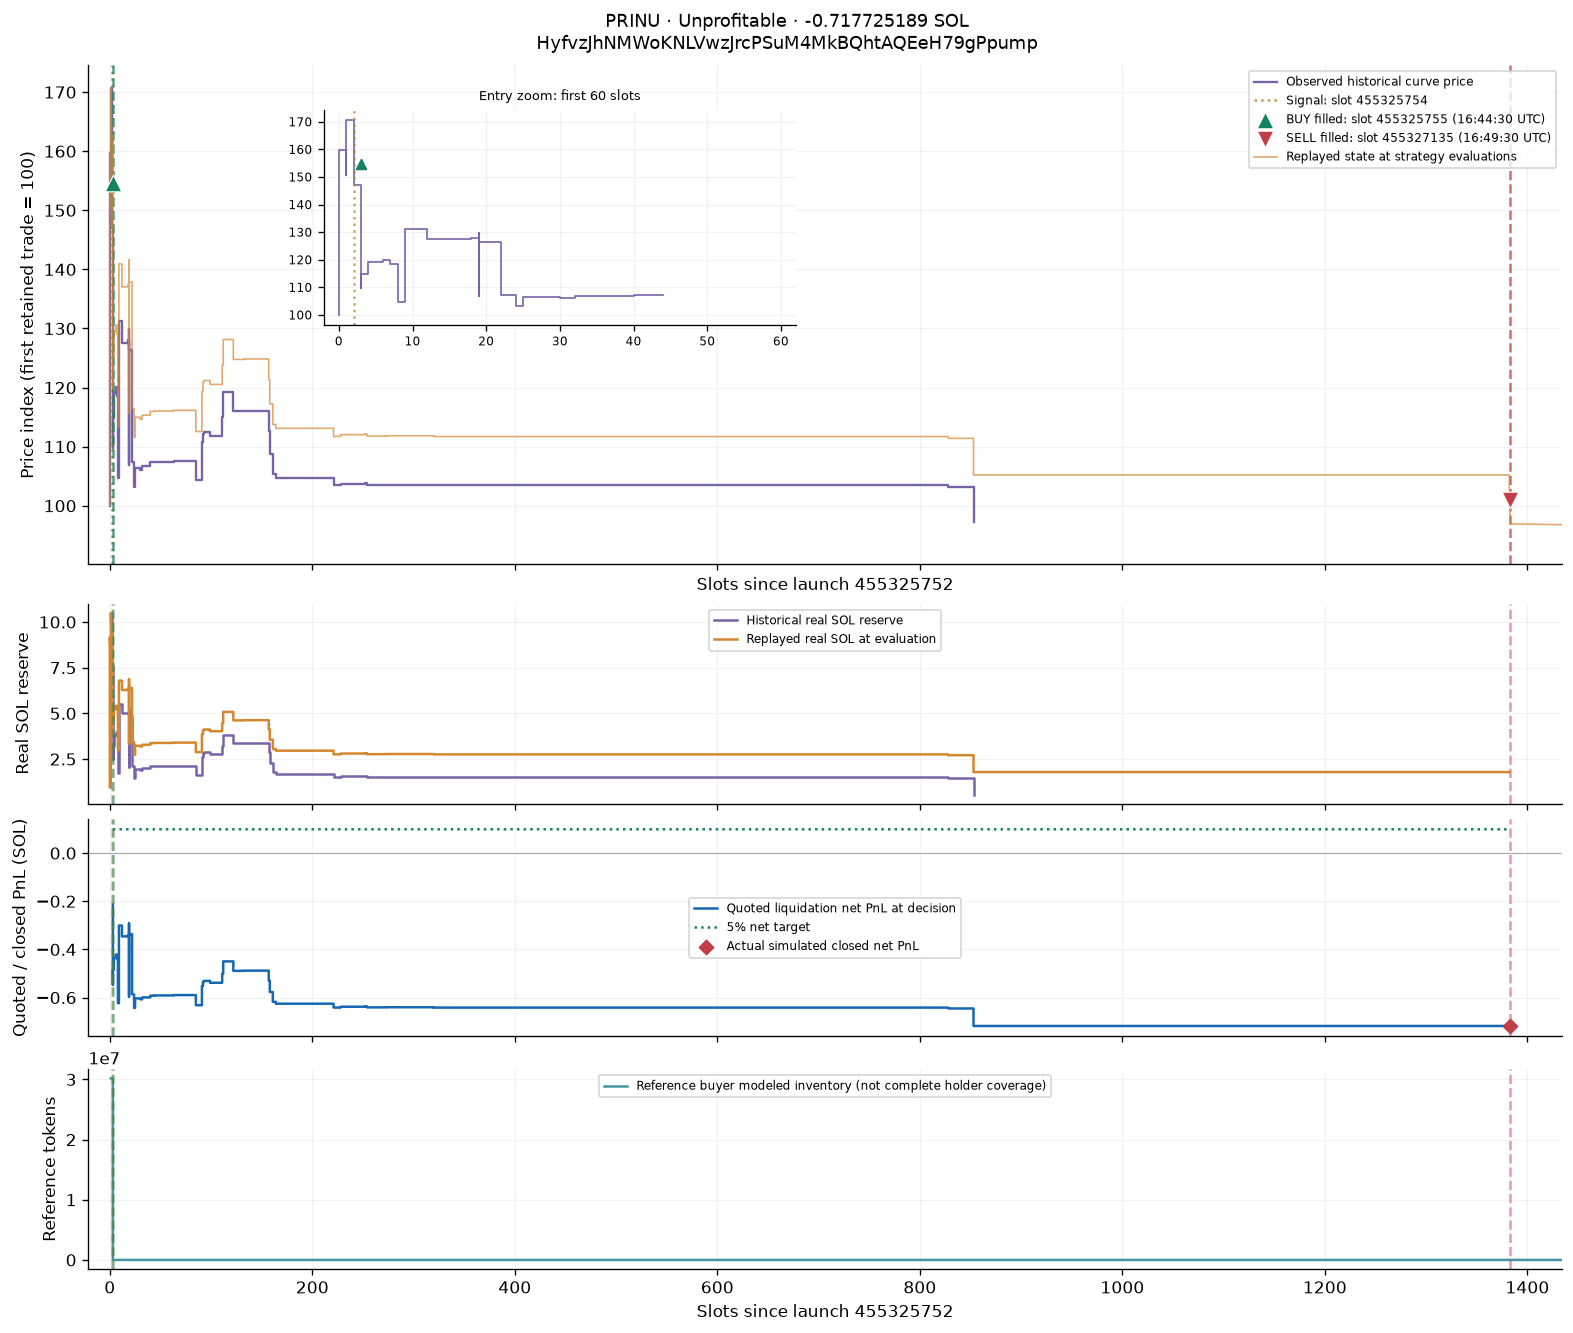

[GMGN token](https://gmgn.ai/sol/token/HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump) · [Reference buyer](https://gmgn.ai/sol/address/AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs) · [Creator](https://gmgn.ai/sol/address/AiUaaLhisTUx9gsthvyfD9P6aMJ8FEhxXEUMs1CUymv2)

,field,recorded_value
0,signal_slot,455325754
1,entry_slot,455325755
2,exit_signal_slot,455327134
3,exit_slot,455327135
4,reason,TIMEOUT
5,budget_lamports,1977297260
6,entry_cash_sol,1.979441540
7,closed_pnl_sol,-0.717725189
8,sniper_trading_cash_cost_sol,1.502705000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump
symbol,PRINU
boundary_ordinal,1955609222456542140
slot,455325754
time,1791650670
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,6
virtual_sol,37570818837


**Exit decision**

,recorded_value
mint,HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump
symbol,PRINU
boundary_ordinal,1955615149511409664
slot,455327134
time,1791650970
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,6
virtual_sol,31789862559


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609222456542004,455325754,1791650670,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,39139771197,822437102301763,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,411177911,9139771197,30185995246216,1502705000,1502705000,0,,,,,,,,,,,,,,,,,
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609222456542004,455325754,1791650670,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,39139771197,822437102301763,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,0,9139771197,37956858462824,1500480000,1500480000,0,,,,,,,,,,,,,,,,,
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609222456542004,455325754,1791650670,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,39139771197,822437102301763,AiUaaLhisTUx9gsthvyfD9P6aMJ8FEhxXEUMs1CUymv2,0,9139771197,34344863190501,1004592003,962479608,42112395,,,,,,,,,,,,,,,,,
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609222456542004,455325754,1791650670,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,39139771197,822437102301763,,,,,,,,,,,,,,,,,,,,,,,,
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609222456542140,455325754,1791650670,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,37570818837,856781965492264,2mqrindMAjJEQPLhroYWyiYPo5h9iAsahfdd4QtsjwdY,0,7570818837,61321818380227,2230005000,2230005000,0,,,,,,,,,,,,,,,,,
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609222456542140,455325754,1791650670,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,37570818837,856781965492264,t9bNZ4KrFejJkKeHba8jKxrDU5xjSUH5WYFbBzzYJUQ,653749387,7570818837,43673127670309,2001005000,2001005000,0,,,,,,,,,,,,,,,,,
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609222456542140,455325754,1791650670,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,37570818837,856781965492264,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,1977297284,7570818837,30185995246216,1502705000,1502705000,0,,,,,,,,,,,,,,,,,
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609222456542140,455325754,1791650670,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,6,37570818837,856781965492264,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,1977297260,,30185995246216,1502705000,1502705000,0,41051441992.0934989011946816610856214780324095247479572935892,41050441982.9034175798904264748343455762694919010531587762490,1000000,39523705019,9523705019,42334028648828,1952886182,40217327216386,,,,,,,,,
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609222456542140,455325754,1791650670,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,6,37570818837,856781965492264,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,,30185995246216,1502705000,1502705000,0,,,,,,,,,BUY,f263cb061805c714933444fb5bbc35d2f0a3c7df0b3429fb175e45766c222964,[],0,,,,,
HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,PRINU,1955609226751508480,455325755,1791650670,ORDER_FILLED,PENDING_BUY,SIGNAL,6,39523705019,814447936843436,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,,,30185995246216,1502705000,1502705000,0,,,,,,,,,BUY,f263cb061805c714933444fb5bbc35d2f0a3c7df0b3429fb175e45766c222964,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,


---

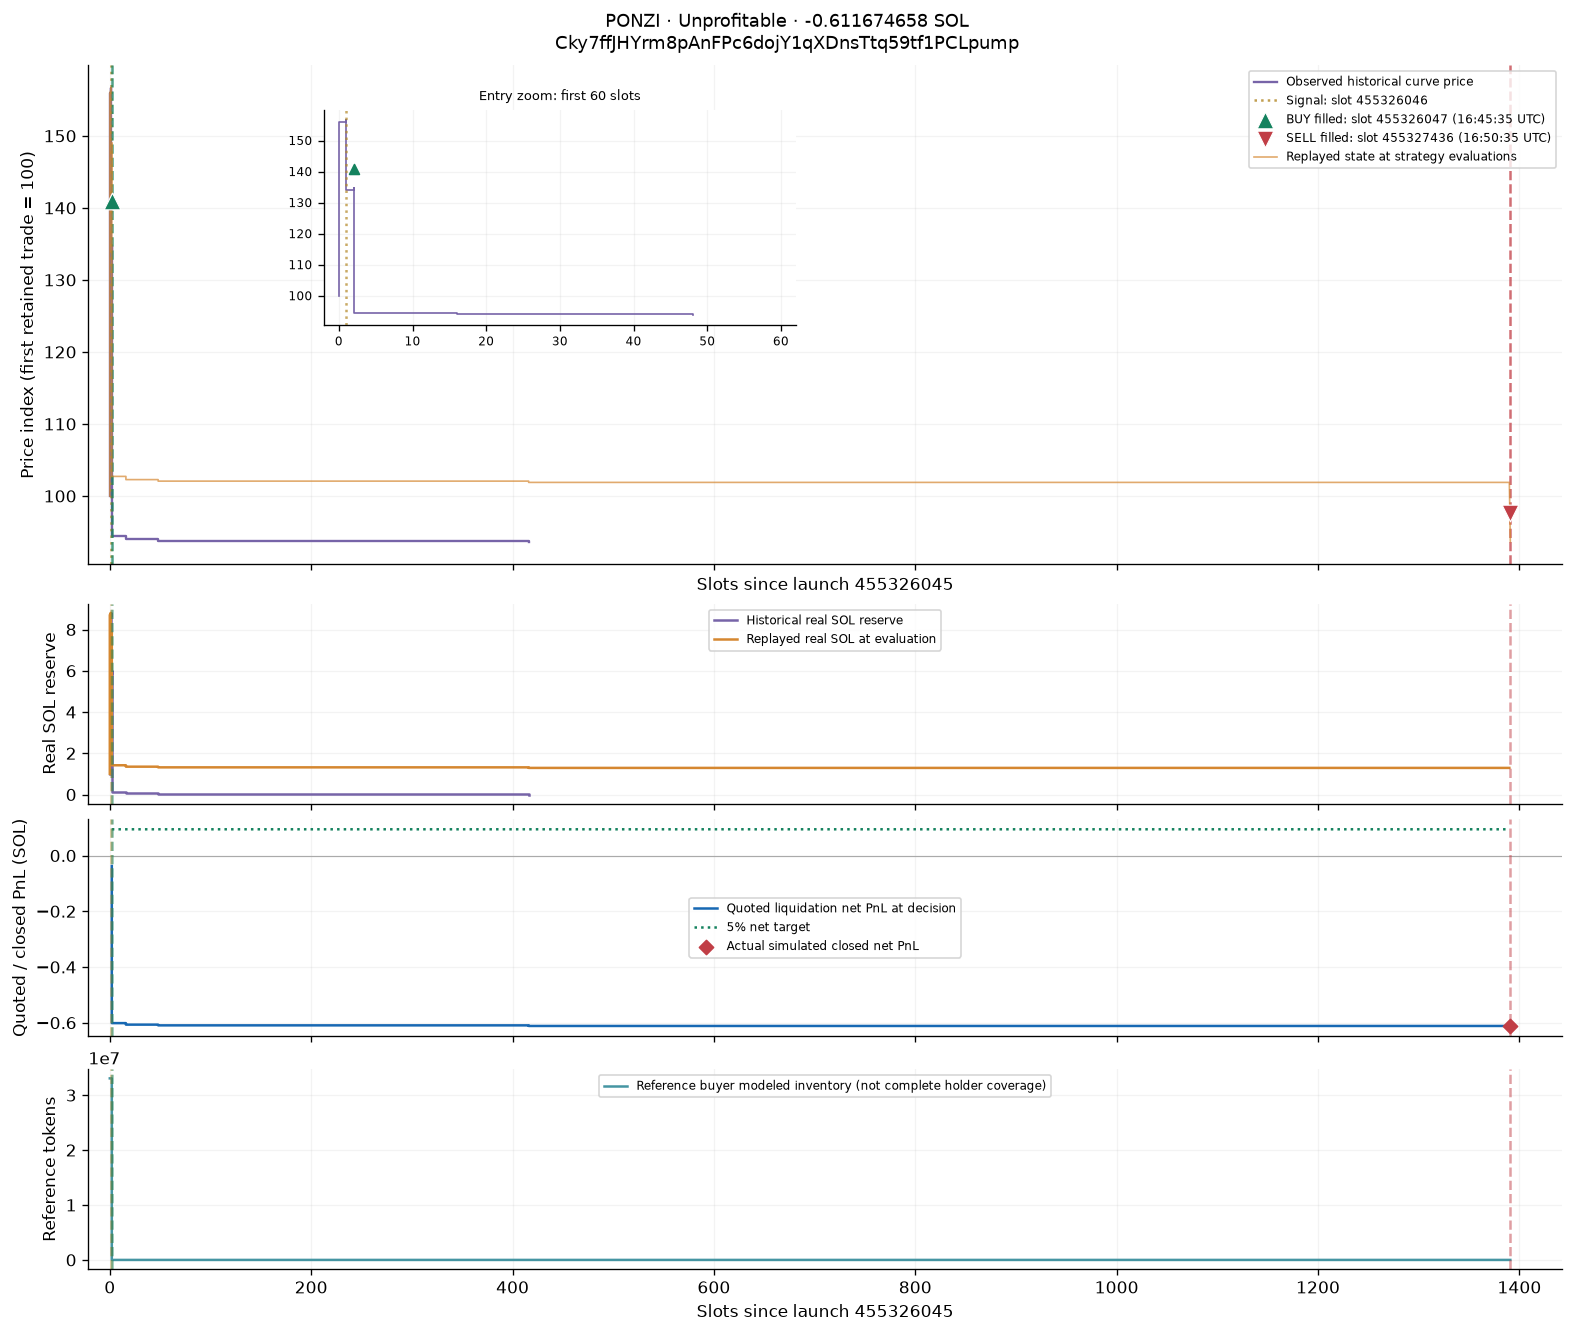

[GMGN token](https://gmgn.ai/sol/token/Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump) · [Reference buyer](https://gmgn.ai/sol/address/6LVuF6wjpLVeqdJq36bD6hYG2aQuVUSfTXWRdJDBHJyg) · [Creator](https://gmgn.ai/sol/address/6uB8XPXRzsDTGFDUGm3xqUrQi2L6PpRaZTYppXHNtX78)

,field,recorded_value
0,signal_slot,455326046
1,entry_slot,455326047
2,exit_signal_slot,455327435
3,exit_slot,455327436
4,reason,TIMEOUT
5,budget_lamports,1886482238
6,entry_cash_sol,1.888626518
7,closed_pnl_sol,-0.611674658
8,sniper_trading_cash_cost_sol,1.498605000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump
symbol,PONZI
boundary_ordinal,1955610476586992046
slot,455326046
time,1791650735
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,6
virtual_sol,35885524682


**Exit decision**

,recorded_value
mint,Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump
symbol,PONZI
boundary_ordinal,1955616442296565760
slot,455327435
time,1791651035
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,6
virtual_sol,31291157051


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991842,455326046,1791650735,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38759382715,830508582593422,6PwLMU3aTi2SGjnP5iRkxAW4VBgEdjwYdC8D7Sv3afok,0,8759382715,34388035377079,1164375000,1164375000,0,,,,,,,,,,,,,,,,,
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991842,455326046,1791650735,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38759382715,830508582593422,6uB8XPXRzsDTGFDUGm3xqUrQi2L6PpRaZTYppXHNtX78,0,8759382715,34612903225806,1012610000,986331851,26278149,,,,,,,,,,,,,,,,,
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991842,455326046,1791650735,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38759382715,830508582593422,,,,,,,,,,,,,,,,,,,,,,,,
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991857,455326046,1791650735,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38801113988,829615356181538,5MmBG7LnNDdnWwMFCCZLnPxtNEZoz3uRbrADFVdwUreQ,0,8801113988,67403714520969,2541485000,2541485000,0,,,,,,,,,,,,,,,,,
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991857,455326046,1791650735,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38801113988,829615356181538,6LVuF6wjpLVeqdJq36bD6hYG2aQuVUSfTXWRdJDBHJyg,0,8801113988,33057231909583,1498605000,1498605000,0,,,,,,,,,,,,,,,,,
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991857,455326046,1791650735,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38801113988,829615356181538,2ni5TVzyzEvKmrKY4bQqE1F2nStEdwpjvMsiyMh5APa1,0,8801113988,32032079439934,1346625000,1346625000,0,,,,,,,,,,,,,,,,,
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991857,455326046,1791650735,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38801113988,829615356181538,E4mmLv7MugAQoJvqbzVSRTzn6LRWtsAQgX5dYze7WzCy,0,8801113988,39937965260545,1255610000,1255610000,0,,,,,,,,,,,,,,,,,
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991857,455326046,1791650735,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38801113988,829615356181538,6PwLMU3aTi2SGjnP5iRkxAW4VBgEdjwYdC8D7Sv3afok,0,8801113988,34388035377079,1164375000,1164375000,0,,,,,,,,,,,,,,,,,
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991857,455326046,1791650735,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38801113988,829615356181538,6uB8XPXRzsDTGFDUGm3xqUrQi2L6PpRaZTYppXHNtX78,0,8801113988,34612903225806,1012610000,986206657,26403343,,,,,,,,,,,,,,,,,
Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,PONZI,1955610476586991857,455326046,1791650735,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,6,38801113988,829615356181538,,,,,,,,,,,,,,,,,,,,,,,,


---

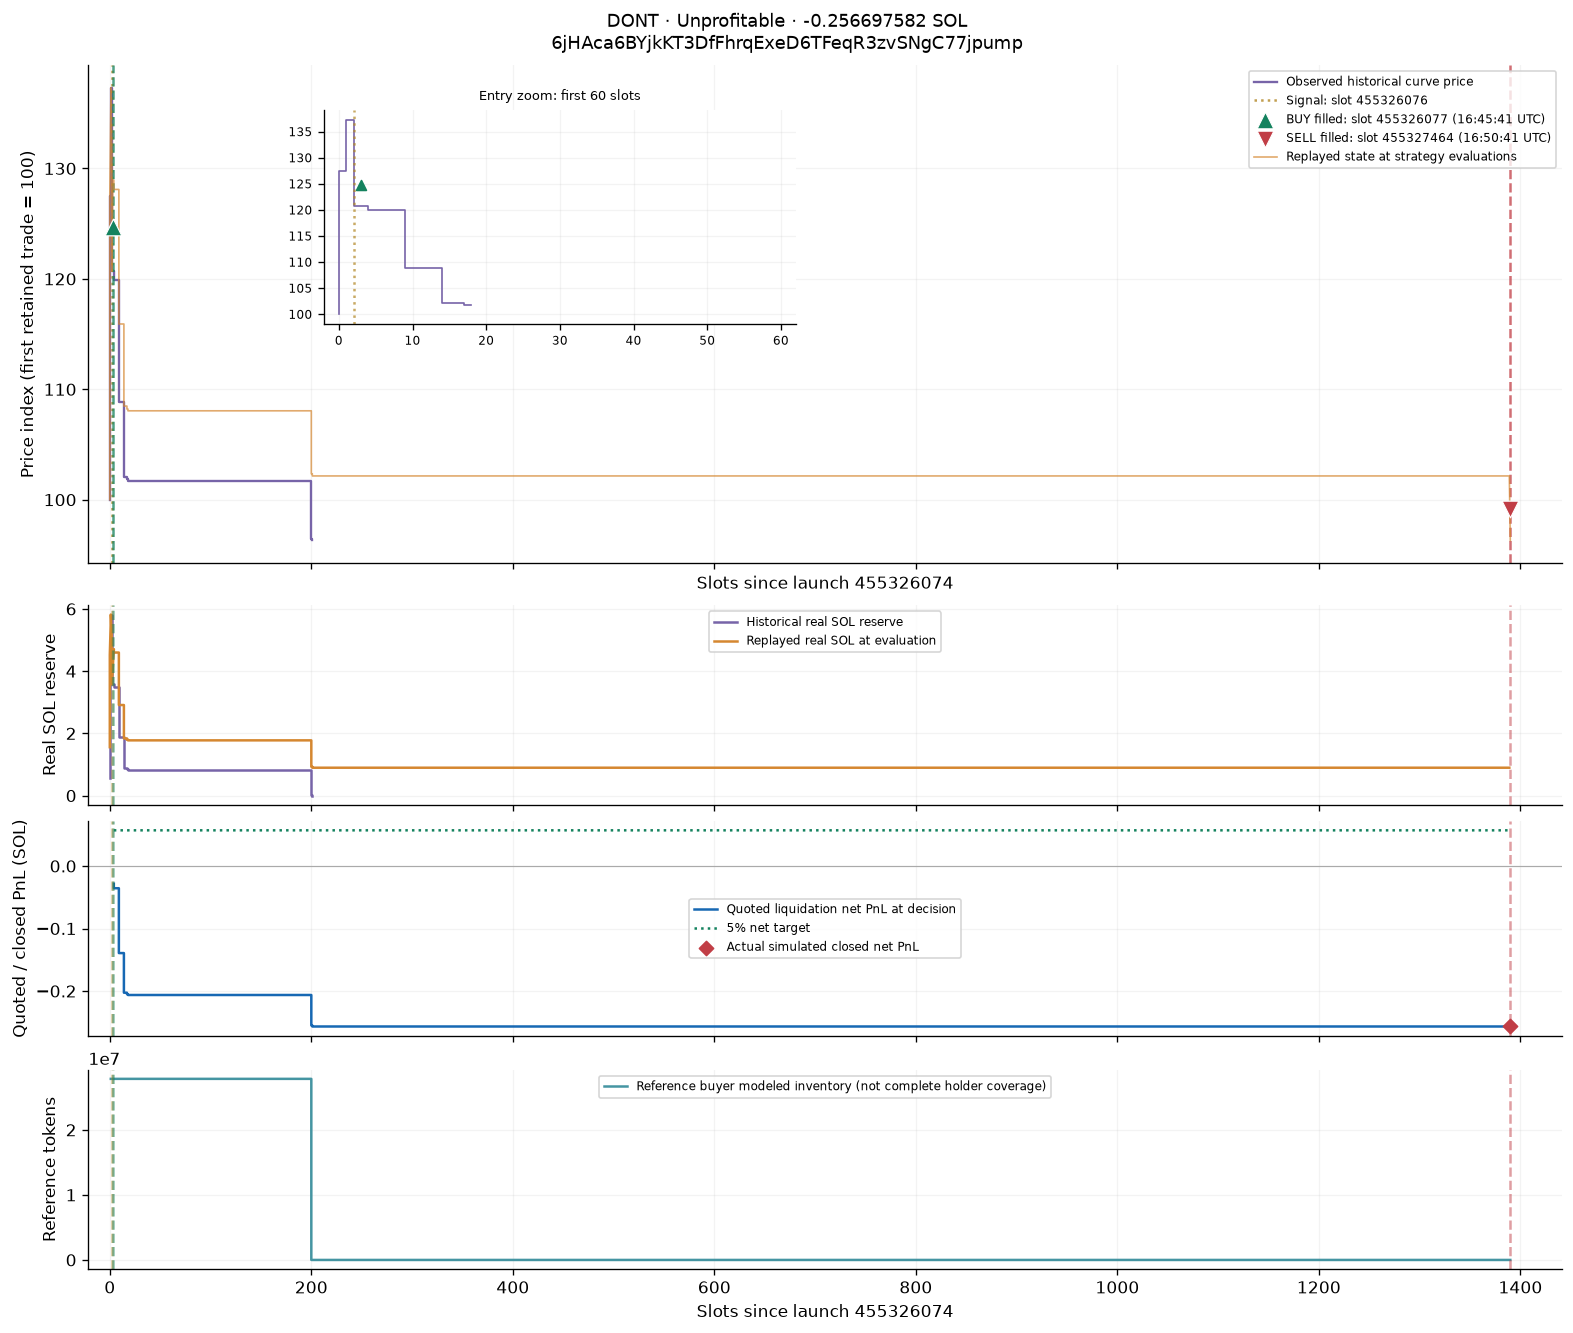

[GMGN token](https://gmgn.ai/sol/token/6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump) · [Reference buyer](https://gmgn.ai/sol/address/GRjqFrRcc5p5UU4KfB7EjHjLD2iBB67MFmcK5CHQ9Dja) · [Creator](https://gmgn.ai/sol/address/8hfHjjsqdDHoR9wotDuobnohgrozjZJRBpP4BiEieL97)

,field,recorded_value
0,signal_slot,455326076
1,entry_slot,455326077
2,exit_signal_slot,455327463
3,exit_slot,455327464
4,reason,TIMEOUT
5,budget_lamports,1142445300
6,entry_cash_sol,1.144589580
7,closed_pnl_sol,-0.256697582
8,sniper_trading_cash_cost_sol,1.076241384
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump
symbol,DONT
boundary_ordinal,1955610605436010796
slot,455326076
time,1791650741
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,3
virtual_sol,33583534480


**Exit decision**

,recorded_value
mint,6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump
symbol,DONT
boundary_ordinal,1955616562555650048
slot,455327463
time,1791651041
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,3
virtual_sol,30897172387


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610601141043943,455326075,1791650741,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35781527186,899626218815159,,,,,,,,,,,,,,,,,,,,,,,,
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610601141043986,455326075,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35821033358,898634042322584,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,5821033358,87552627736117,3000005087,3000005087,0,,,,,,,,,,,,,,,,,
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610601141043986,455326075,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35821033358,898634042322584,GRjqFrRcc5p5UU4KfB7EjHjLD2iBB67MFmcK5CHQ9Dja,0,5821033358,27847242060718,1076241384,1076241384,0,,,,,,,,,,,,,,,,,
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610601141043986,455326075,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35821033358,898634042322584,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,0,5821033358,32955762800425,1001580000,1001580000,0,,,,,,,,,,,,,,,,,
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610601141043986,455326075,1791650741,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35821033358,898634042322584,,,,,,,,,,,,,,,,,,,,,,,,
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610605436010700,455326076,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35041157332,918634042322584,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,5041157332,87552627736117,3000005087,3000005087,0,,,,,,,,,,,,,,,,,
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610605436010700,455326076,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35041157332,918634042322584,GRjqFrRcc5p5UU4KfB7EjHjLD2iBB67MFmcK5CHQ9Dja,0,5041157332,27847242060718,1076241384,1076241384,0,,,,,,,,,,,,,,,,,
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610605436010700,455326076,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35041157332,918634042322584,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,0,5041157332,32955762800425,1001580000,1001580000,0,,,,,,,,,,,,,,,,,
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610605436010700,455326076,1791650741,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,35041157332,918634042322584,,,,,,,,,,,,,,,,,,,,,,,,
6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,DONT,1955610605436010796,455326076,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,3,33583534480,958505425548147,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,0,3583534480,47681244510554,1560891322,1560891322,0,,,,,,,,,,,,,,,,,


---

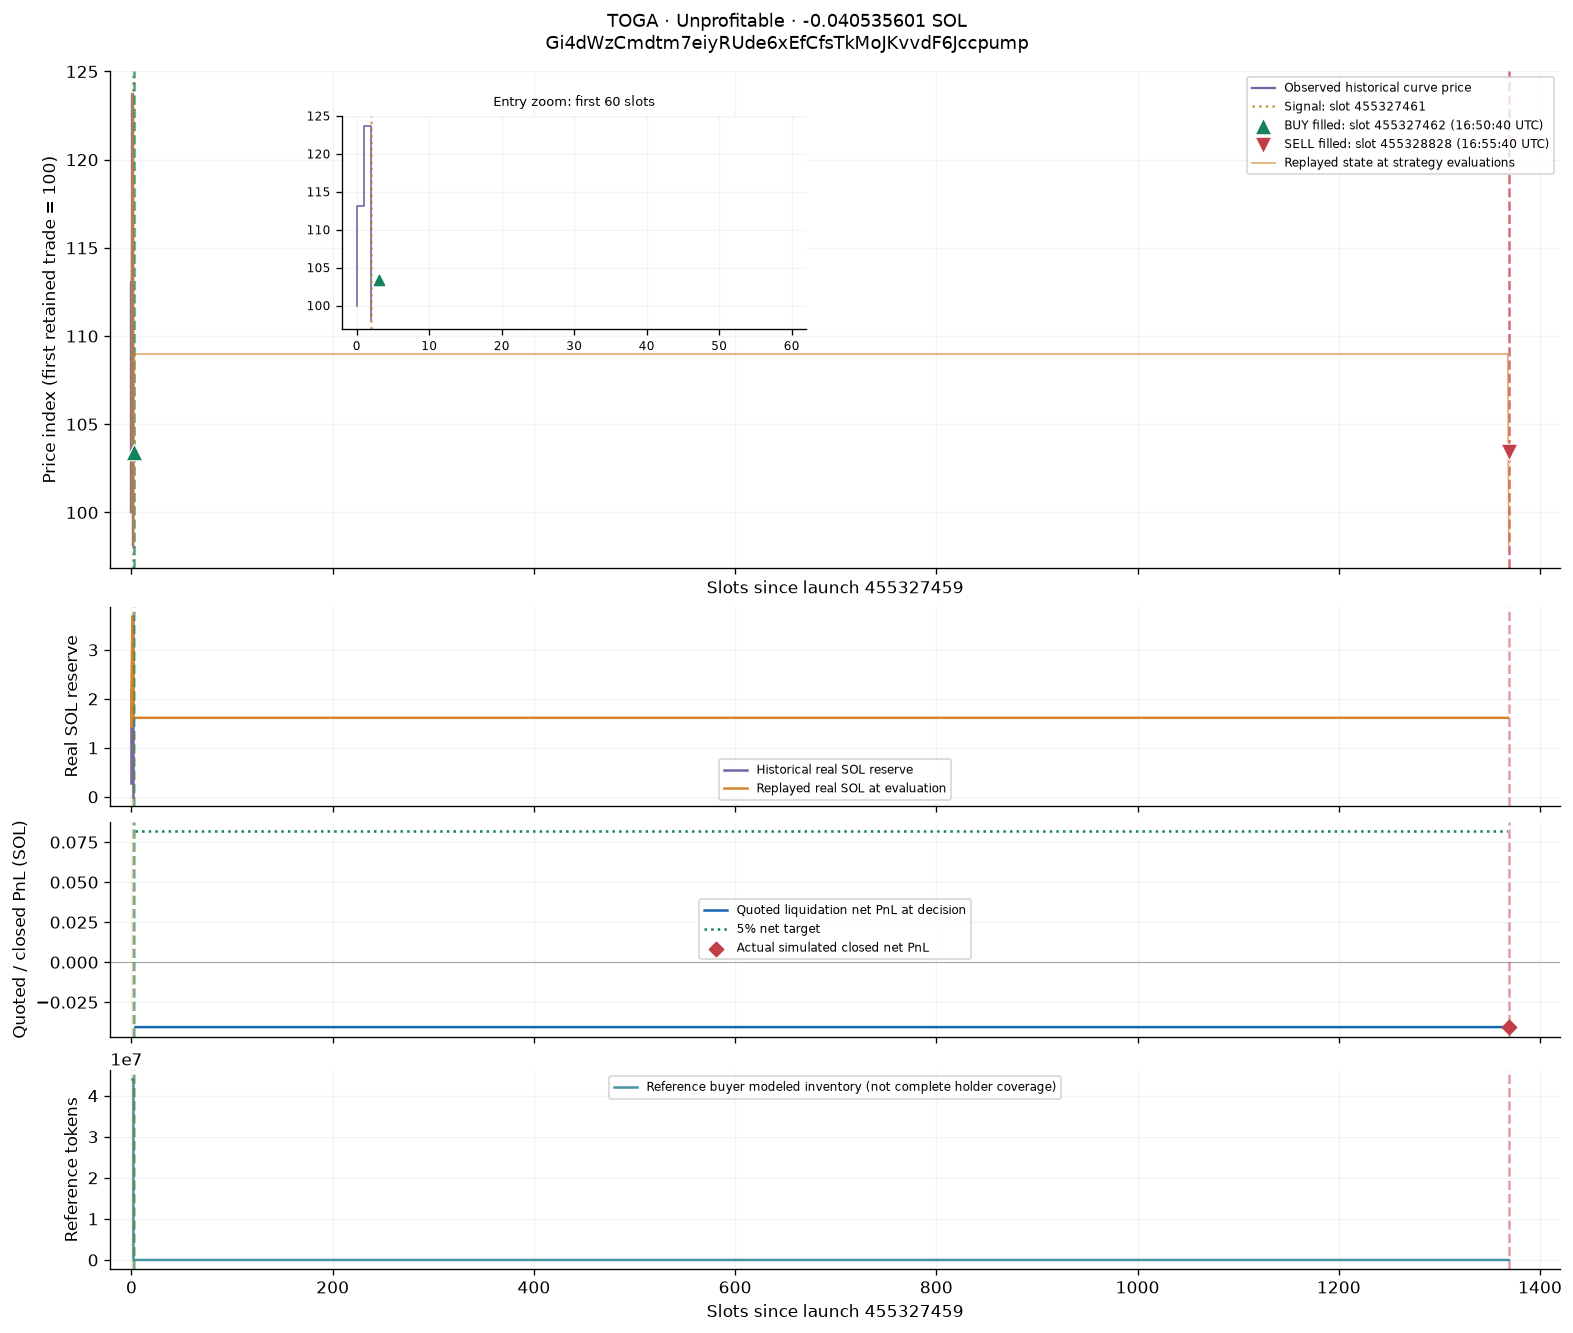

[GMGN token](https://gmgn.ai/sol/token/Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump) · [Reference buyer](https://gmgn.ai/sol/address/BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL) · [Creator](https://gmgn.ai/sol/address/G6qdcaPU7b73L2Hi5X8R5PhArEYoHySbdTaK2hpcP2H5)

,field,recorded_value
0,signal_slot,455327461
1,entry_slot,455327462
2,exit_signal_slot,455328827
3,exit_slot,455328828
4,reason,TIMEOUT
5,budget_lamports,1633186780
6,entry_cash_sol,1.635331060
7,closed_pnl_sol,-0.040535601
8,sniper_trading_cash_cost_sol,1.531705000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump
symbol,TOGA
boundary_ordinal,1955616553965715627
slot,455327461
time,1791651040
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,2
virtual_sol,31588640269


**Exit decision**

,recorded_value
mint,Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump
symbol,TOGA
boundary_ordinal,1955622420891041792
slot,455328827
time,1791651340
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,2
virtual_sol,31613023983


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616545375781899,455327459,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,1,32203220132,999589477958111,7CBxH6uV3z7rLjQ8977VLzSJNMLQtZcmvbHv9PsfhLNc,0,2203220132,39012158538716,1168156250,1168156250,0,,,,,,,,,,,,,,,,,
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616545375781899,455327459,1791651040,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,1,32203220132,999589477958111,,,,,,,,,,,,,,,,,,,,,,,,
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616549670748361,455327460,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,33684701612,955626692854662,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,0,3684701612,43962785103449,1531705000,1531705000,0,,,,,,,,,,,,,,,,,
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616549670748361,455327460,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,33684701612,955626692854662,7CBxH6uV3z7rLjQ8977VLzSJNMLQtZcmvbHv9PsfhLNc,0,3684701612,39012158538716,1168156250,1168156250,0,,,,,,,,,,,,,,,,,
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616549670748361,455327460,1791651040,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,33684701612,955626692854662,,,,,,,,,,,,,,,,,,,,,,,,
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616553965715619,455327461,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,32846098978,980025056357835,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,377323650,2846098978,43962785103449,1531705000,1531705000,0,,,,,,,,,,,,,,,,,
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616553965715619,455327461,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,32846098978,980025056357835,7CBxH6uV3z7rLjQ8977VLzSJNMLQtZcmvbHv9PsfhLNc,0,2846098978,39012158538716,1168156250,1168156250,0,,,,,,,,,,,,,,,,,
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616553965715619,455327461,1791651040,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,32846098978,980025056357835,,,,,,,,,,,,,,,,,,,,,,,,
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616553965715627,455327461,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,31588640269,1019037214896551,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,1633186795,1588640269,43962785103449,1531705000,1531705000,0,,,,,,,,,,,,,,,,,
Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,TOGA,1955616553965715627,455327461,1791651040,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,2,31588640269,1019037214896551,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,1633186780,,43962785103449,1531705000,1531705000,0,34485012739.1318786172868071677635655650770652342846686054764,34484012735.6573125740993528558171192878696175147273676798999,1000000,33201664249,3201664249,49507502119280,1613023980,47032127013316,,,,,,,,,


---

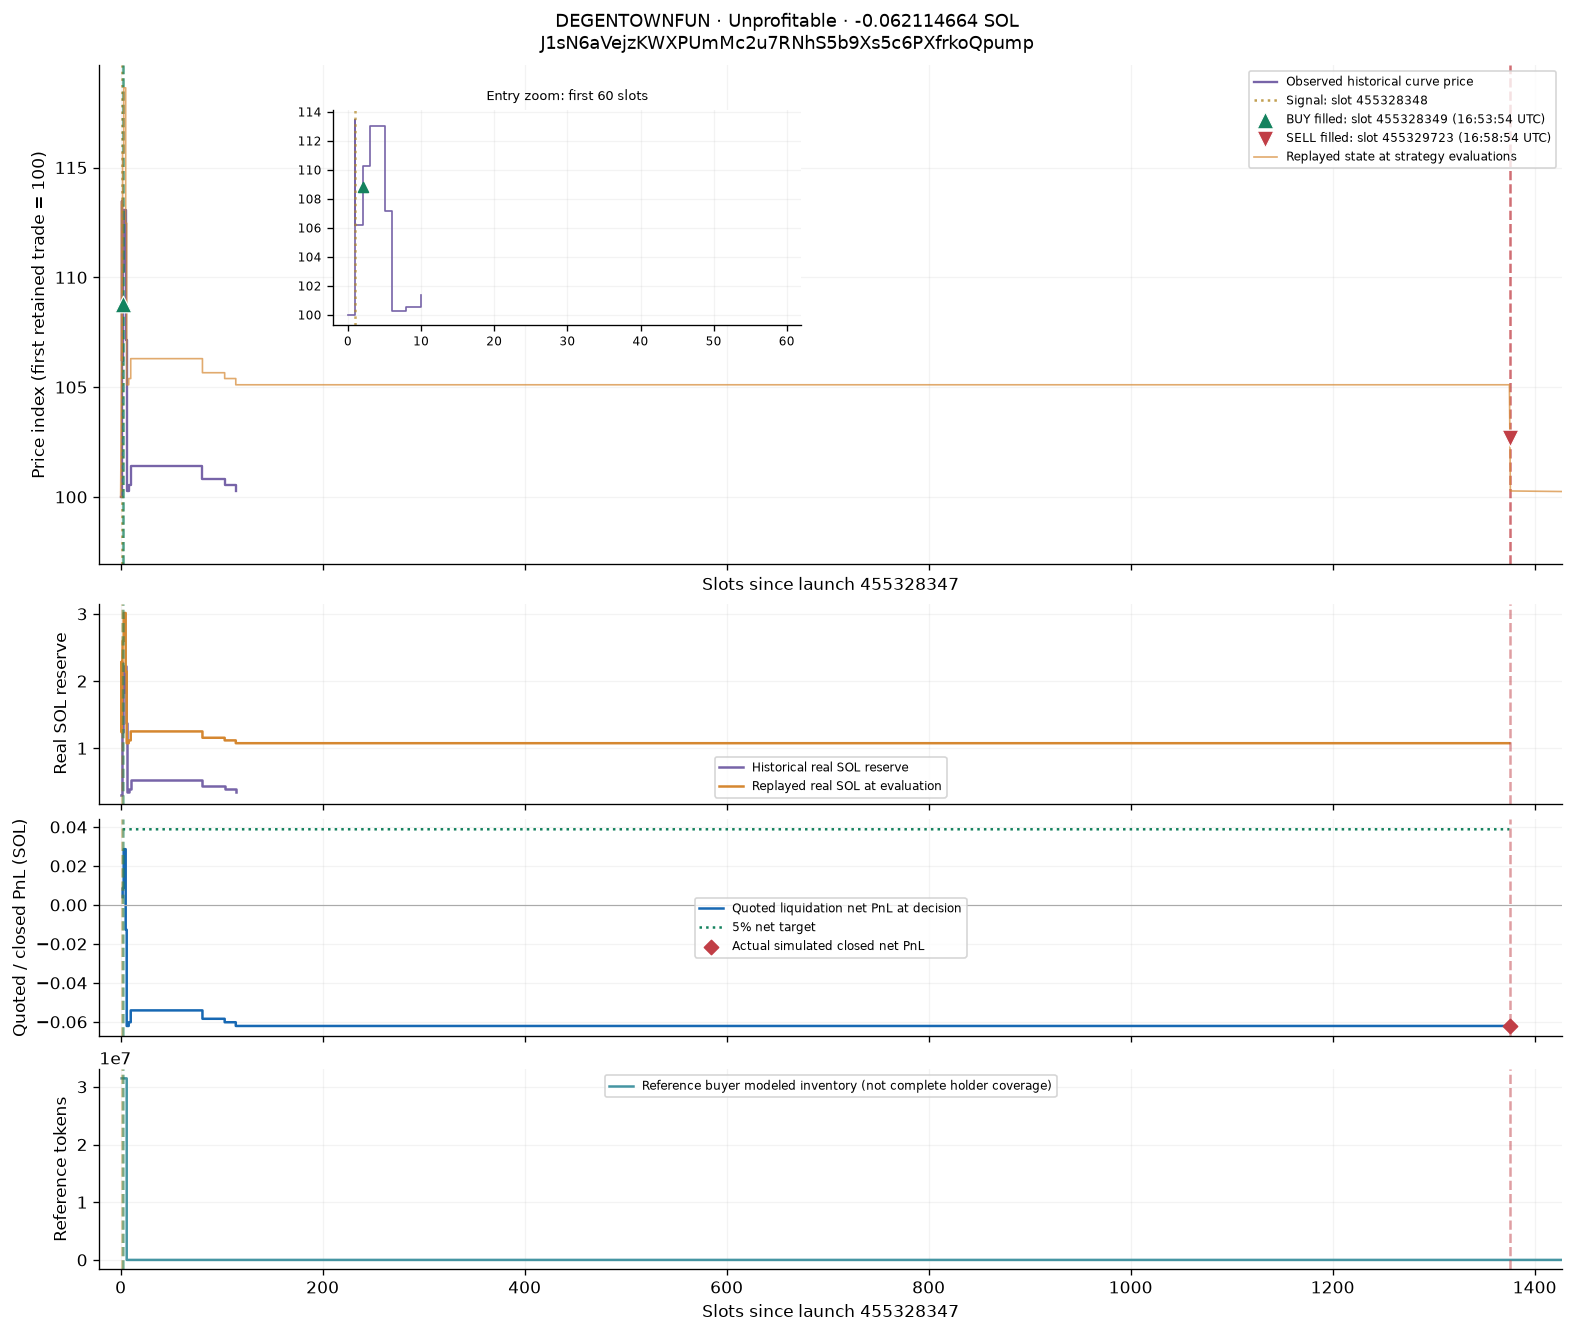

[GMGN token](https://gmgn.ai/sol/token/J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump) · [Reference buyer](https://gmgn.ai/sol/address/4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53) · [Creator](https://gmgn.ai/sol/address/4ZC96Gebcxz27N8Pf6zi1tnHmNnqUMfw4jUaPFojBvfV)

,field,recorded_value
0,signal_slot,455328348
1,entry_slot,455328349
2,exit_signal_slot,455329722
3,exit_slot,455329723
4,reason,TIMEOUT
5,budget_lamports,776072720
6,entry_cash_sol,0.778217000
7,closed_pnl_sol,-0.062114664
8,sniper_trading_cash_cost_sol,1.032005000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump
symbol,DEGENTOWNFUN
boundary_ordinal,1955620363601708020
slot,455328348
time,1791651234
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,2
virtual_sol,31236117806


**Exit decision**

,recorded_value
mint,J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump
symbol,DEGENTOWNFUN
boundary_ordinal,1955626264886771712
slot,455329722
time,1791651534
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,2
virtual_sol,31075102618


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620359306740707,455328347,1791651234,ENTRY_NO_WINDOW,NO_SIGNAL,NO_ELIGIBLE_EARLY_BUYER,0,30310734464,1062000000000000,,,,,,,,,,,,,,,,,,,,,,,,
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620363601707647,455328348,1791651234,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,1,31298388784,1028487447834768,EaoBCDSwUfzyqthe55Qne8StLxS64TwSq7m5wD2umsFN,0,1298388784,33512552165232,1005005000,1005005000,0,,,,,,,,,,,,,,,,,
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620363601707647,455328348,1791651234,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,1,31298388784,1028487447834768,,,,,,,,,,,,,,,,,,,,,,,,
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620363601707665,455328348,1791651234,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,32286043104,997025243976256,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,0,2286043104,31462203858512,1032005000,1032005000,0,,,,,,,,,,,,,,,,,
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620363601707665,455328348,1791651234,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,32286043104,997025243976256,EaoBCDSwUfzyqthe55Qne8StLxS64TwSq7m5wD2umsFN,0,2286043104,33512552165232,1005005000,1005005000,0,,,,,,,,,,,,,,,,,
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620363601707665,455328348,1791651234,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,32286043104,997025243976256,,,,,,,,,,,,,,,,,,,,,,,,
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620363601708020,455328348,1791651234,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,2,31236117806,1030537796141488,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,776072763,1236117806,31462203858512,1032005000,1032005000,0,,,,,,,,,,,,,,,,,
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620363601708020,455328348,1791651234,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,2,31236117806,1030537796141488,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,776072720,,31462203858512,1032005000,1032005000,0,33225994712.8706480928845602365267362708327165577192555597611,33224994694.7475932782658471470562573503897677617270620778482,1000000,32002609381,2002609381,24682316621488,766491575,23448200790413,,,,,,,,,
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620363601708020,455328348,1791651234,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,2,31236117806,1030537796141488,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,,,31462203858512,1032005000,1032005000,0,,,,,,,,,BUY,2d4f77ba5b70796ee2aebfdeea6784cea2236891bc53980fc4d99d273d1a2bd5,[],0,,,,,
J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump,DEGENTOWNFUN,1955620367896674304,455328349,1791651234,ORDER_FILLED,PENDING_BUY,SIGNAL,2,32002609381,1005855479520000,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,,,31462203858512,1032005000,1032005000,0,,,,,,,,,BUY,2d4f77ba5b70796ee2aebfdeea6784cea2236891bc53980fc4d99d273d1a2bd5,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,


In [6]:
selected = review.ENTRY_EXIT[review.ENTRY_EXIT['group'] == 'Unprofitable']
review.linked_table(selected[columns])
for mint in selected['mint']:
    display(Markdown('---'))
    review.inspect(mint)

## Unresolved position — 1

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,gmgn_url
毒チワワ,Undecided,CONDITIONAL_TRANSFER_SOURCE_INVENTORY_CONFLICT,455326949,455326950,2026-10-10T16:48:51+00:00,,,1.207495000,—,—,1.207495000,0.000000000,GMGN


---

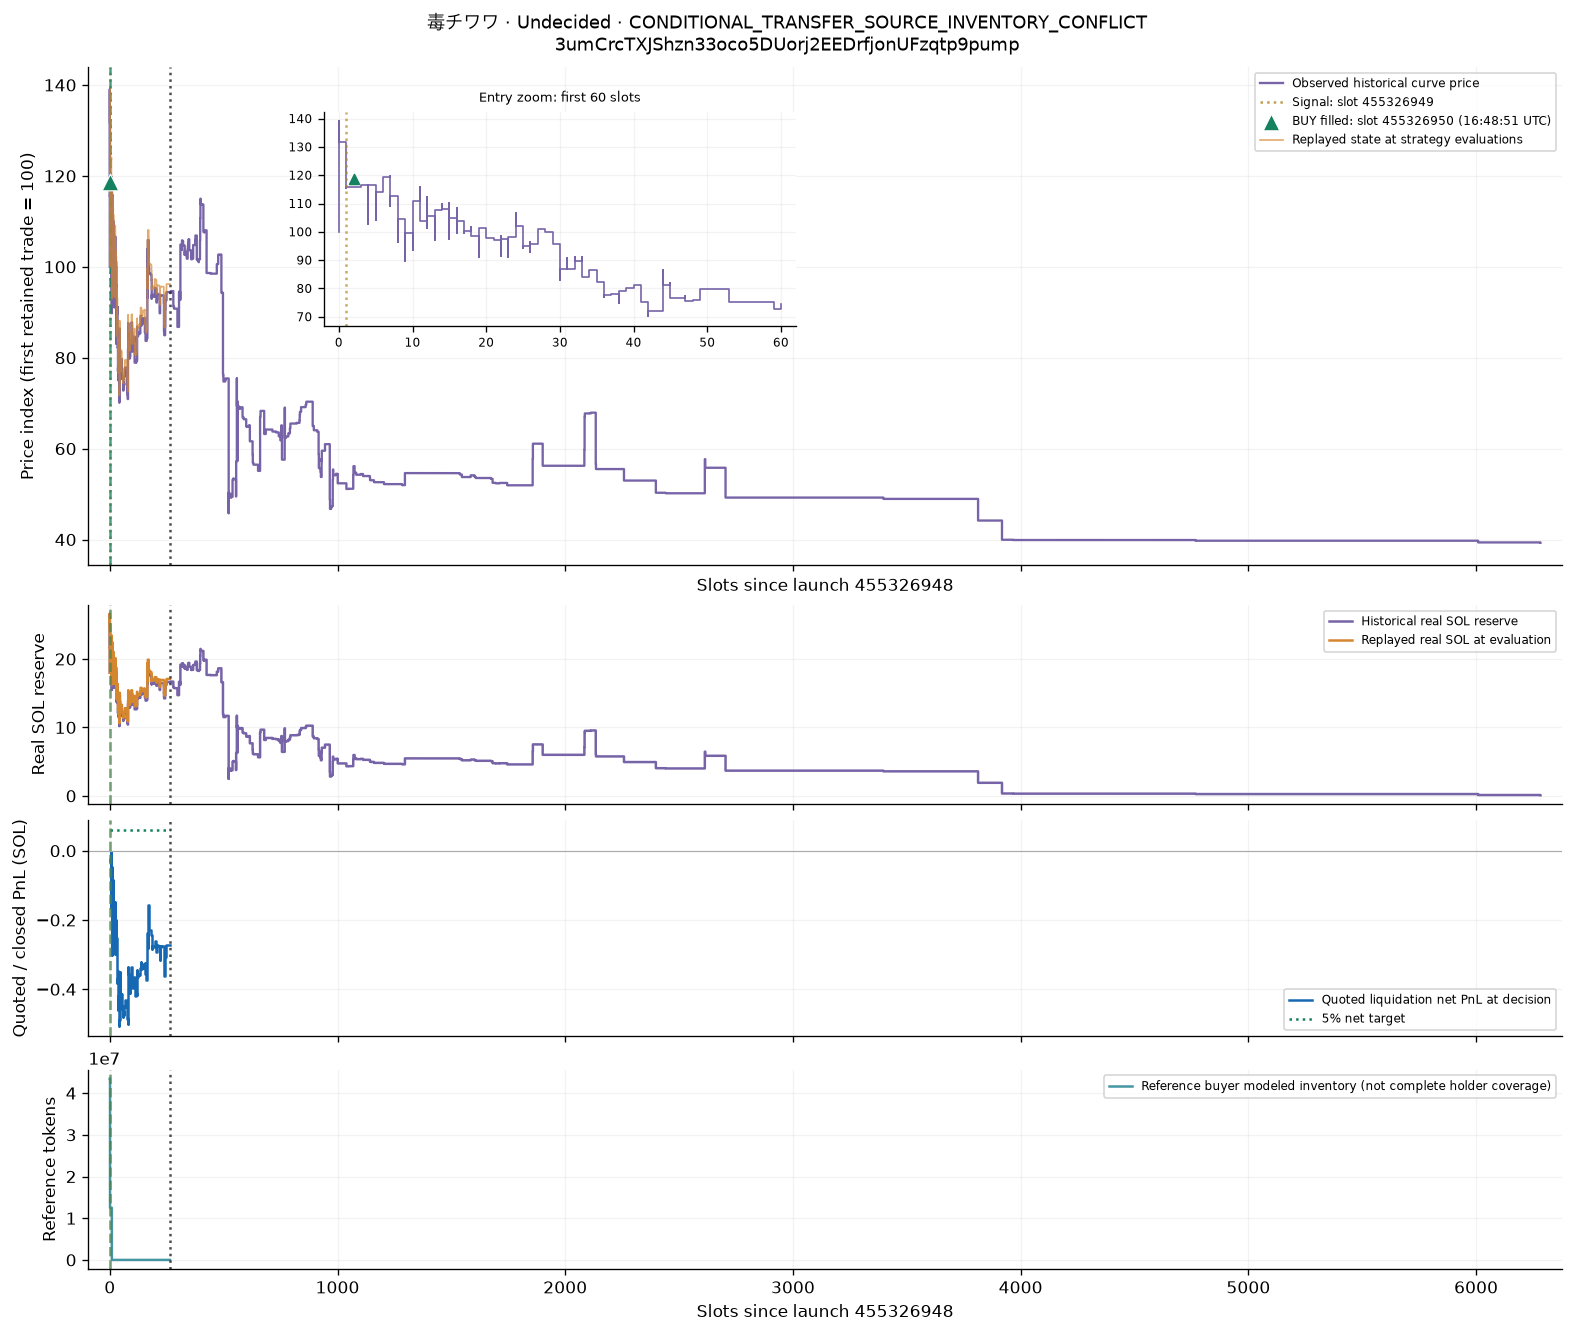

[GMGN token](https://gmgn.ai/sol/token/3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump) · [Reference buyer](https://gmgn.ai/sol/address/dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK) · [Creator](https://gmgn.ai/sol/address/DqExco2kr2ABqGnfs9EWi5tZfs6RHJG2UZm4XzxHASMR)

,field,recorded_value
0,signal_slot,455326949
1,entry_slot,455326950
2,exit_signal_slot,None
3,exit_slot,None
4,reason,CONDITIONAL_TRANSFER_SOURCE_INVENTORY_CONFLICT
5,budget_lamports,1205350720
6,entry_cash_sol,1.207495000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,4.099004999
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump
symbol,毒チワワ
boundary_ordinal,1955614354942460493
slot,455326949
time,1791650930
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,4
virtual_sol,54252007890


**Exit decision**

,recorded_value
mint,3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump
symbol,毒チワワ
boundary_ordinal,1955615484518858752
slot,455327212
time,1791650986
action,EXIT_EVALUATION
status,OPEN
reason,HOLDING
eligible_wallets,4
virtual_sol,47078648680


**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614350647494013,455326948,1791650930,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,55771622998,577175242045354,,,,,,,,,,,,,,,,,,,,,,,,
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614350647494035,455326948,1791650930,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,55070468257,584523811438062,gVDXhoGbePACvSqN7CZBtQXFW9eyJwsgudPEwSydAkx,0,25070468257,402374999999999,18225110000,18225110000,0,,,,,,,,,,,,,,,,,
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614350647494035,455326948,1791650930,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,55070468257,584523811438062,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,382071198,25070468257,43470410516580,4099004999,4099004999,0,,,,,,,,,,,,,,,,,
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614350647494035,455326948,1791650930,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,55070468257,584523811438062,2CkArwyYvfAppyMacUo4ZWQumFGGwTKwwJoURbrTi8bQ,0,25070468257,22045708178124,1712837695,1712837695,0,,,,,,,,,,,,,,,,,
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614350647494035,455326948,1791650930,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,55070468257,584523811438062,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,0,25070468257,15568080342147,1024703917,1024703917,0,,,,,,,,,,,,,,,,,
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614350647494035,455326948,1791650930,ENTRY_NO_WINDOW,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,55070468257,584523811438062,,,,,,,,,,,,,,,,,,,,,,,,
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614354942460493,455326949,1791650930,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,54252007890,593342094709311,gVDXhoGbePACvSqN7CZBtQXFW9eyJwsgudPEwSydAkx,0,24252007890,402374999999999,18225110000,18225110000,0,,,,,,,,,,,,,,,,,
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614354942460493,455326949,1791650930,ENTRY_CANDIDATE,NO_SIGNAL,NO_POSITIVE_BREAK_EVEN_WINDOW,4,54252007890,593342094709311,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,1205350763,24252007890,43470410516580,4099004999,4099004999,0,,,,,,,,,,,,,,,,,
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614354942460493,455326949,1791650930,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,4,54252007890,593342094709311,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,1205350720,,43470410516580,4099004999,4099004999,0,57555691939.2197238324500118503761102562955101963009876655716,57554691938.7490318611586993835112930719458536556925722408780,1000000,55442477736,25442477736,12740337379883,1190469846,12103320510888,,,,,,,,,
3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,毒チワワ,1955614354942460493,455326949,1791650930,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,4,54252007890,593342094709311,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,,,43470410516580,4099004999,4099004999,0,,,,,,,,,BUY,9db3c9d0617d968bdd29fcc88f09142aef117c05c5bf940de707e8d924f628ea,[],0,,,,,


**Counterparty replay conflicts** — a conflict after an already completed exit does not reopen that position.

,mint,boundary_ordinal,reason
0,3umCrcTXJShzn33oco5DUorj2EEDrfjonUFzqtp9pump,1955615484518859636,CONDITIONAL_TRANSFER_SOURCE_INVENTORY_CONFLICT


In [7]:
selected = review.ENTRY_EXIT[review.ENTRY_EXIT['group'] == 'Undecided']
review.linked_table(selected[columns])
for mint in selected['mint']:
    display(Markdown('---'))
    review.inspect(mint)

## Failed entries — 9

token,group,reason,signal_slot,entry_slot,entry_utc,exit_slot,exit_utc,entry_SOL,exit_receipt_SOL,net_pnl_SOL,open_cost_SOL,failed_execution_fees_SOL,gmgn_url
p-,Entry failed,MINIMUM_OUTPUT_NOT_MET,455316087,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN
PAYROLL,Entry failed,MINIMUM_OUTPUT_NOT_MET,455319609,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN
ECX,Entry failed,MINIMUM_OUTPUT_NOT_MET,455320465,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN
PAYROLL,Entry failed,MINIMUM_OUTPUT_NOT_MET,455322673,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN
FUND,Entry failed,MINIMUM_OUTPUT_NOT_MET,455322764,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN
PAGENT,Entry failed,MINIMUM_OUTPUT_NOT_MET,455325688,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN
glint,Entry failed,MINIMUM_OUTPUT_NOT_MET,455328851,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN
DAFUQ,Entry failed,MINIMUM_OUTPUT_NOT_MET,455328857,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN
VEIL,Entry failed,MINIMUM_OUTPUT_NOT_MET,455329582,,,,,0.000000000,—,-0.000105000,0.000000000,0.000105000,GMGN


---

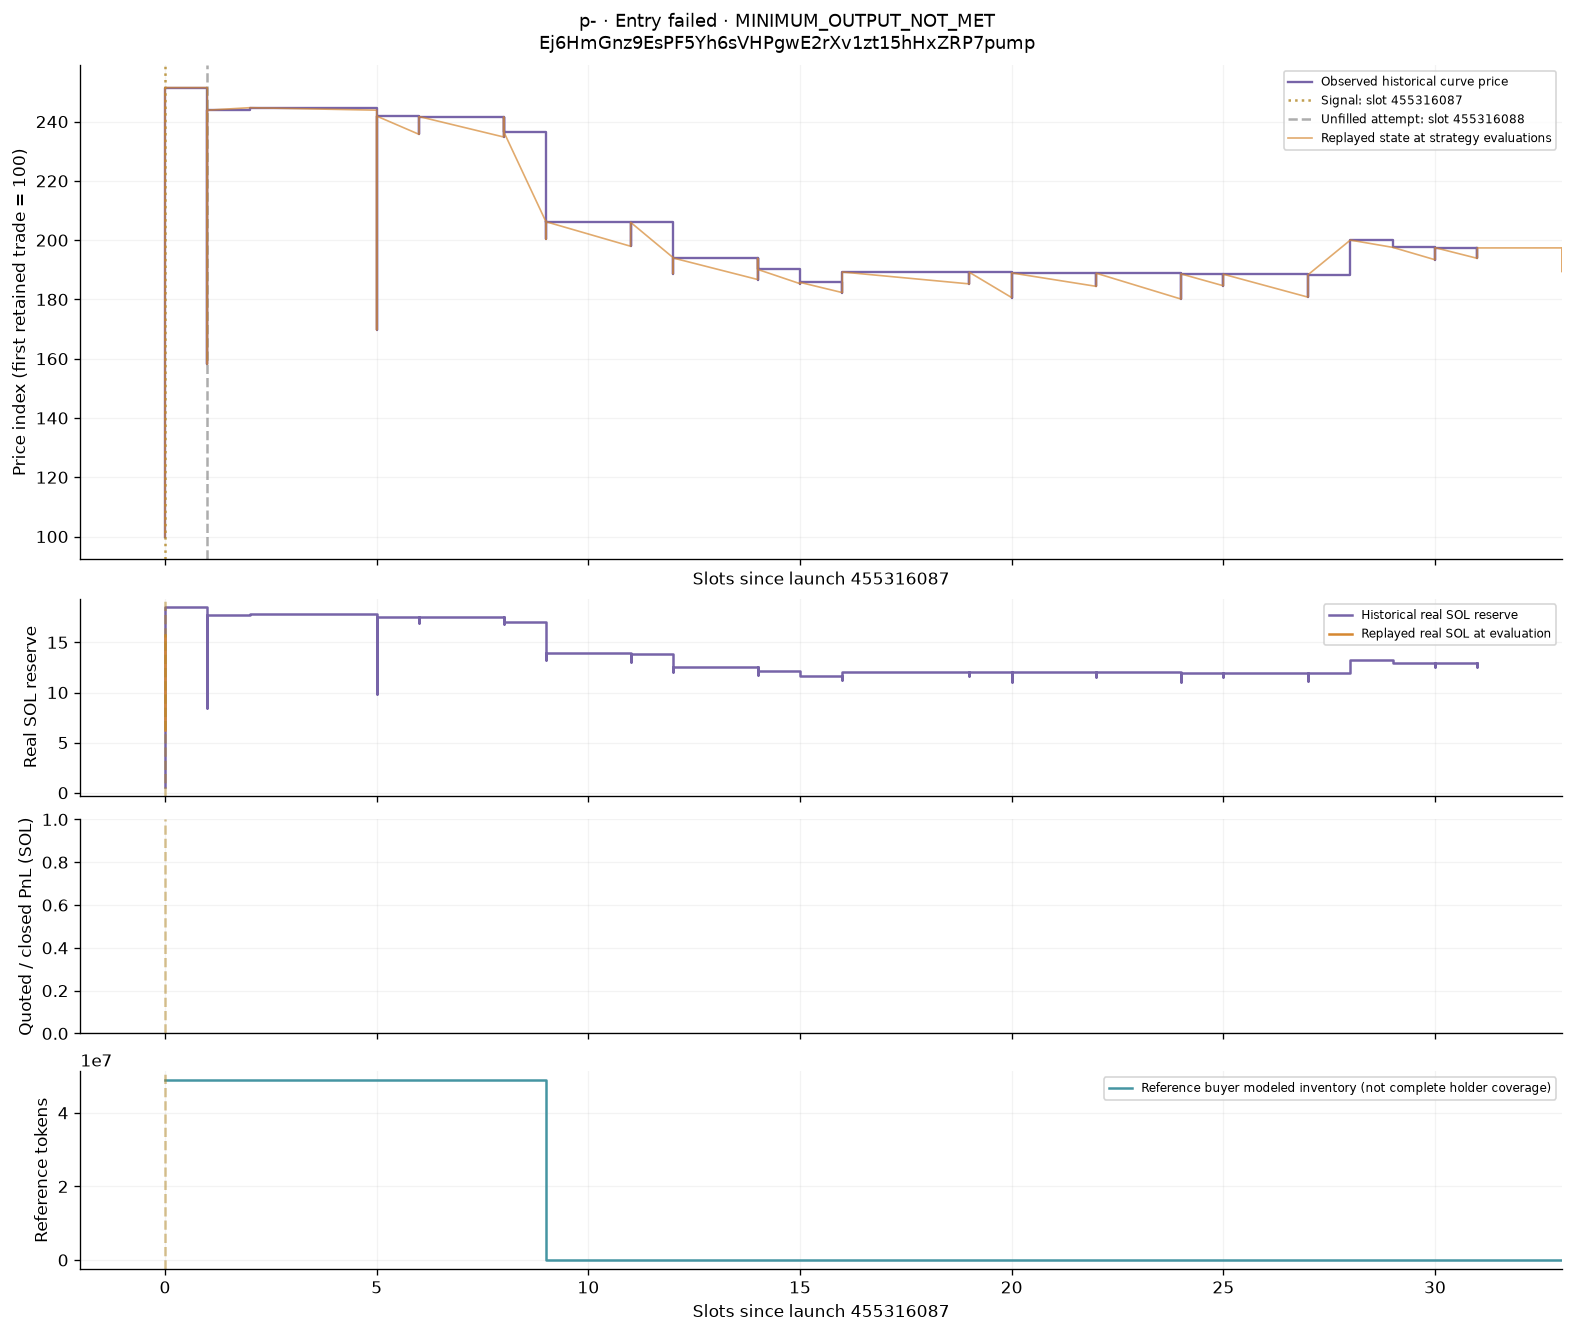

[GMGN token](https://gmgn.ai/sol/token/Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump) · [Reference buyer](https://gmgn.ai/sol/address/9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw) · [Creator](https://gmgn.ai/sol/address/4aJVUXgYcnMEwpMTyHjumrykkcqaPEuoX7sgizXpUWcC)

,field,recorded_value
0,signal_slot,455316087
1,entry_slot,None
2,exit_signal_slot,None
3,exit_slot,None
4,reason,MINIMUM_OUTPUT_NOT_MET
5,budget_lamports,915979420
6,entry_cash_sol,0.000000000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,3.266786404
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump
symbol,p-
boundary_ordinal,1955567703007690922
slot,455316087
time,1791648549
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,3
virtual_sol,45711966947


**Exit decision**

No completed exit decision; inspect the recorded failure/conflict below.

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955567703007690922,455316087,1791648549,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,3,45711966947,704191968784278,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,48808031215735,3266786404,3266786404,0,,,,,,,,,BUY,3cf502352889148ec031d9c05e8936b8327a7073890d5893d9a9c827af66dba7,[],0,,,,,
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955567707302658048,455316088,1791648549,ORDER_EXECUTION_FAILED,PENDING_BUY,SIGNAL,5,48477399043,664020773368455,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,48808031215735,3266786404,3266786404,0,,,,,,,,,BUY,3cf502352889148ec031d9c05e8936b8327a7073890d5893d9a9c827af66dba7,"[""MINIMUM_OUTPUT_NOT_MET""]",105000,,,,,
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955569064512324145,455316404,1791648617,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,31696689525,1015563471114691,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,0,176127317,176127317,0,,,,,,,,,,,,,,,,,
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955569150411670433,455316424,1791648623,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,31618397100,1018078175681490,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,0,176127317,176127317,0,,,,,,,,,,,,,,,,,
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955569154706636900,455316425,1791648623,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,31352066643,1026726576107562,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,0,176127317,176127317,0,,,,,,,,,,,,,,,,,
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955569193361342991,455316434,1791648625,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,31300358776,1028422717731724,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,0,176127317,176127317,0,,,,,,,,,,,,,,,,,
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955569201951277618,455316436,1791648626,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,30804697382,1044970500440601,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,0,176127317,176127317,0,,,,,,,,,,,,,,,,,
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955569309325459558,455316461,1791648632,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,30785990499,1045605469175902,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,0,176127317,176127317,0,,,,,,,,,,,,,,,,,
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955569528368792332,455316512,1791648644,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,30751902538,1046764505060447,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,0,176127317,176127317,0,,,,,,,,,,,,,,,,,
Ej6HmGnz9EsPF5Yh6sVHPgwE2rXv1zt15hHxZRP7pump,p-,1955569545548662688,455316516,1791648645,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,30738390738,1047224635633059,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,,,0,176127317,176127317,0,,,,,,,,,,,,,,,,,


---

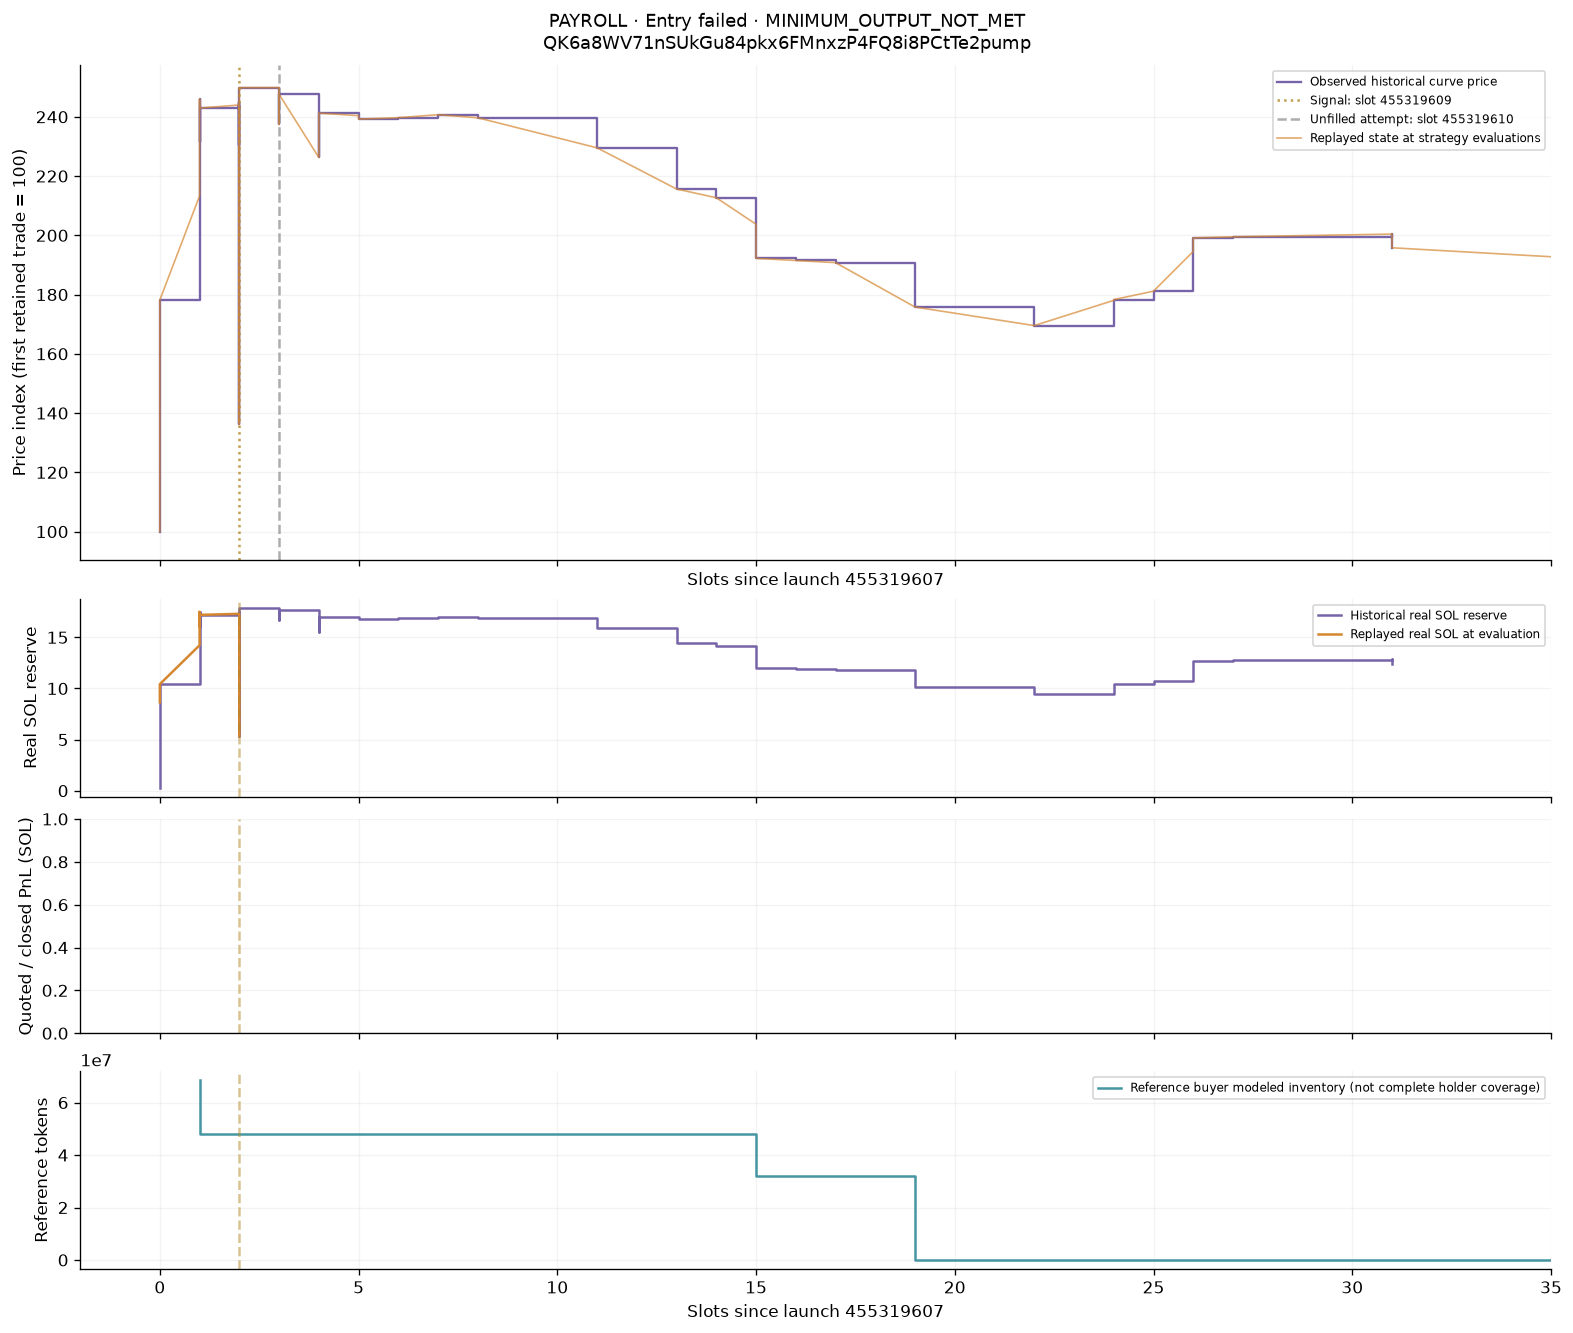

[GMGN token](https://gmgn.ai/sol/token/QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump) · [Reference buyer](https://gmgn.ai/sol/address/8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4) · [Creator](https://gmgn.ai/sol/address/BAdGazrrQnPiMVpSCryogWCr3sqkBSHVo9QukLUx9PgC)

,field,recorded_value
0,signal_slot,455319609
1,entry_slot,None
2,exit_signal_slot,None
3,exit_slot,None
4,reason,MINIMUM_OUTPUT_NOT_MET
5,budget_lamports,5348770440
6,entry_cash_sol,0.000000000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,2.473870753
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump
symbol,PAYROLL
boundary_ordinal,1955582829882507823
slot,455319609
time,1791649322
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,5
virtual_sol,35353300905


**Exit decision**

No completed exit decision; inspect the recorded failure/conflict below.

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955582829882507823,455319609,1791649322,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,5,35353300905,910523181242607,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,47963733476715,2473870753,2473870753,0,,,,,,,,,BUY,c2e03edfbbb6bacc9f97dc0cce4fb534dfc86550ce2bb3638fa11a4d35a46b8a,[],0,,,,,
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955582834177474560,455319610,1791649322,ORDER_EXECUTION_FAILED,PENDING_BUY,SIGNAL,8,47866120468,672500710218171,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,47963733476715,2473870753,2473870753,0,,,,,,,,,BUY,c2e03edfbbb6bacc9f97dc0cce4fb534dfc86550ce2bb3638fa11a4d35a46b8a,"[""MINIMUM_OUTPUT_NOT_MET""]",105000,,,,,
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955585668855890564,455320270,1791649469,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,8,32928614892,977569210351296,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,0,-108331383,-108331383,0,,,,,,,,,,,,,,,,,
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955585668855890566,455320270,1791649469,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,8,31889690490,1009417136520480,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,0,-108331383,-108331383,0,,,,,,,,,,,,,,,,,
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955585681740792044,455320273,1791649469,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,8,31938579378,1007872005795012,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,0,-108331383,-108331383,0,,,,,,,,,,,,,,,,,
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955585686035759494,455320274,1791649470,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,8,31886954974,1009503732392130,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,0,-108331383,-108331383,0,,,,,,,,,,,,,,,,,
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955585694625694589,455320276,1791649470,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,8,31864105008,1010227654384280,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,0,-108331383,-108331383,0,,,,,,,,,,,,,,,,,
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955585720395498340,455320282,1791649471,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,8,31724600352,1014669994412248,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,0,-108331383,-108331383,0,,,,,,,,,,,,,,,,,
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955585750460268602,455320289,1791649472,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,8,31128793541,1034090833607648,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,0,-108331383,-108331383,0,,,,,,,,,,,,,,,,,
QK6a8WV71nSUkGu84pkx6FMnxzP4FQ8i8PCtTe2pump,PAYROLL,1955585750460268603,455320289,1791649472,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,8,30258965197,1063816949891693,8RvtT8189KpAq5MkXGVHFn6LdZpxq9PkvDeAvs1g5Yj4,,,0,-108331383,-108331383,0,,,,,,,,,,,,,,,,,


---

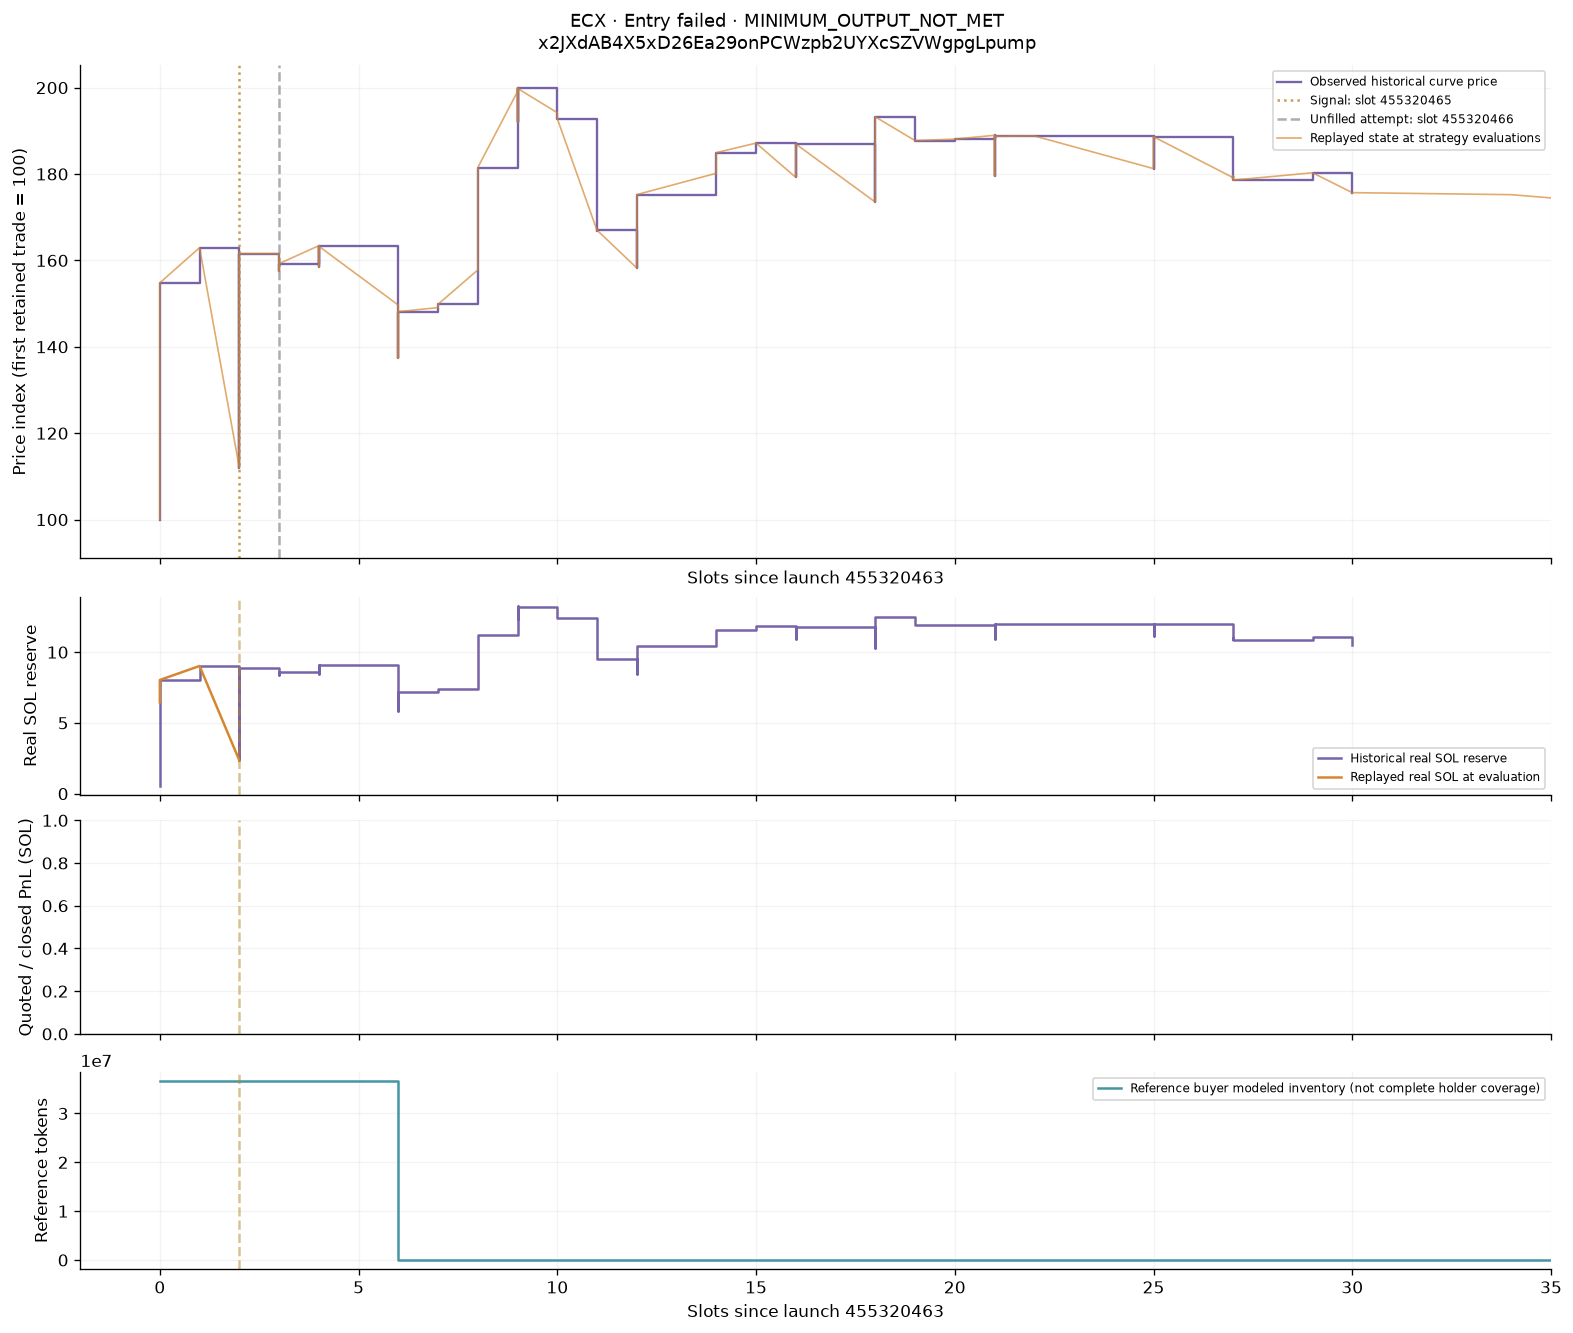

[GMGN token](https://gmgn.ai/sol/token/x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump) · [Reference buyer](https://gmgn.ai/sol/address/8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX) · [Creator](https://gmgn.ai/sol/address/BrVEiscRsSciMY89n3egLgL6geEmwcNsFfCpRB29hmUb)

,field,recorded_value
0,signal_slot,455320465
1,entry_slot,None
2,exit_signal_slot,None
3,exit_slot,None
4,reason,MINIMUM_OUTPUT_NOT_MET
5,budget_lamports,4742948702
6,entry_cash_sol,0.000000000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,1.600567086
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump
symbol,ECX
boundary_ordinal,1955586506374512791
slot,455320465
time,1791649511
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,3
virtual_sol,32355186202


**Exit decision**

No completed exit decision; inspect the recorded failure/conflict below.

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955586506374512791,455320465,1791649511,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,3,32355186202,994894599035169,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,36685663249107,1600567086,1600567086,0,,,,,,,,,BUY,6f0d03ab02afa12a02879c07efd2af7ac14a3e2049161ece9e0b0ea66ecb1b29,[],0,,,,,
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955586510669479936,455320466,1791649511,ORDER_EXECUTION_FAILED,PENDING_BUY,SIGNAL,5,38858525853,828389633845616,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,36685663249107,1600567086,1600567086,0,,,,,,,,,BUY,6f0d03ab02afa12a02879c07efd2af7ac14a3e2049161ece9e0b0ea66ecb1b29,"[""MINIMUM_OUTPUT_NOT_MET""]",105000,,,,,
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955587146324639984,455320614,1791649545,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,5,35479134022,907293848147340,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,0,-43309428,-43309428,0,,,,,,,,,,,,,,,,,
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955587382547841201,455320669,1791649556,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,5,35478380451,907313119332203,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,0,-43309428,-43309428,0,,,,,,,,,,,,,,,,,
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955588129872150982,455320843,1791649594,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,5,35450847897,908017775186624,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,0,-43309428,-43309428,0,,,,,,,,,,,,,,,,,
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955589143484433278,455321079,1791649646,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,5,35354431374,910494067803081,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,0,-43309428,-43309428,0,,,,,,,,,,,,,,,,,
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955589392592536604,455321137,1791649658,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,5,34107181770,943789500245003,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,0,-43309428,-43309428,0,,,,,,,,,,,,,,,,,
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955589392592536614,455321137,1791649658,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,5,33658844247,956360824575636,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,0,-43309428,-43309428,0,,,,,,,,,,,,,,,,,
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955589392592536619,455321137,1791649658,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,5,32680737633,984983888696068,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,0,-43309428,-43309428,0,,,,,,,,,,,,,,,,,
x2JXdAB4X5xD26Ea29onPCWzpb2UYXcSZVWgpgLpump,ECX,1955589392592536624,455321137,1791649658,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,5,32143907224,1001433951871563,8ki679dZgE8ozmGVKBzBbBqqby5CToRfqzAoKYx49aNX,,,0,-43309428,-43309428,0,,,,,,,,,,,,,,,,,


---

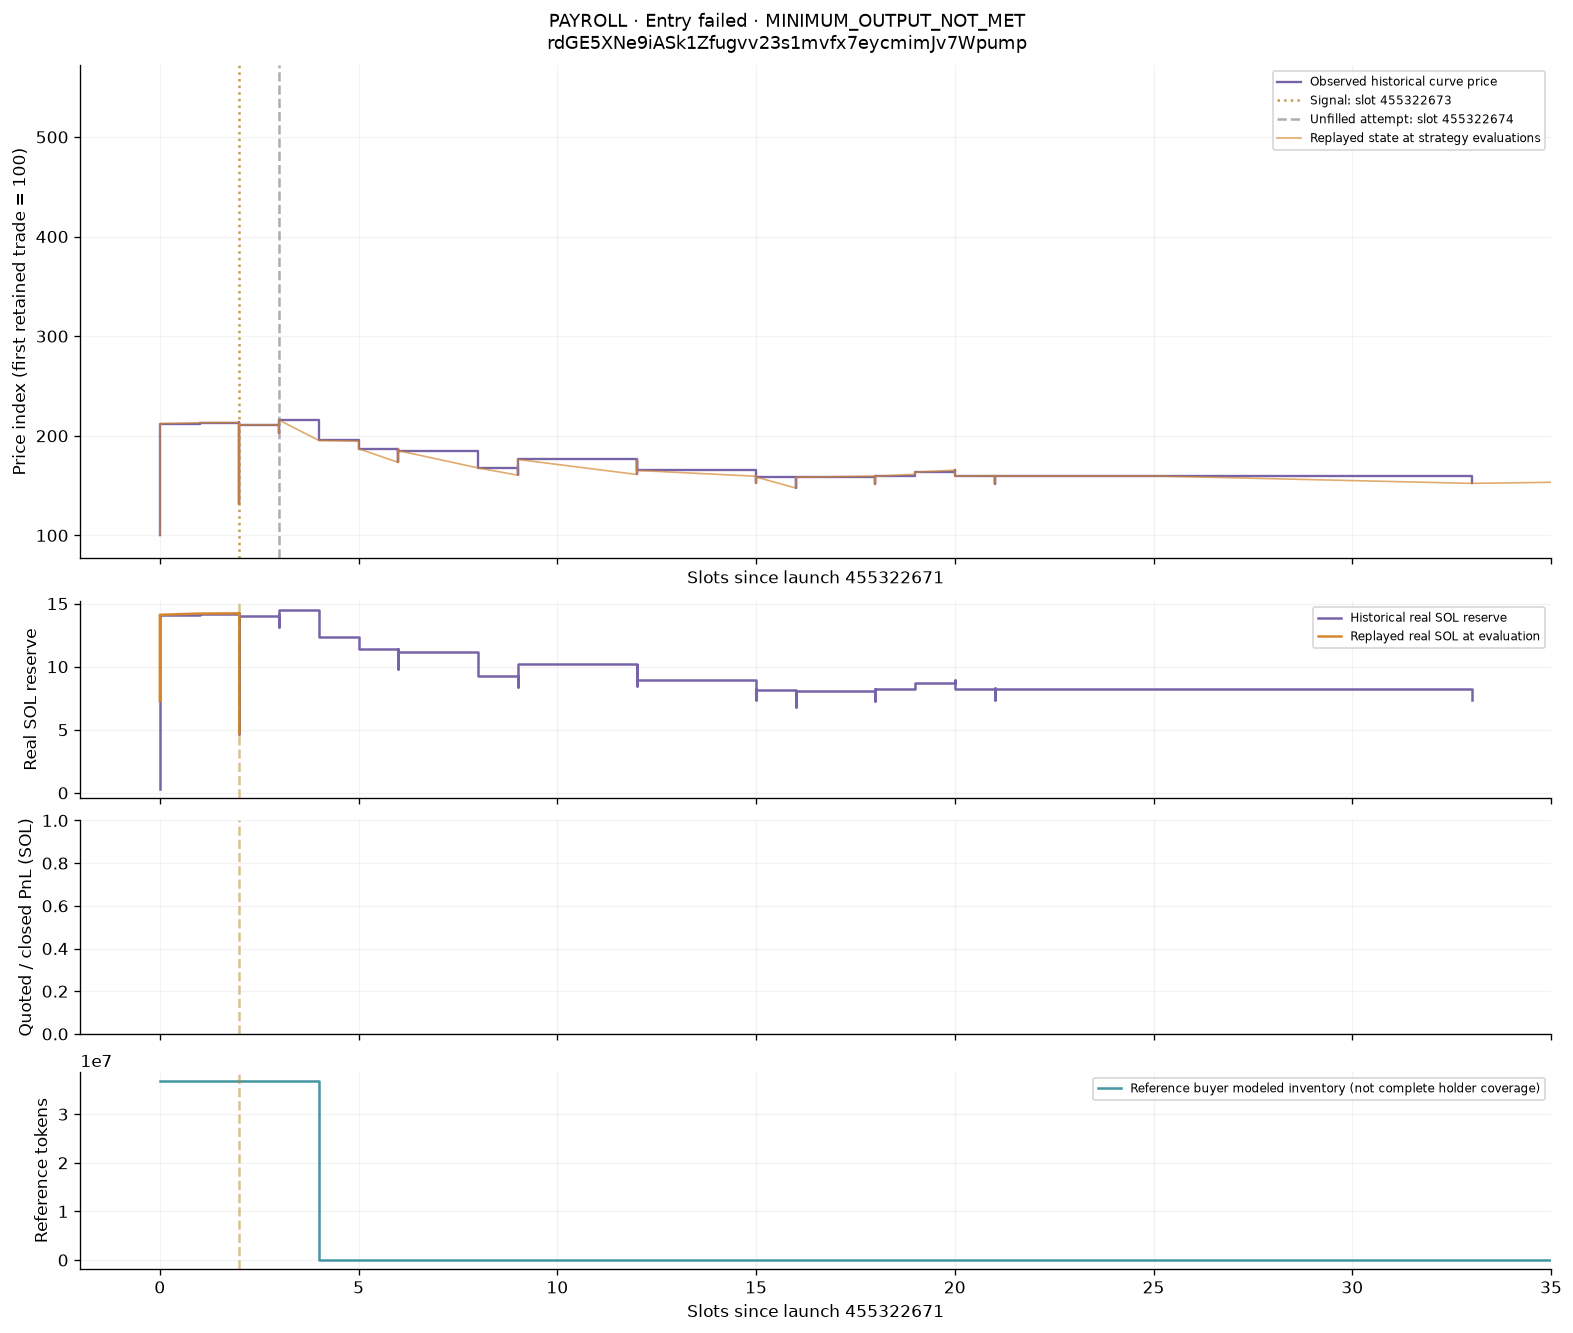

[GMGN token](https://gmgn.ai/sol/token/rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump) · [Reference buyer](https://gmgn.ai/sol/address/BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL) · [Creator](https://gmgn.ai/sol/address/EfpqcHMinnGtEQM4RGh3rCcRUsgyDDfGsJvs9ZHfjWvt)

,field,recorded_value
0,signal_slot,455322673
1,entry_slot,None
2,exit_signal_slot,None
3,exit_slot,None
4,reason,MINIMUM_OUTPUT_NOT_MET
5,budget_lamports,6775465706
6,entry_cash_sol,0.000000000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,2.000430000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump
symbol,PAYROLL
boundary_ordinal,1955595989662303037
slot,455322673
time,1791649993
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,5
virtual_sol,34696580040


**Exit decision**

No completed exit decision; inspect the recorded failure/conflict below.

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955595989662303037,455322673,1791649993,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,5,34696580040,927757144047314,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,36856248125510,2000430000,2000430000,0,,,,,,,,,BUY,da05350666f5c9e65be69ed2034ff0f20c5a77cceb4113cb014d4703293b84a6,[],0,,,,,
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955595993957269504,455322674,1791649994,ORDER_EXECUTION_FAILED,PENDING_BUY,SIGNAL,7,43996351153,731651583881963,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,36856248125510,2000430000,2000430000,0,,,,,,,,,BUY,da05350666f5c9e65be69ed2034ff0f20c5a77cceb4113cb014d4703293b84a6,"[""MINIMUM_OUTPUT_NOT_MET""]",105000,,,,,
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955637818348798897,455332412,1791652120,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,34159126724,942354324357439,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,0,-127812726,-127812726,0,,,,,,,,,,,,,,,,,
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955637917133046634,455332435,1791652125,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,34146879667,942692307440393,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,0,-127812726,-127812726,0,,,,,,,,,,,,,,,,,
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955637994442457429,455332453,1791652129,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,34139445778,942897579388757,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,0,-127812726,-127812726,0,,,,,,,,,,,,,,,,,
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955638187715985599,455332498,1791652140,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,33884523577,949991246383658,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,0,-127812726,-127812726,0,,,,,,,,,,,,,,,,,
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955639523450815421,455332809,1791652208,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,33869535688,950411634904651,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,0,-127812726,-127812726,0,,,,,,,,,,,,,,,,,
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955639832688459922,455332881,1791652223,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,33118829817,971954654338602,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,0,-127812726,-127812726,0,,,,,,,,,,,,,,,,,
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955640425393947168,455333019,1791652253,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,33118307848,971969973087346,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,0,-127812726,-127812726,0,,,,,,,,,,,,,,,,,
rdGE5XNe9iASk1Zfugvv23s1mvfx7eycmimJv7Wpump,PAYROLL,1955642057481519644,455333399,1791652338,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,33038039914,974331433476734,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,,,0,-127812726,-127812726,0,,,,,,,,,,,,,,,,,


---

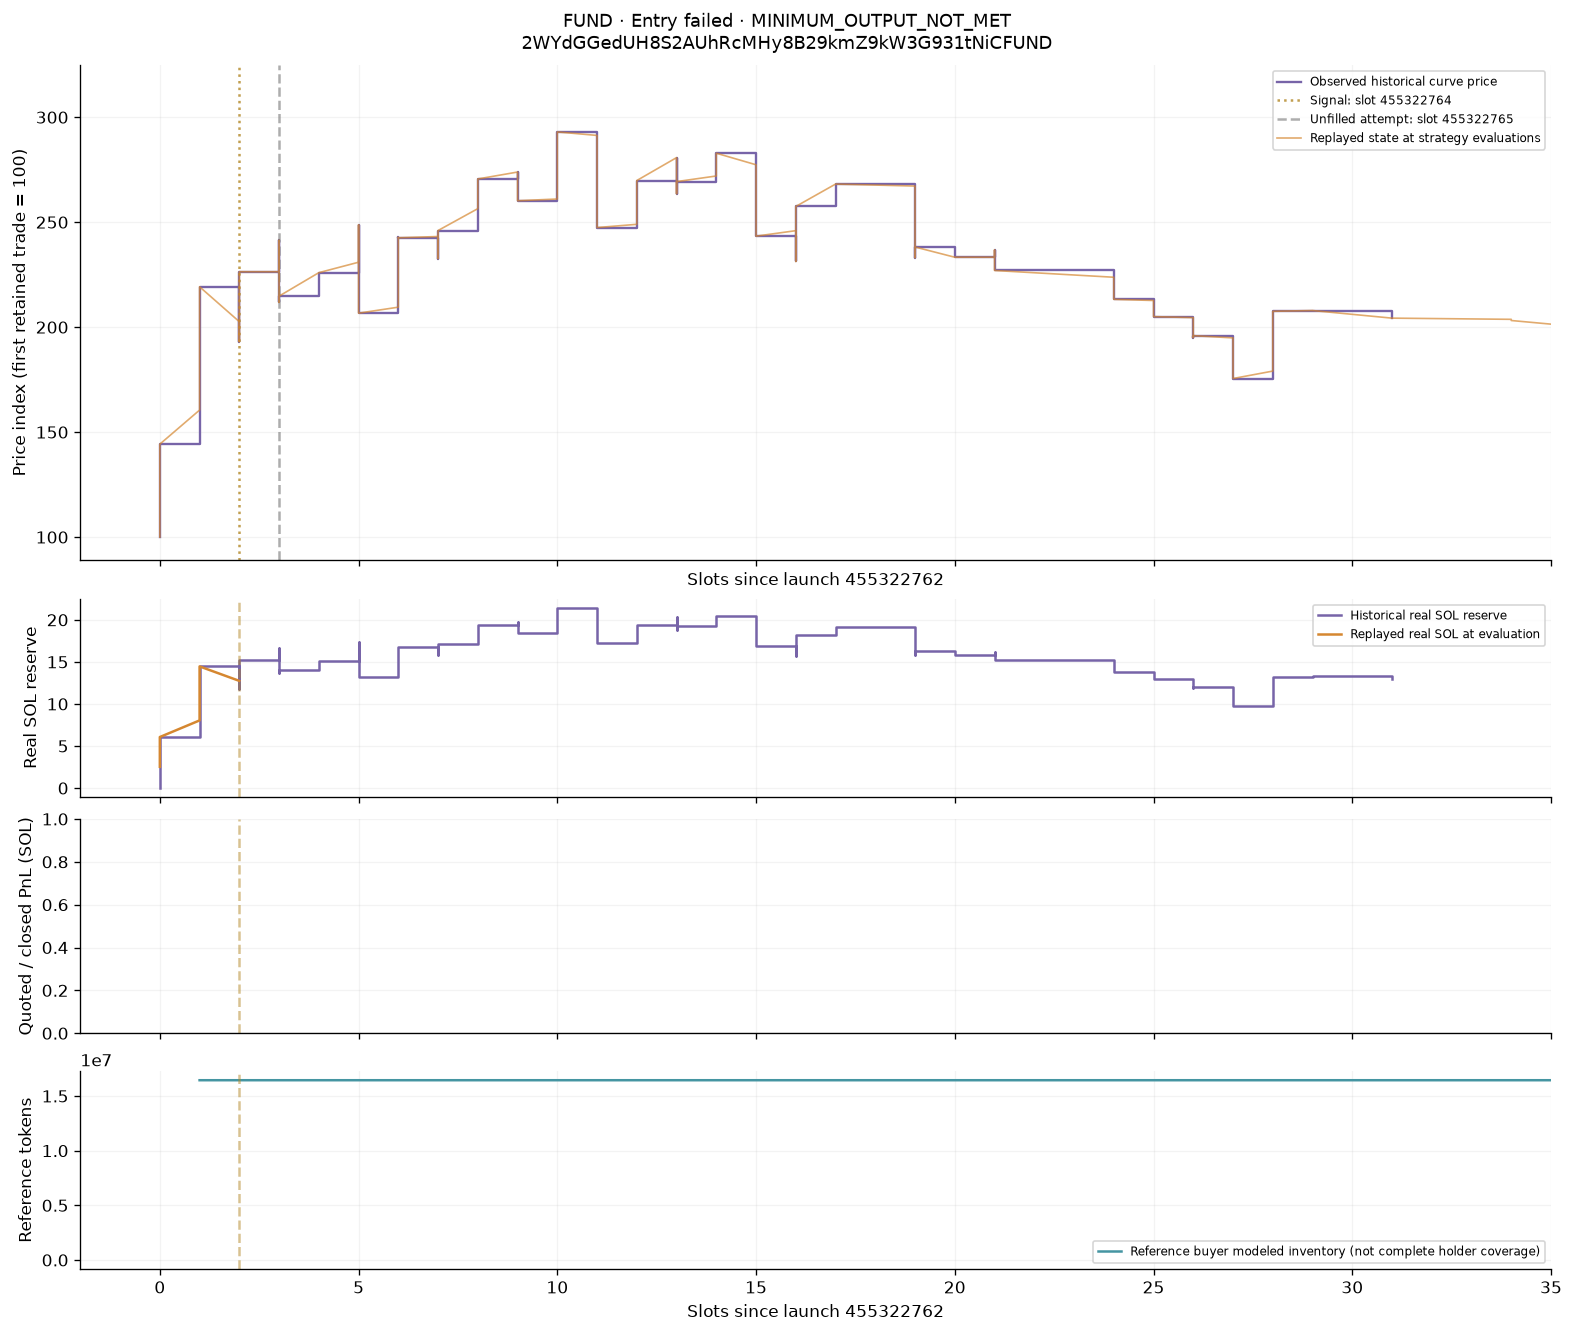

[GMGN token](https://gmgn.ai/sol/token/2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND) · [Reference buyer](https://gmgn.ai/sol/address/5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp) · [Creator](https://gmgn.ai/sol/address/HHt8RbJ6kH3FeNukB9iWgRkvQyJL3DMtpsA7HZucCcbe)

,field,recorded_value
0,signal_slot,455322764
1,entry_slot,None
2,exit_signal_slot,None
3,exit_slot,None
4,reason,MINIMUM_OUTPUT_NOT_MET
5,budget_lamports,734775301
6,entry_cash_sol,0.000000000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,1.004205000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND
symbol,FUND
boundary_ordinal,1955596380504326167
slot,455322764
time,1791650014
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,6
virtual_sol,42744278795


**Exit decision**

No completed exit decision; inspect the recorded failure/conflict below.

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955596380504326167,455322764,1791650014,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,6,42744278795,753083240879871,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,16446094127814,1004205000,1004205000,0,,,,,,,,,BUY,1cedbed317499c2f3f1ce31aa778cbdaaa7cb4e10cfd63d4ed3c0c3c12b96d1f,[],0,,,,,
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955596384799293440,455322765,1791650015,ORDER_EXECUTION_FAILED,PENDING_BUY,SIGNAL,9,45185166721,712401930606445,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,16446094127814,1004205000,1004205000,0,,,,,,,,,BUY,1cedbed317499c2f3f1ce31aa778cbdaaa7cb4e10cfd63d4ed3c0c3c12b96d1f,"[""MINIMUM_OUTPUT_NOT_MET""]",105000,,,,,
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955623082316006008,455328981,1791651372,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,9,39801038013,808772884294821,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,0,-41991996,-41991996,0,,,,,,,,,,,,,,,,,
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955623082316006171,455328981,1791651372,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,9,39572127204,813451350397556,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,0,-41991996,-41991996,0,,,,,,,,,,,,,,,,,
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955623644956721609,455329112,1791651401,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,9,39819040783,808407226272025,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,0,-41991996,-41991996,0,,,,,,,,,,,,,,,,,
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955623846820184865,455329159,1791651411,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,9,39935279616,806054211272025,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,0,-41991996,-41991996,0,,,,,,,,,,,,,,,,,
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955626947786572692,455329881,1791651569,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,9,39819040784,808407226272025,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,0,-41991996,-41991996,0,,,,,,,,,,,,,,,,,
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955627806780031054,455330081,1791651612,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,9,36450184384,883123113290832,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,0,-41991996,-41991996,0,,,,,,,,,,,,,,,,,
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955627884089442630,455330099,1791651616,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,9,33260510609,967814375808679,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,0,-41991996,-41991996,0,,,,,,,,,,,,,,,,,
2WYdGGedUH8S2AUhRcMHy8B29kmZ9kW3G931tNiCFUND,FUND,1955628012938461853,455330129,1791651622,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,9,31386402945,1025603359860413,5EtD6bwu6GrRUdvAKZs7pymFw8tFMD4MWQ2pGj4fPFEp,,,0,-41991996,-41991996,0,,,,,,,,,,,,,,,,,


---

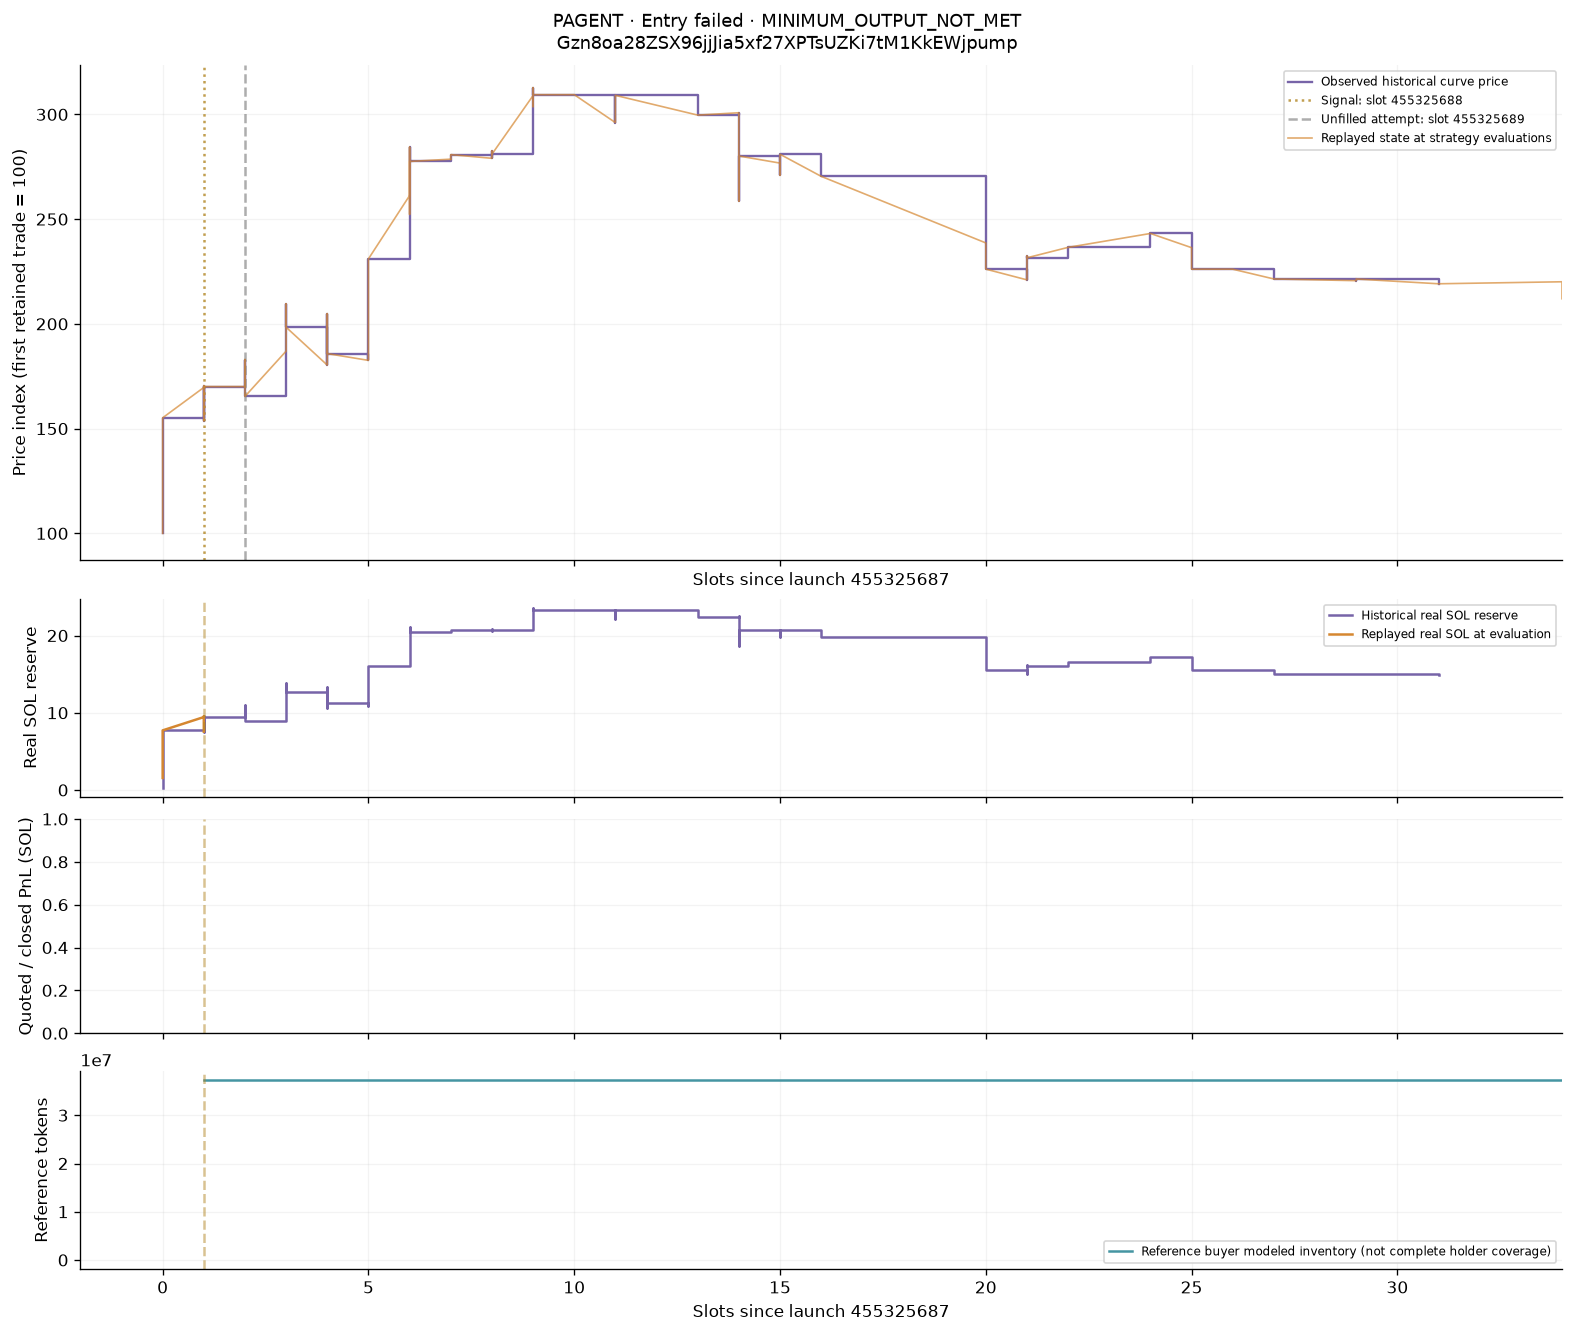

[GMGN token](https://gmgn.ai/sol/token/Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump) · [Reference buyer](https://gmgn.ai/sol/address/DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA) · [Creator](https://gmgn.ai/sol/address/BoHoQfXZWdDYqwiqhePiQAXdu6NqQvjPibBGwqRvXTAL)

,field,recorded_value
0,signal_slot,455325688
1,entry_slot,None
2,exit_signal_slot,None
3,exit_slot,None
4,reason,MINIMUM_OUTPUT_NOT_MET
5,budget_lamports,988431700
6,entry_cash_sol,0.000000000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,1.748138077
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump
symbol,PAGENT
boundary_ordinal,1955608938988700972
slot,455325688
time,1791650655
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,5
virtual_sol,37553667929


**Exit decision**

No completed exit decision; inspect the recorded failure/conflict below.

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955608938988700972,455325688,1791650655,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,5,37553667929,857173261175492,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,37259951499482,1748138077,1748138077,0,,,,,,,,,BUY,5b07225bc2c54ae196969267483bc1684aa6057e653b67025451b6084495949d,[],0,,,,,
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955608943283666944,455325689,1791650655,ORDER_EXECUTION_FAILED,PENDING_BUY,SIGNAL,6,39491992135,815101955296752,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,37259951499482,1748138077,1748138077,0,,,,,,,,,BUY,5b07225bc2c54ae196969267483bc1684aa6057e653b67025451b6084495949d,"[""MINIMUM_OUTPUT_NOT_MET""]",105000,,,,,
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955609875291570290,455325906,1791650703,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,31578516660,1019363905183662,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,0,541771333,541771333,0,,,,,,,,,,,,,,,,,
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955609922536211095,455325917,1791650706,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,31385139471,1025644639659727,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,0,541771333,541771333,0,,,,,,,,,,,,,,,,,
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955609944011047480,455325922,1791650707,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,31341490564,1027073042302447,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,0,541771333,541771333,0,,,,,,,,,,,,,,,,,
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955609965485883553,455325927,1791650708,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,31296008309,1028565679888252,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,0,541771333,541771333,0,,,,,,,,,,,,,,,,,
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955610175939281708,455325976,1791650719,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,31214788486,1031241972976175,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,0,541771333,541771333,0,,,,,,,,,,,,,,,,,
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955610309083267739,455326007,1791650726,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,31033751453,1037257777669248,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,0,541771333,541771333,0,,,,,,,,,,,,,,,,,
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955611322695549190,455326243,1791650777,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,30538671689,1054073353073946,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,0,541771333,541771333,0,,,,,,,,,,,,,,,,,
Gzn8oa28ZSX96jjJia5xf27XPTsUZKi7tM1KkEWjpump,PAGENT,1955612581120968277,455326536,1791650841,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,30418428482,1058240075908394,DsGJkPzFEQZuwy7JjZzPcJEyEfdC6StV7rarXG4ftRSA,,,0,541771333,541771333,0,,,,,,,,,,,,,,,,,


---

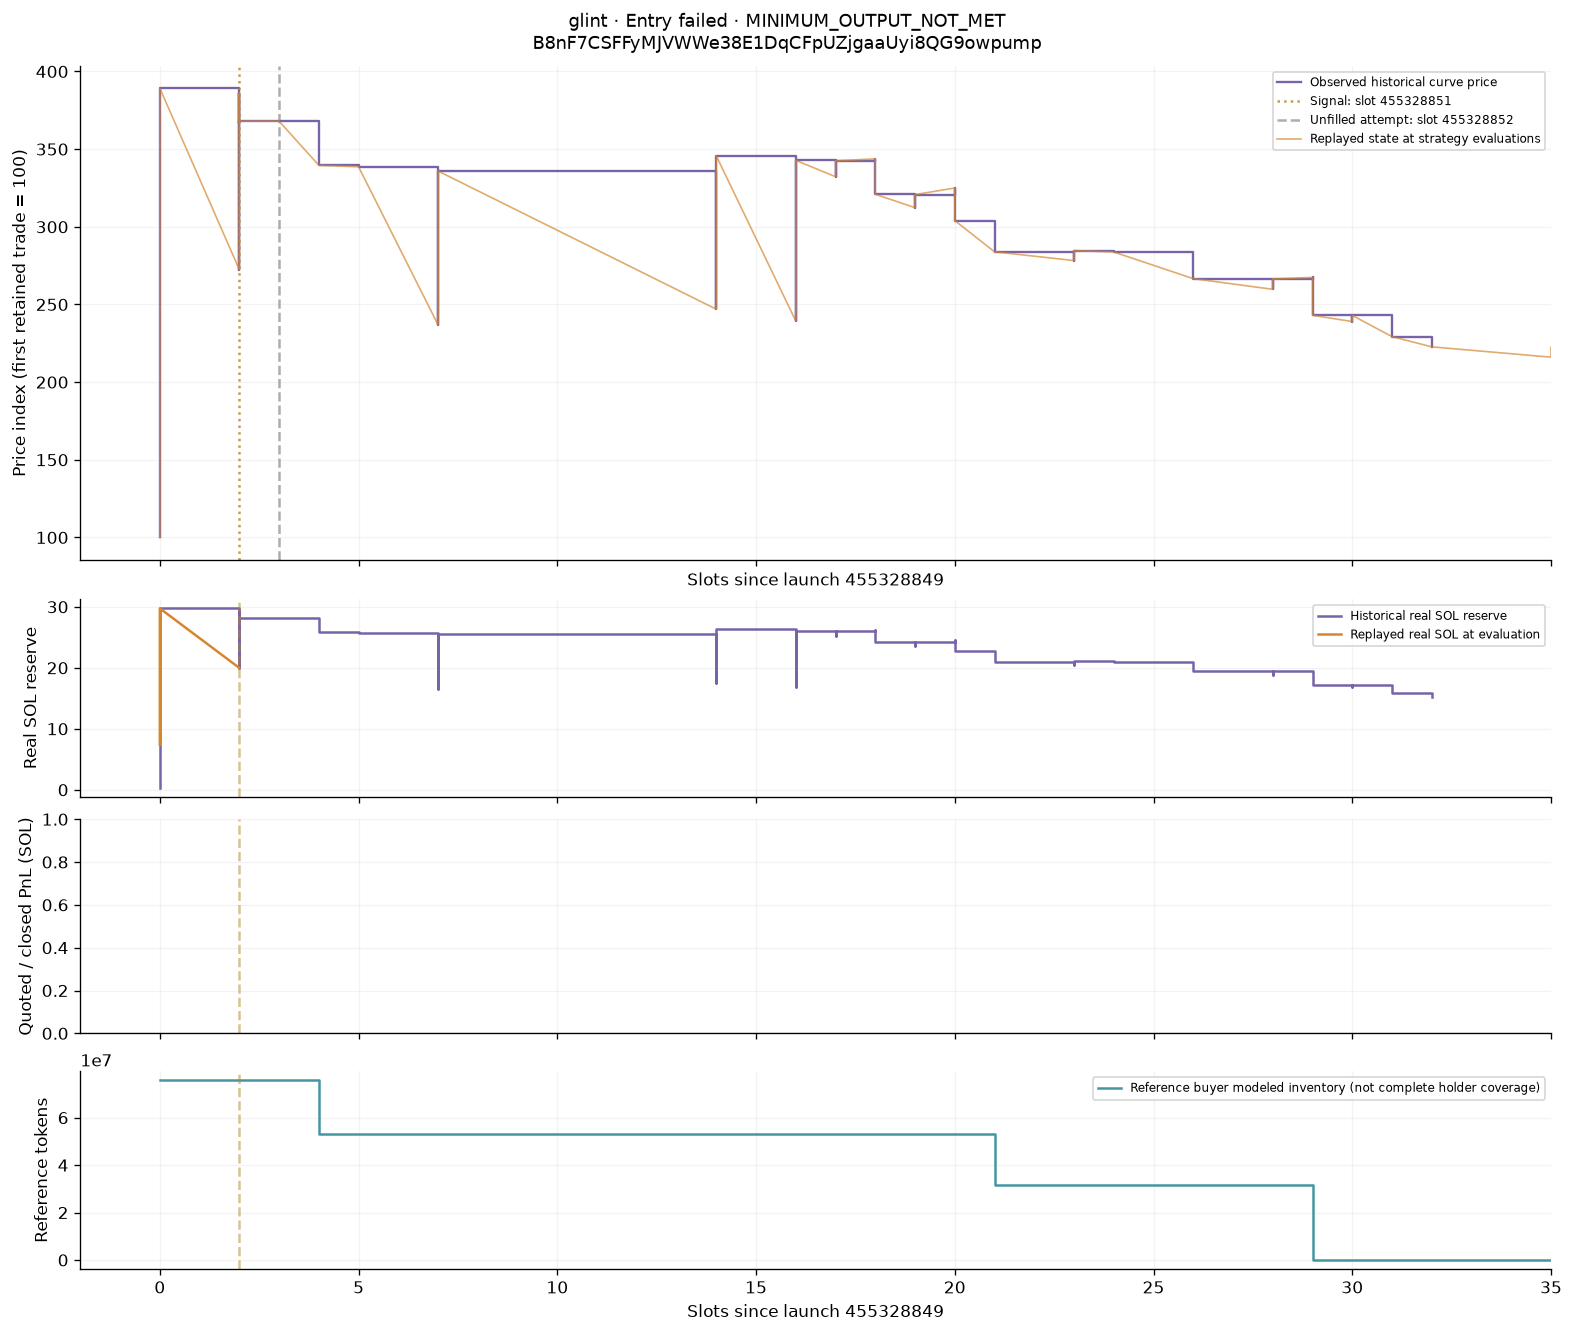

[GMGN token](https://gmgn.ai/sol/token/B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump) · [Reference buyer](https://gmgn.ai/sol/address/CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB) · [Creator](https://gmgn.ai/sol/address/HgJpRjr4rUMcF4W31k9cvGTF6bnb9hRLfFcyEZ3dxGEp)

,field,recorded_value
0,signal_slot,455328851
1,entry_slot,None
2,exit_signal_slot,None
3,exit_slot,None
4,reason,MINIMUM_OUTPUT_NOT_MET
5,budget_lamports,6409921441
6,entry_cash_sol,0.000000000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,7.005005000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump
symbol,glint
boundary_ordinal,1955622523970257090
slot,455328851
time,1791651345
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,4
virtual_sol,49982210555


**Exit decision**

No completed exit decision; inspect the recorded failure/conflict below.

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955622523970257090,455328851,1791651345,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,4,49982210555,644029138504098,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,75758166272146,7005005000,7005005000,0,,,,,,,,,BUY,2b76afa4de3b123fb138a77f4d0a347e66b24b6ede77fcb527d9e56f15c9e14b,[],0,,,,,
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955622528265224192,455328852,1791651345,ORDER_EXECUTION_FAILED,PENDING_BUY,SIGNAL,6,58092957540,554111915941241,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,75758166272146,7005005000,7005005000,0,,,,,,,,,BUY,2b76afa4de3b123fb138a77f4d0a347e66b24b6ede77fcb527d9e56f15c9e14b,"[""MINIMUM_OUTPUT_NOT_MET""]",105000,,,,,
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955626896246964738,455329869,1791651566,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,32748845399,982935419269214,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,0,713756630,713756630,0,,,,,,,,,,,,,,,,,
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955627321448726623,455329968,1791651588,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,32655788968,985736406941519,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,0,713756630,713756630,0,,,,,,,,,,,,,,,,,
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955627325743693895,455329969,1791651588,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,32654882845,985763759643940,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,0,713756630,713756630,0,,,,,,,,,,,,,,,,,
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955627325743693899,455329969,1791651588,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,32653977480,985791090964202,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,0,713756630,713756630,0,,,,,,,,,,,,,,,,,
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955627398758138595,455329986,1791651591,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,32503105569,990366905613482,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,0,713756630,713756630,0,,,,,,,,,,,,,,,,,
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955627398758138798,455329986,1791651591,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,31303005293,1028335771093292,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,0,713756630,713756630,0,,,,,,,,,,,,,,,,,
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955627403053105868,455329987,1791651592,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,31219720169,1031079071549320,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,0,713756630,713756630,0,,,,,,,,,,,,,,,,,
B8nF7CSFFyMJVWWe38E1DqCFpUZjgaaUyi8QG9owpump,glint,1955627403053105939,455329987,1791651592,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,31005671181,1038197170396524,CRmNd78MbEGEqZe4NjRFJSUWFF97GR4oDjVi6oESB7BB,,,0,713756630,713756630,0,,,,,,,,,,,,,,,,,


---

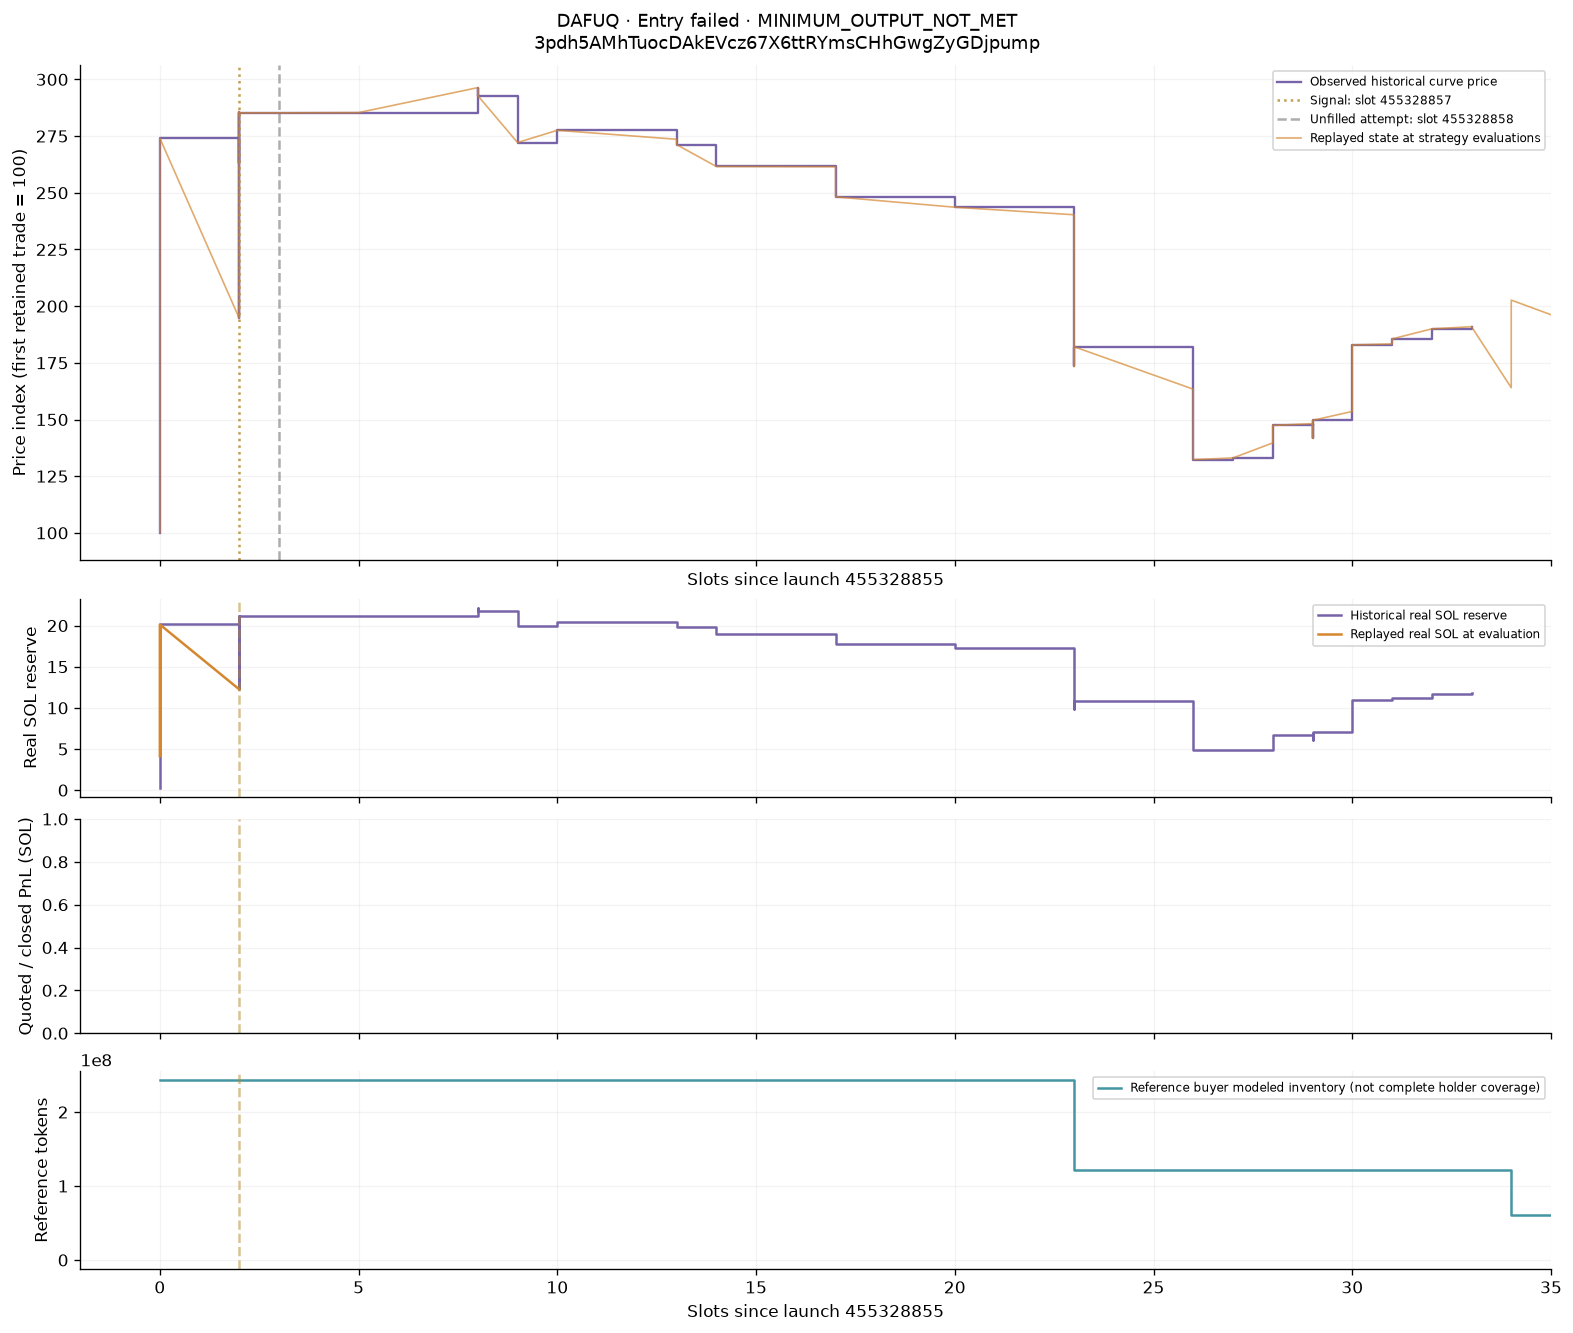

[GMGN token](https://gmgn.ai/sol/token/3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump) · [Reference buyer](https://gmgn.ai/sol/address/6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk) · [Creator](https://gmgn.ai/sol/address/2NgU4hPqYeGGHxKuoCXz5WrGW6mUAQAoctGAohD2rq8X)

,field,recorded_value
0,signal_slot,455328857
1,entry_slot,None
2,exit_signal_slot,None
3,exit_slot,None
4,reason,MINIMUM_OUTPUT_NOT_MET
5,budget_lamports,2818437480
6,entry_cash_sol,0.000000000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,12.055005000
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump
symbol,DAFUQ
boundary_ordinal,1955622549740061169
slot,455328857
time,1791651346
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,3
virtual_sol,42240935725


**Exit decision**

No completed exit decision; inspect the recorded failure/conflict below.

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955622549740061169,455328857,1791651346,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,3,42240935725,762056982160961,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,243028533819722,12055005000,12055005000,0,,,,,,,,,BUY,f994b102ff9169aeb59e2fe065fb2b3e5b8779b3d326368fa23301c1a180416e,[],0,,,,,
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955622554035027968,455328858,1791651346,ORDER_EXECUTION_FAILED,PENDING_BUY,SIGNAL,6,51144657100,629391256696680,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,243028533819722,12055005000,12055005000,0,,,,,,,,,BUY,f994b102ff9169aeb59e2fe065fb2b3e5b8779b3d326368fa23301c1a180416e,"[""MINIMUM_OUTPUT_NOT_MET""]",105000,,,,,
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955623348603977839,455329043,1791651386,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,34802369957,924937011342204,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,0,-1106961953,-1106961953,0,,,,,,,,,,,,,,,,,
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955623434503323869,455329063,1791651390,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,34851752672,923626434475269,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,0,-1106961953,-1106961953,0,,,,,,,,,,,,,,,,,
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955623889769857660,455329169,1791651413,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,35019653906,919198120660391,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,0,-1106961953,-1106961953,0,,,,,,,,,,,,,,,,,
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955624010028941460,455329197,1791651420,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,34663826591,928633772504831,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,0,-1106961953,-1106961953,0,,,,,,,,,,,,,,,,,
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955624551194820968,455329323,1791651447,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,34614974626,929944349371766,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,0,-1106961953,-1106961953,0,,,,,,,,,,,,,,,,,
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955625058000962499,455329441,1791651473,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,30208214543,1065604192254407,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,0,-1106961953,-1106961953,0,,,,,,,,,,,,,,,,,
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955625062295929051,455329442,1791651474,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,30775084741,1045976000699758,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,0,-1106961953,-1106961953,0,,,,,,,,,,,,,,,,,
3pdh5AMhTuocDAkEVcz67X6ttRYmsCHhGwgZyGDjpump,DAFUQ,1955628730198000720,455330296,1791651658,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,6,30872862518,1042663278821718,6Qq8RhAHeB4FUfNtDQVxALEQjHZxhT3k2wjxfgMxKxCk,,,0,-1106961953,-1106961953,0,,,,,,,,,,,,,,,,,


---

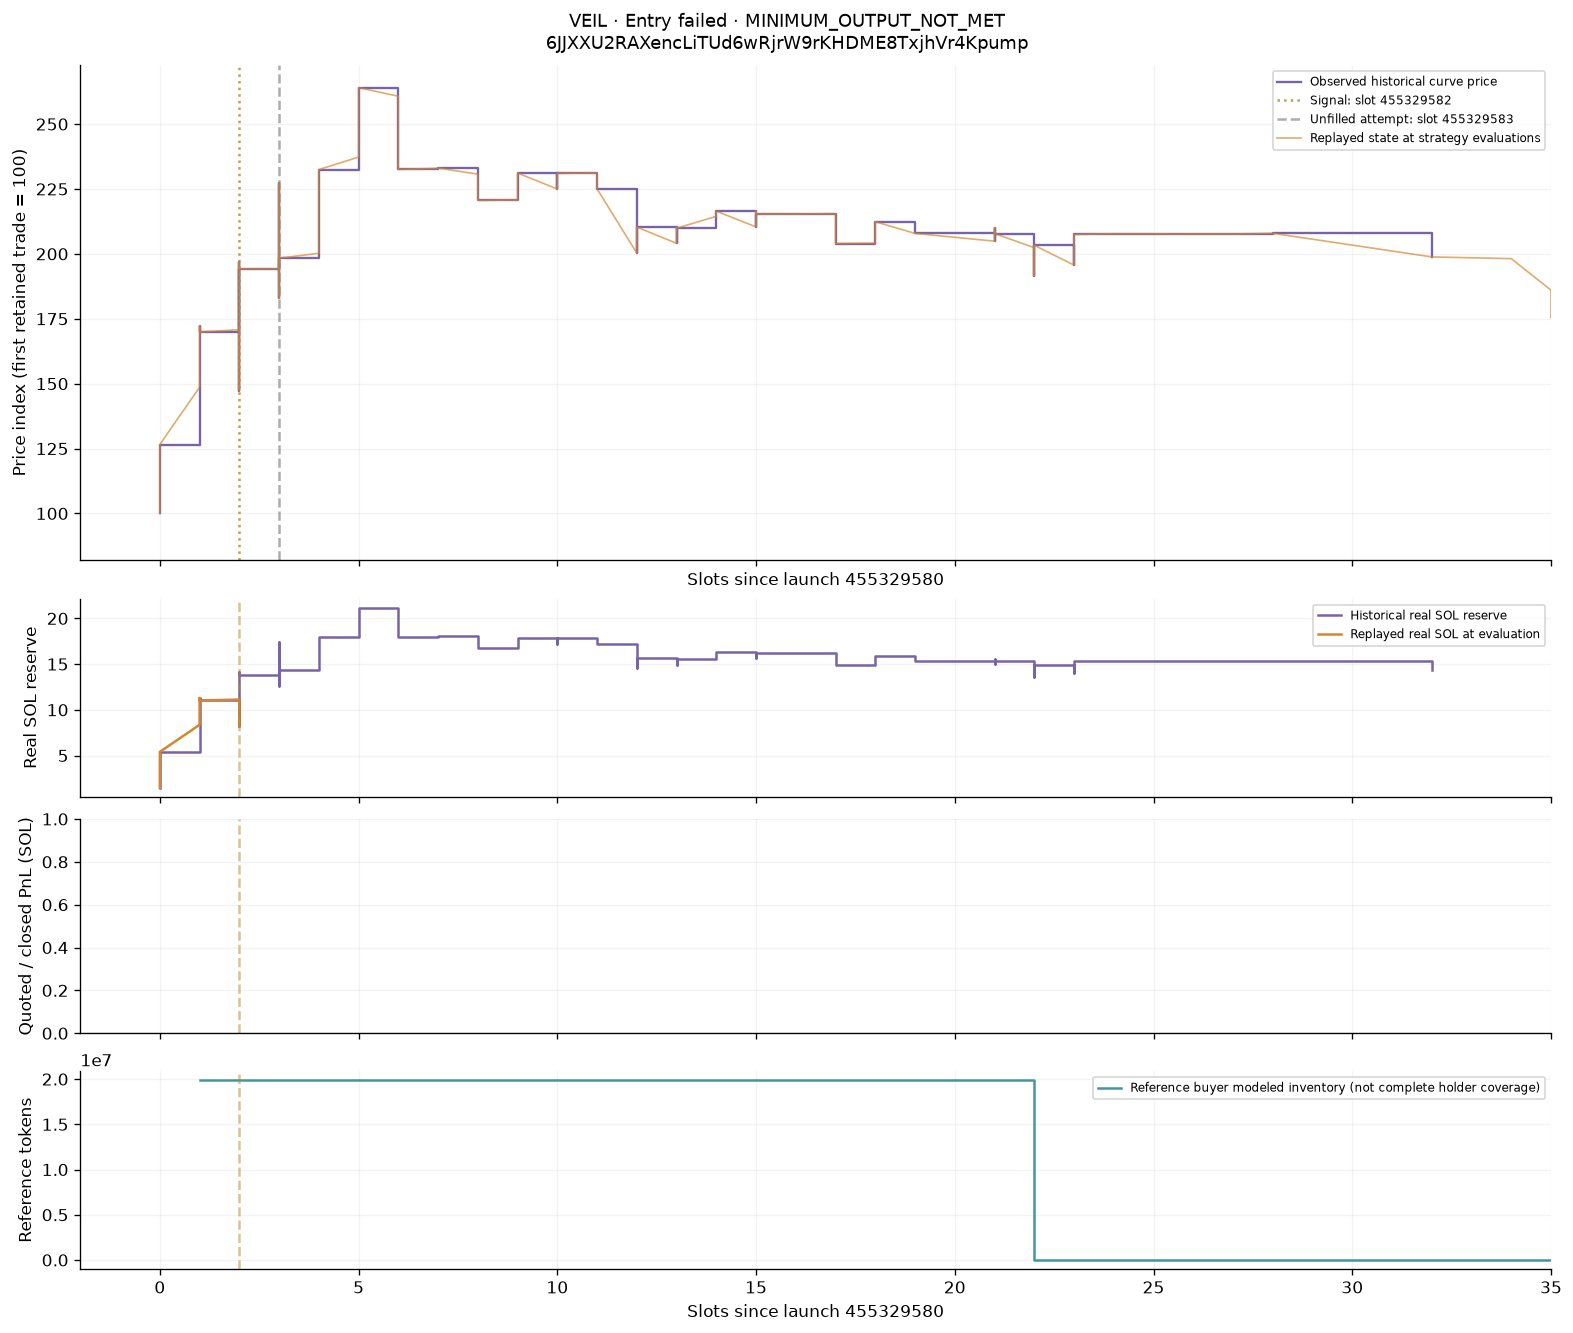

[GMGN token](https://gmgn.ai/sol/token/6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump) · [Reference buyer](https://gmgn.ai/sol/address/5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy) · [Creator](https://gmgn.ai/sol/address/5TvaAhPCMQ2ZD2GDrmHgwZW31B87k7yViDBZfxKnTU1w)

,field,recorded_value
0,signal_slot,455329582
1,entry_slot,None
2,exit_signal_slot,None
3,exit_slot,None
4,reason,MINIMUM_OUTPUT_NOT_MET
5,budget_lamports,1394240175
6,entry_cash_sol,0.000000000
7,closed_pnl_sol,None
8,sniper_trading_cash_cost_sol,1.004254572
9,sniper_creator_fee_income_sol,0.000000000


**Entry signal: recorded sizing, inventories, costs, reserves and minimum output**

,recorded_value
mint,6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump
symbol,VEIL
boundary_ordinal,1955625663591350638
slot,455329582
time,1791651504
action,ENTRY_SIGNAL
status,PENDING_BUY
reason,SIGNAL
eligible_wallets,5
virtual_sol,38197020424


**Exit decision**

No completed exit decision; inspect the recorded failure/conflict below.

**Entry candidates, native order notifications and final exit evaluations** (all rows are saved in the per-token decisions CSV).

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955625663591350638,455329582,1791651504,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,5,38197020424,842735890198413,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,19878265515780,1004254572,1004254572,0,,,,,,,,,BUY,16673921d9db2d02e198b3555c68d126af57bc01f035a2dedfb8301971319d81,[],0,,,,,
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955625667886317568,455329583,1791651504,ORDER_EXECUTION_FAILED,PENDING_BUY,SIGNAL,7,43855695100,733998171543208,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,19878265515780,1004254572,1004254572,0,,,,,,,,,BUY,16673921d9db2d02e198b3555c68d126af57bc01f035a2dedfb8301971319d81,"[""MINIMUM_OUTPUT_NOT_MET""]",105000,,,,,
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955628206211990342,455330174,1791651631,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,32316427588,996087826274359,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,0,-184732615,-184732615,0,,,,,,,,,,,,,,,,,
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955628373715714257,455330213,1791651640,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,32131402037,1001823701067015,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,0,-184732615,-184732615,0,,,,,,,,,,,,,,,,,
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955628609938915680,455330268,1791651652,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,32106800183,1002591349079000,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,0,-184732615,-184732615,0,,,,,,,,,,,,,,,,,
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955628700133229120,455330289,1791651657,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,31655666962,1016879541644606,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,0,-184732615,-184732615,0,,,,,,,,,,,,,,,,,
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955628820392313310,455330317,1791651662,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,31449618940,1023541816935626,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,0,-184732615,-184732615,0,,,,,,,,,,,,,,,,,
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955628820392313454,455330317,1791651662,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,31224370288,1030925517967270,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,0,-184732615,-184732615,0,,,,,,,,,,,,,,,,,
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955628820392313585,455330317,1791651662,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,31018692502,1037761347008709,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,0,-184732615,-184732615,0,,,,,,,,,,,,,,,,,
6JJXXU2RAXencLiTUd6wRjrW9rKHDME8TxjhVr4Kpump,VEIL,1955628979306102926,455330354,1791651670,ENTRY_INELIGIBLE,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,7,30961563762,1039676172721578,5bb5kQKhp4zT3MYuFp7QSpkvJkghfLp6yjQbvTDLK2vy,,,0,-184732615,-184732615,0,,,,,,,,,,,,,,,,,


In [8]:
selected = review.ENTRY_EXIT[review.ENTRY_EXIT['group'] == 'Entry failed']
review.linked_table(selected[columns])
for mint in selected['mint']:
    display(Markdown('---'))
    review.inspect(mint)

## Optional inspector: every logged evaluation for one token

Change `TOKEN` to a mint from the table and rerun this cell. The saved example
shows UP's final decision checks. Set `ALL_ROWS=True` to display its complete log.

In [9]:
TOKEN = '2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump'
ALL_ROWS = False
review.linked_table(review.decisions(TOKEN, all_rows=ALL_ROWS))

mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,virtual_sol,virtual_tokens,wallet,budget_lamports,real_sol,wallet_tokens,wallet_cash_cost,wallet_adjusted_cost,wallet_creator_fee_income,xs,xt,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622309221893142,455328801,1791651334,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,7,51920088869,619991234704306,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,,61059511879992,5200005000,5200005000,0,,,,,,,,,BUY,341ab827c2d6caf5bf375ea098defba9379999752d62eb9ee0f22caf498b842a,[],0,,,,,
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622313516859392,455328802,1791651334,ORDER_FILLED,PENDING_BUY,SIGNAL,7,53358856175,603273801437926,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,,61059511879992,5200005000,5200005000,0,,,,,,,,,BUY,341ab827c2d6caf5bf375ea098defba9379999752d62eb9ee0f22caf498b842a,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622644229341490,455328879,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,46848396014,687109972201014,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,16848396014,0,871300436,871300436,0,,,,,,,,,,,,,-355687711,72342845,False,1105087787,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622644229341590,455328879,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,46947161445,685664459633813,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,16947161445,0,871300436,871300436,0,,,,,,,,,,,,,-351136123,72342845,False,1109696990,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622644229341634,455328879,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,46002073659,699751066058630,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,16002073659,0,871300436,871300436,0,,,,,,,,,,,,,-394311027,72342845,False,1065975568,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622644229341773,455328879,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,47273184769,680935719515619,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,17273184769,0,871300436,871300436,0,,,,,,,,,,,,,-336045765,72342845,False,1124978366,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622648524308480,455328880,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,47273184769,680935719515619,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,17273184769,0,871300436,871300436,0,,,,,,,,,,,,,-336045765,72342845,False,1124978366,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622648524308575,455328880,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,49228740324,653886324802718,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,19228740324,0,871300436,871300436,0,,,,,,,,,,,,,-243418721,72342845,False,1218777904,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622648524308576,455328880,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,52668004078,611187012858468,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,22668004078,0,871300436,871300436,0,,,,,,,,,,,,,-71756933,72342845,False,1392612625,0
2y6MTtkMkHdSP51enRDJay25NKLgGo5mX7ZVW6KEpump,up,1955622648524308956,455328880,1791651351,EXIT_EVALUATION,OPEN,HOLDING,7,59186522596,543873819144932,3bTYzG94soZcUPD3qX3JGv6AY5Vp1dhGi9GxorbbzH7s,,29186522596,0,871300436,871300436,0,,,,,,,,,,,,,284051512,72342845,False,1752924975,0


## Evidence, exports and reproduction

The original result is `var/dnipro/sniper-inventory-repair-20261015-v1/repaired-v3`.
The equal full-trace result is its sibling `development-repaired-before`.
No revised entry/exit strategy or additional date sample is mixed into this study.

The remaining unresolved token is 毒チワワ. The real sender transfers
158,769.203521 tokens; its simulated earlier buy obtains 155,358.106307 tokens,
a 3,411.097214-token shortfall. Fixed transfer replay stops at that conflict.
The real historical sale is verified; this is not evidence that our own sell
was submitted and failed. Scaling that transfer is a separate behavioral assumption.

Exports are under `var/dnipro/sniper-repaired-review-20261015-v1/`:
`all_positions_entry_exit.csv`, `native_fill_markers.csv`, `decision_log_all.csv`,
`pnl_events.csv`, `cash_events.csv`, result-group CSVs, and `chart_index.csv`.
Each token has a PNG, a complete decision-log CSV and a JSON containing its full
position metadata, entry signal, exit evaluation and counterparty errors.
The receipt pins hashes and validates 38 charts, 29 buy markers and 28 sell markers.

Use **Python 3.13.12 (Sniper research)** to rerun notebook cells. Saved outputs
are already rendered, so reading the notebook does not require executing it.

In [10]:
receipt = review.save_receipt()
display({k:v for k,v in receipt.items() if k != 'output_hashes'})
print('Verified 38 charts, all signal logs, 29 buys, 28 exits and unchanged repaired PnL.')

{'complete': True,
 'native_run': 'development-repaired-before',
 'result_sha256': '0b8c085a67f2b3e77d6c33cacf346adebbbf3a88a85eb347e0807ac3d30e5d53',
 'exact_economic_parity_with_repaired_v3': True,
 'all_signal_traces_recorded': True,
 'source_manifest_hashes': {'development': 'db5db9010ebb8b1f16f42af488a105277b22e7133986903b85aaf9125e8e0f25'},
 'signals': 38,
 'chart_count': 38,
 'buy_markers': 29,
 'sell_markers': 28,
 'realized_net_PnL_lamports': -3289255885,
 'unresolved_cost_lamports': 1207495000,
 'final_portfolio_PnL_lamports': None}

Verified 38 charts, all signal logs, 29 buys, 28 exits and unchanged repaired PnL.
